In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from xgboost.sklearn import XGBRegressor
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import re
from xgboost import DMatrix


In [2]:
DATA_DIR = Path("scrabble-player-rating")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
games = pd.read_csv(DATA_DIR / "games.csv")
turns = pd.read_csv(DATA_DIR / "turns.csv")
#print("Working directory:", Path.cwd())
#print("Data directory exists:", DATA_DIR.exists())

In [3]:
datasets = {
    "train": train,
    "test": test,
    "games": games,
    "turns": turns,
}
for name, df in datasets.items():
    print(f"\n{'=' * 15} {name.upper()} {'=' * 15}")

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)


=============== TRAIN ===============

Missing values:
game_id     0
nickname    0
score       0
rating      0
dtype: int64

Duplicate rows: 0

Data types:
game_id     int64
nickname      str
score       int64
rating      int64
dtype: object

=============== TEST ===============

Missing values:
game_id         0
nickname        0
score           0
rating      22363
dtype: int64

Duplicate rows: 0

Data types:
game_id       int64
nickname        str
score         int64
rating      float64
dtype: object

=============== GAMES ===============

Missing values:
game_id                  0
first                    0
time_control_name        0
game_end_reason          0
winner                   0
created_at               0
lexicon                  0
initial_time_seconds     0
increment_seconds        0
rating_mode              0
max_overtime_minutes     0
game_duration_seconds    0
dtype: int64

Duplicate rows: 0

Data types:
game_id                    int64
first                        str


In [4]:
turn_features = (
    turns.groupby(["game_id", "nickname"])
    .agg(
        num_turns=("points", "count"),
        avg_points=("points", "mean"),
        max_points=("points", "max"),
        total_points=("points", "sum"),
        std_points=("points", "std")
    )
    .reset_index()
)
train_merged = (
    train
    .merge(
        games,
        on="game_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        turn_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

print("Original rows:", len(train))
print("Merged rows:", len(train_merged))
print(train_merged[[
    "nickname",
    "rating",
    "game_duration_seconds",
    "avg_points"
]].head())

Original rows: 100820
Merged rows: 100820
         nickname  rating  game_duration_seconds  avg_points
0       BetterBot    1637             674.844274   25.769231
1           stevy    1500             674.844274   30.642857
2       davidavid    1811             492.268262   31.428571
3       BetterBot    2071             492.268262   24.461538
4  Inandoutworker    1473             350.861141    8.500000


In [5]:

# Target split:
# Train:      70%
# Validation: 15%
# Holdout:    15%
#


BOTS = {
    "BetterBot",
    "HastyBot",
    "STEEBot",
    "BB-8"
}

VAL_RATIO = 0.15
HOLDOUT_RATIO = 0.15
RANDOM_STATE = 42

assert VAL_RATIO > 0
assert HOLDOUT_RATIO > 0
assert VAL_RATIO + HOLDOUT_RATIO < 1

# Only labeled training games
game_ids = train_merged["game_id"].drop_duplicates().to_numpy()

labeled_games = set(game_ids)

# Cell 17 constructs score_pairs later. For splitting, use the raw
# player-game identities directly; both tables have the same identities.
human_rows = train_merged.loc[
    train_merged["game_id"].isin(labeled_games)
    & ~train_merged["nickname"].isin(BOTS),
    ["game_id", "nickname"]
].drop_duplicates()

assert not human_rows["nickname"].isna().any()

#  Union find:
# connect every game sharing a human player


parent = {game_id: game_id for game_id in game_ids}
size = {game_id: 1 for game_id in game_ids}

def find(game_id):
    if parent[game_id] != game_id:
        parent[game_id] = find(parent[game_id])
    return parent[game_id]

def union(game_a, game_b):
    root_a = find(game_a)
    root_b = find(game_b)

    if root_a == root_b:
        return

    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a

    parent[root_b] = root_a
    size[root_a] += size[root_b]


first_game_for_player = {}

for game_id, nickname in human_rows.itertuples(
    index=False, name=None
):
    if nickname in first_game_for_player:
        union(
            game_id,
            first_game_for_player[nickname]
        )
    else:
        first_game_for_player[nickname] = game_id

# Every connected component must stay within one split
game_groups = np.array(
    [find(game_id) for game_id in game_ids]
)

n_groups = len(set(game_groups))

print("Independent player/game groups:", n_groups)

assert n_groups >= 3, (
    "Not enough independent groups for three-way splitting."
)



holdout_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=HOLDOUT_RATIO,
    random_state=RANDOM_STATE
)

development_idx, holdout_idx = next(
    holdout_splitter.split(
        game_ids,
        groups=game_groups
    )
)

holdout_game_ids = set(
    game_ids[holdout_idx]
)

development_games = game_ids[development_idx]
development_groups = game_groups[development_idx]



relative_val_ratio = (
    VAL_RATIO / (1 - HOLDOUT_RATIO)
)

validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=relative_val_ratio,
    random_state=RANDOM_STATE + 1
)

train_idx, val_idx = next(
    validation_splitter.split(
        development_games,
        groups=development_groups
    )
)

train_game_ids = set(
    development_games[train_idx]
)

val_game_ids = set(
    development_games[val_idx]
)


assert train_game_ids.isdisjoint(val_game_ids), (
    "Train/validation game leakage!"
)

assert train_game_ids.isdisjoint(holdout_game_ids), (
    "Train/holdout game leakage!"
)

assert val_game_ids.isdisjoint(holdout_game_ids), (
    "Validation/holdout game leakage!"
)

assert (
    train_game_ids
    | val_game_ids
    | holdout_game_ids
) == labeled_games, "Not all labeled games were assigned!"



def players_in(game_set):
    return set(
        human_rows.loc[
            human_rows["game_id"].isin(game_set),
            "nickname"
        ]
    )

train_players = players_in(train_game_ids)
val_players = players_in(val_game_ids)
holdout_players = players_in(holdout_game_ids)

assert train_players.isdisjoint(val_players), (
    "Train/validation player leakage!"
)

assert train_players.isdisjoint(holdout_players), (
    "Train/holdout player leakage!"
)

assert val_players.isdisjoint(holdout_players), (
    "Validation/holdout player leakage!"
)



train_eda = train_merged.loc[
    train_merged["game_id"].isin(train_game_ids)
].copy()

val_eda = train_merged.loc[
    train_merged["game_id"].isin(val_game_ids)
].copy()

holdout_eda = train_merged.loc[
    train_merged["game_id"].isin(holdout_game_ids)
].copy()



split_summary = pd.DataFrame([
    {
        "Split": "Training",
        "Games": len(train_game_ids),
        "Human players": len(train_players),
        "Fraction": len(train_game_ids) / len(game_ids)
    },
    {
        "Split": "Validation",
        "Games": len(val_game_ids),
        "Human players": len(val_players),
        "Fraction": len(val_game_ids) / len(game_ids)
    },
    {
        "Split": "Holdout",
        "Games": len(holdout_game_ids),
        "Human players": len(holdout_players),
        "Fraction": len(holdout_game_ids) / len(game_ids)
    }
])

display(split_summary)

print("\nSPLIT VERIFICATION")
print("=" * 55)

print("Overlapping train/val games:",
      len(train_game_ids & val_game_ids))

print("Overlapping train/val players:",
      len(train_players & val_players))

print("Overlapping train/holdout players:",
      len(train_players & holdout_players))

print("Overlapping val/holdout players:",
      len(val_players & holdout_players))

print("\nSUCCESS: All three sets are player/game-disjoint.")
print("Kaggle test.csv was NOT accessed.")


Independent player/game groups: 7603


,Split,Games,Human players,Fraction
0,Training,35176,719,0.697798
1,Validation,5978,143,0.118588
2,Holdout,9256,165,0.183614



SPLIT VERIFICATION
Overlapping train/val games: 0
Overlapping train/val players: 0
Overlapping train/holdout players: 0
Overlapping val/holdout players: 0

SUCCESS: All three sets are player/game-disjoint.
Kaggle test.csv was NOT accessed.


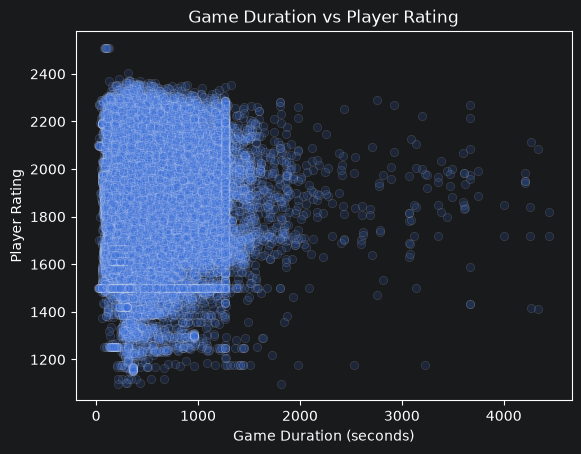

time_control_name
regular       59856
blitz          5646
rapid          4526
ultrablitz      324
Name: count, dtype: int64


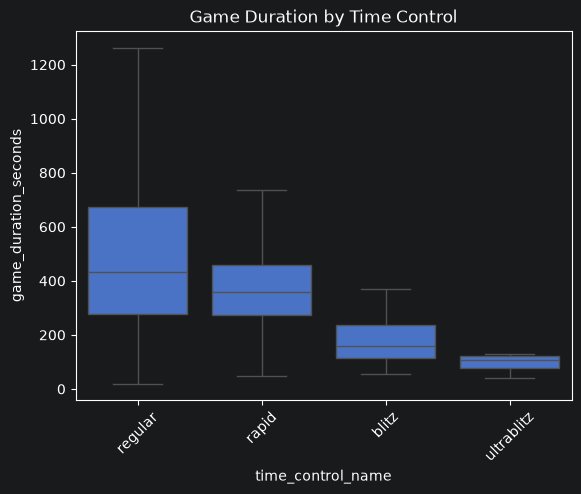

In [6]:
eda_df = train_eda.dropna(
    subset=["rating", "game_duration_seconds"]
).copy()

sns.scatterplot(
    data=eda_df,
    x="game_duration_seconds",
    y="rating",
    alpha=0.15
)

plt.title("Game Duration vs Player Rating")
plt.xlabel("Game Duration (seconds)")
plt.ylabel("Player Rating")
plt.show()

print(eda_df["time_control_name"].value_counts())

sns.boxplot(
    data=eda_df,
    x="time_control_name",
    y="game_duration_seconds",
    showfliers=False
)

plt.xticks(rotation=45)
plt.title("Game Duration by Time Control")
plt.show()

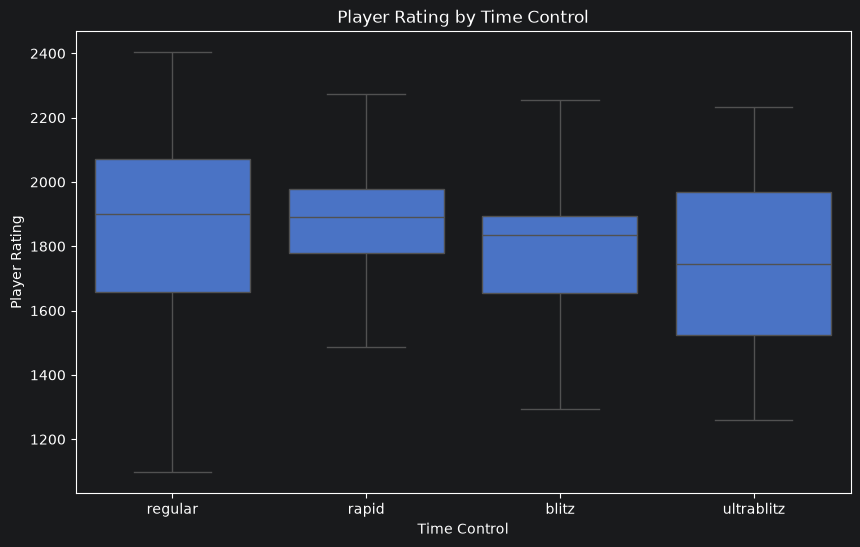

,count,mean,median,std
time_control_name,,,,
blitz,5646,1802.61,1835.0,178.58
rapid,4526,1882.36,1891.0,177.90
regular,59856,1871.64,1901.0,236.41
ultrablitz,324,1777.62,1744.5,256.33


In [7]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=eda_df,
    x="time_control_name",
    y="rating",
    showfliers=False
)

plt.title("Player Rating by Time Control")
plt.xlabel("Time Control")
plt.ylabel("Player Rating")
plt.show()
rating_by_time = (
    eda_df.groupby("time_control_name")["rating"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(rating_by_time)

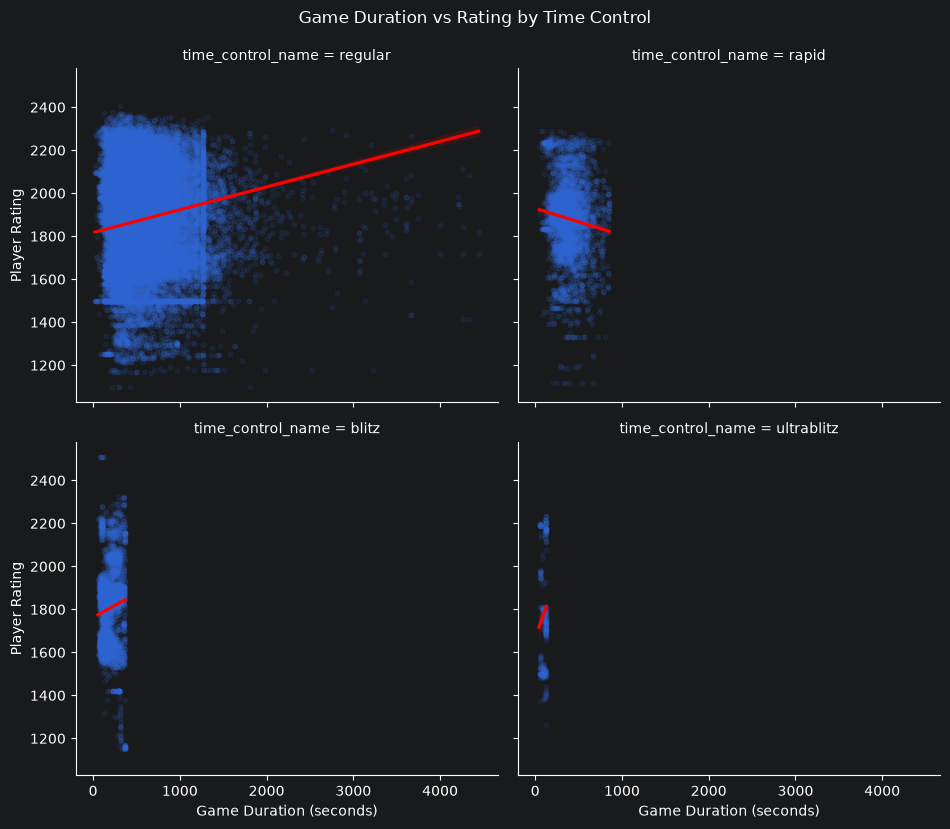

time_control_name
blitz         0.098207
rapid        -0.102737
regular       0.144056
ultrablitz    0.107053
dtype: float64


In [8]:
g = sns.lmplot(
    data=eda_df,
    x="game_duration_seconds",
    y="rating",
    col="time_control_name",
    col_wrap=2,
    scatter_kws={"alpha": 0.1, "s": 10},
    line_kws={"color": "red"},
    height=4,
    aspect=1.2
)

g.set_axis_labels("Game Duration (seconds)", "Player Rating")
g.fig.suptitle("Game Duration vs Rating by Time Control", y=1.03)

plt.show()
correlations = (
    eda_df.groupby("time_control_name")
    .apply(
        lambda group: group["game_duration_seconds"]
        .corr(group["rating"]),
        include_groups=False
    )
)

print(correlations)

In [9]:
results = []

for mode, group in eda_df.groupby("time_control_name"):
    results.append({
        "time_control": mode,
        "n_games": len(group),
        "pearson": group["game_duration_seconds"].corr(
            group["rating"], method="pearson"
        ),
        "spearman": group["game_duration_seconds"].corr(
            group["rating"], method="spearman"
        )
    })

correlation_results = pd.DataFrame(results)

display(correlation_results.round(3))

,time_control,n_games,pearson,spearman
0,blitz,5646,0.098,0.123
1,rapid,4526,-0.103,-0.094
2,regular,59856,0.144,0.225
3,ultrablitz,324,0.107,0.109


avg_points               0.478497
score                    0.422097
total_points             0.422097
game_duration_seconds    0.238166
max_points               0.230262
std_points               0.198500
num_turns               -0.272831
Name: rating, dtype: float64

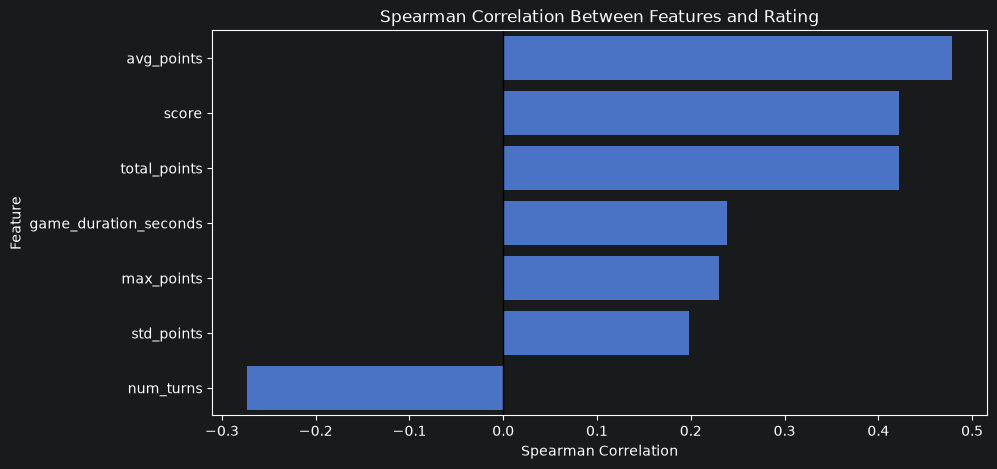

In [10]:
numeric_features = [
    "score",
    "num_turns",
    "avg_points",
    "max_points",
    "total_points",
    "std_points",
    "game_duration_seconds"
]

correlations = (
    train_eda[numeric_features + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(correlations)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Spearman Correlation Between Features and Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")

plt.axvline(0, color="black", linewidth=1)
plt.show()

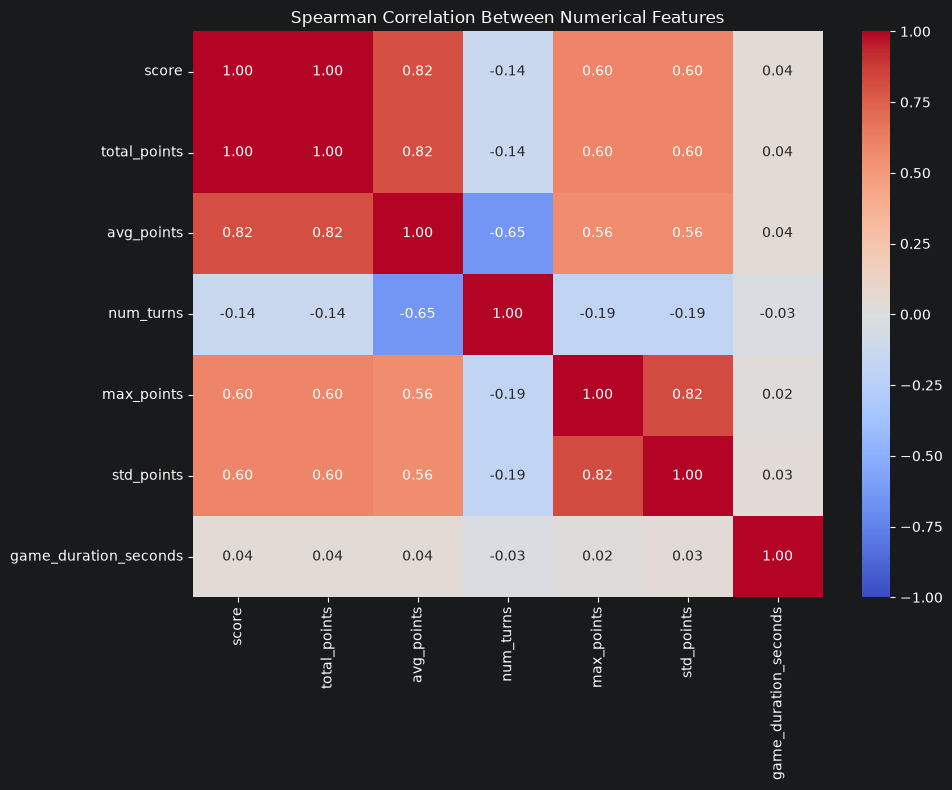

In [11]:
features = [
    "score",
    "total_points",
    "avg_points",
    "num_turns",
    "max_points",
    "std_points",
    "game_duration_seconds"
]

corr_matrix = train_eda[features].corr(method="spearman")

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [12]:
feature_summary = pd.DataFrame({
    "dtype": train_eda.dtypes.astype(str),
    "unique_values": train_eda.nunique(),
    "example": train_eda.iloc[0]
})

display(feature_summary.sort_values("unique_values"))

,dtype,unique_values,example
rating_mode,str,2,CASUAL
winner,int64,3,1
game_end_reason,str,4,STANDARD
time_control_name,str,4,regular
lexicon,str,4,NWL20
max_overtime_minutes,int64,8,1
increment_seconds,int64,9,0
num_turns,int64,27,13
initial_time_seconds,int64,34,1200
max_points,int64,169,68


In [13]:
categorical_features = [
    "rating_mode",
    "winner",
    "game_end_reason",
    "time_control_name",
    "lexicon"
]

In [14]:
for col in categorical_features:
    print(f"\n===== {col} =====")

    summary = (
        train_eda.groupby(col, dropna=False)
        .agg(
            games=("rating", "size"),
            mean_rating=("rating", "mean"),
            median_rating=("rating", "median"),
            std_rating=("rating", "std")
        )
        .sort_values("games", ascending=False)
    )

    display(summary.round(2))


===== rating_mode =====


,games,mean_rating,median_rating,std_rating
rating_mode,,,,
RATED,49678,1923.77,1945.0,203.46
CASUAL,20674,1728.40,1640.0,231.14



===== winner =====


,games,mean_rating,median_rating,std_rating
winner,,,,
0,44452,1864.77,1880.0,232.80
1,25634,1869.54,1890.0,224.66
-1,266,1825.06,1825.0,233.34



===== game_end_reason =====


,games,mean_rating,median_rating,std_rating
game_end_reason,,,,
STANDARD,66628,1865.60,1882.0,228.50
RESIGNED,1800,1895.12,1922.0,239.29
TIME,1688,1882.13,1922.0,265.46
CONSECUTIVE_ZEROES,236,1747.31,1664.5,226.84



===== time_control_name =====


,games,mean_rating,median_rating,std_rating
time_control_name,,,,
regular,59856,1871.64,1901.0,236.41
blitz,5646,1802.61,1835.0,178.58
rapid,4526,1882.36,1891.0,177.90
ultrablitz,324,1777.62,1744.5,256.33



===== lexicon =====


,games,mean_rating,median_rating,std_rating
lexicon,,,,
CSW21,41046,1988.29,2015.0,188.83
NWL20,20080,1754.10,1756.0,161.84
ECWL,9218,1568.14,1598.0,69.61
NSWL20,8,1625.50,1565.5,230.55


In [15]:
print("\nMost common first values:")
display(train_merged["first"].value_counts().head(15))

print("\nExamples of player pairs:")
display(
    train_merged.loc[
        train_merged["game_id"].isin(train_game_ids),
        ["game_id", "nickname", "first", "rating"]
    ].head(20)
)


Most common first values:


first
HastyBot      17144
BetterBot     16552
STEEBot       16286
BB-8           6576
pandorable     1760
Goldenlamb     1094
kar2008         602
HivinD          578
Rexington       572
Anita           564
talulah         530
deathstar       522
Kovert          516
Matt_86         464
Kathleen3       460
Name: count, dtype: int64


Examples of player pairs:


,game_id,nickname,first,rating
0,1,BetterBot,BetterBot,1637
1,1,stevy,BetterBot,1500
2,3,davidavid,BetterBot,1811
3,3,BetterBot,BetterBot,2071
6,5,stevy,STEEBot,1500
7,5,STEEBot,STEEBot,1844
8,6,HivinD,HivinD,2029
9,6,STEEBot,HivinD,2143
10,8,HastyBot,HastyBot,2244
11,8,AliSalman1,HastyBot,2067


In [16]:
train_merged["played_first"] = (
    train_merged["nickname"] == train_merged["first"]
).astype(int)

display(train_merged["nickname"].value_counts().head(20))

train_merged["player_won"] = (
    ((train_merged["played_first"] == 1) &
     (train_merged["winner"] == 0)) |
    ((train_merged["played_first"] == 0) &
     (train_merged["winner"] == 1))
).astype(int)

display(
    train_merged.loc[
        train_merged["game_id"].isin(train_game_ids)
    ]
    .groupby("player_won")["rating"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

nickname
HastyBot      17346
BetterBot     16602
STEEBot       16462
BB-8           6576
pandorable     1759
Goldenlamb     1029
HivinD          592
kar2008         576
Rexington       561
Anita           555
talulah         522
deathstar       511
Kovert          503
Matt_86         461
Kathleen3       451
Trayz           441
stevy           410
tarkovsky7      399
Glilac          388
Esan            384
Name: count, dtype: int64

,count,mean,median,std
player_won,,,,
0,35309,1859.62,1879.0,231.05
1,35043,1873.14,1890.0,228.52


In [17]:
opponent_scores = train_merged[
    ["game_id", "nickname", "score"]
].rename(columns={
    "nickname": "opponent_nickname",
    "score": "opponent_score"
})

score_pairs = train_merged.merge(
    opponent_scores,
    on="game_id",
    how="left",
    validate="many_to_many"
)

# remove the self match, leaving the opponent's row
score_pairs = score_pairs[
    score_pairs["nickname"] != score_pairs["opponent_nickname"]
].copy()

score_pairs["score_difference"] = (
    score_pairs["score"] - score_pairs["opponent_score"]
)

display(
    score_pairs[
        [
            "game_id",
            "nickname",
            "score",
            "opponent_nickname",
            "opponent_score",
            "score_difference"
        ]
    ].head(12)
)

print("Original rows:", len(train_merged))
print("Rows after joining:", len(score_pairs))

,game_id,nickname,score,opponent_nickname,opponent_score,score_difference
1,1,BetterBot,335,stevy,429,-94
2,1,stevy,429,BetterBot,335,94
5,3,davidavid,440,BetterBot,318,122
6,3,BetterBot,318,davidavid,440,-122
9,4,Inandoutworker,119,BetterBot,478,-359
10,4,BetterBot,478,Inandoutworker,119,359
13,5,stevy,325,STEEBot,427,-102
14,5,STEEBot,427,stevy,325,102
17,6,HivinD,378,STEEBot,427,-49
18,6,STEEBot,427,HivinD,378,49


Original rows: 100820
Rows after joining: 100820


score               0.422097
score_difference    0.240787
Name: rating, dtype: float64

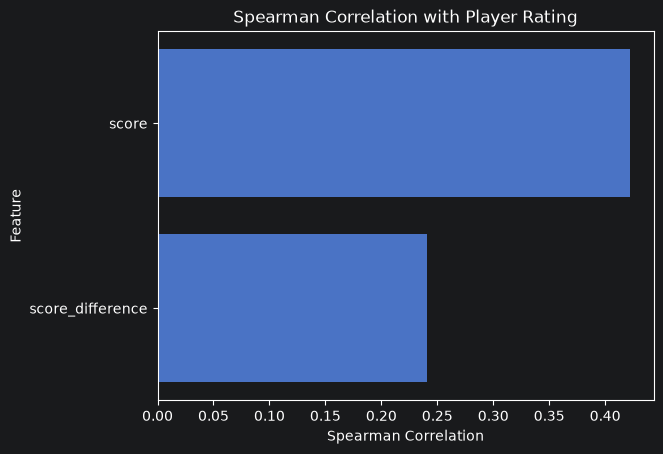

In [18]:
features = ["score", "score_difference"]

correlations = (
    score_pairs.loc[
        score_pairs["game_id"].isin(train_game_ids),
        features + ["rating"]
    ]
    .corr(method="spearman")["rating"]
    .drop("rating")
)

display(correlations)

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Spearman Correlation with Player Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black")
plt.show()

In [19]:
selected_features = [
    # numerical features
    "score",
    "avg_points",
    "num_turns",
    "max_points",
    "std_points",
    "game_duration_seconds",
    "initial_time_seconds",
    "increment_seconds",
    "max_overtime_minutes",
    "score_difference",

    # categorical features
    "rating_mode",
    "lexicon",
    "time_control_name",
    "game_end_reason",

    # binary features
    "played_first",
    "player_won"
]

# target variable
target = "rating"

# final df
train_final = score_pairs[
    selected_features + [target]
].copy()

print("Shape:", train_final.shape)
display(train_final.head())

Shape: (100820, 17)


,score,avg_points,num_turns,max_points,std_points,game_duration_seconds,initial_time_seconds,increment_seconds,max_overtime_minutes,score_difference,rating_mode,lexicon,time_control_name,game_end_reason,played_first,player_won,rating
1,335,25.769231,13,68,16.457794,674.844274,1200,0,1,-94,CASUAL,NWL20,regular,STANDARD,1,0,1637
2,429,30.642857,14,98,25.490895,674.844274,1200,0,1,94,CASUAL,NWL20,regular,STANDARD,0,1,1500
5,440,31.428571,14,103,21.689112,492.268262,900,0,5,122,RATED,CSW21,regular,STANDARD,0,1,1811
6,318,24.461538,13,76,18.058310,492.268262,900,0,5,-122,RATED,CSW21,regular,STANDARD,1,0,2071
9,119,8.500000,14,26,8.600089,350.861141,3600,0,1,-359,CASUAL,CSW21,regular,RESIGNED,0,0,1473


In [20]:



bots = {"BetterBot", "HastyBot", "STEEBot", "BB-8"}


train_rows = score_pairs.loc[
    score_pairs["game_id"].isin(train_game_ids)
].copy()

val_rows = score_pairs.loc[
    score_pairs["game_id"].isin(val_game_ids)
].copy()


train_games = set(train_rows["game_id"])
val_games = set(val_rows["game_id"])

# get human players only
train_players = set(
    train_rows.loc[
        ~train_rows["nickname"].isin(bots),
        "nickname"
    ].dropna()
)

val_players = set(
    val_rows.loc[
        ~val_rows["nickname"].isin(bots),
        "nickname"
    ].dropna()
)


game_overlap = train_games & val_games
player_overlap = train_players & val_players

print("TRAIN / VALIDATION")
print("=" * 55)
print("Training games:", len(train_games))
print("Validation games:", len(val_games))
print("Training human players:", len(train_players))
print("Validation human players:", len(val_players))
print("Overlapping games:", len(game_overlap))
print("Overlapping human players:", len(player_overlap))

if player_overlap:
    print("Overlapping player examples:",
          sorted(map(str, player_overlap))[:20])

assert not game_overlap, "Game leakage detected!"
assert not player_overlap, "Human player leakage detected!"


holdout_ids = globals().get("holdout_game_ids")

if holdout_ids is not None:

    holdout_rows = score_pairs.loc[
        score_pairs["game_id"].isin(holdout_ids)
    ].copy()

    holdout_games = set(holdout_rows["game_id"])

    holdout_players = set(
        holdout_rows.loc[
            ~holdout_rows["nickname"].isin(bots),
            "nickname"
        ].dropna()
    )

    assert train_games.isdisjoint(holdout_games), (
        "Train/holdout game leakage!"
    )

    assert val_games.isdisjoint(holdout_games), (
        "Validation/holdout game leakage!"
    )

    assert train_players.isdisjoint(holdout_players), (
        "Train/holdout player leakage!"
    )

    assert val_players.isdisjoint(holdout_players), (
        "Validation/holdout player leakage!"
    )

    print("\nHOLDOUT")
    print("=" * 55)
    print("Holdout games:", len(holdout_games))
    print("Holdout human players:", len(holdout_players))
    print("Overlapping train/holdout players:",
          len(train_players & holdout_players))
    print("Overlapping validation/holdout players:",
          len(val_players & holdout_players))

print("\nSUCCESS: All available splits are player/game-disjoint.")
print("Kaggle test.csv was NOT accessed.")


TRAIN / VALIDATION
Training games: 35176
Validation games: 5978
Training human players: 719
Validation human players: 143
Overlapping games: 0
Overlapping human players: 0

HOLDOUT
Holdout games: 9256
Holdout human players: 165
Overlapping train/holdout players: 0
Overlapping validation/holdout players: 0

SUCCESS: All available splits are player/game-disjoint.
Kaggle test.csv was NOT accessed.


In [21]:
display(turns["turn_type"].value_counts(dropna=False))
move_type_counts = pd.crosstab(
    index=[turns["game_id"], turns["nickname"]],
    columns=turns["turn_type"].fillna("Unknown")
).add_prefix("count_").reset_index()

display(move_type_counts.head())

turn_type
Play             1872864
End                67987
Exchange           48997
Pass                8065
Timeout             4143
Challenge           2571
Six-Zero Rule        476
NaN                  395
Name: count, dtype: int64

turn_type,game_id,nickname,count_Challenge,count_End,count_Exchange,count_Pass,count_Play,count_Six-Zero Rule,count_Timeout,count_Unknown
0,1,BetterBot,0,0,0,0,13,0,0,0
1,1,stevy,0,1,0,0,13,0,0,0
2,2,BetterBot,0,0,0,0,12,0,0,0
3,2,Super,0,1,1,1,11,0,0,0
4,3,BetterBot,0,0,1,0,12,0,0,0


count_End              0.078718
count_Challenge        0.057458
count_Unknown         -0.017357
count_Six-Zero Rule   -0.029294
count_Pass            -0.039914
count_Timeout         -0.067194
count_Exchange        -0.150907
count_Play            -0.283129
Name: rating, dtype: float64

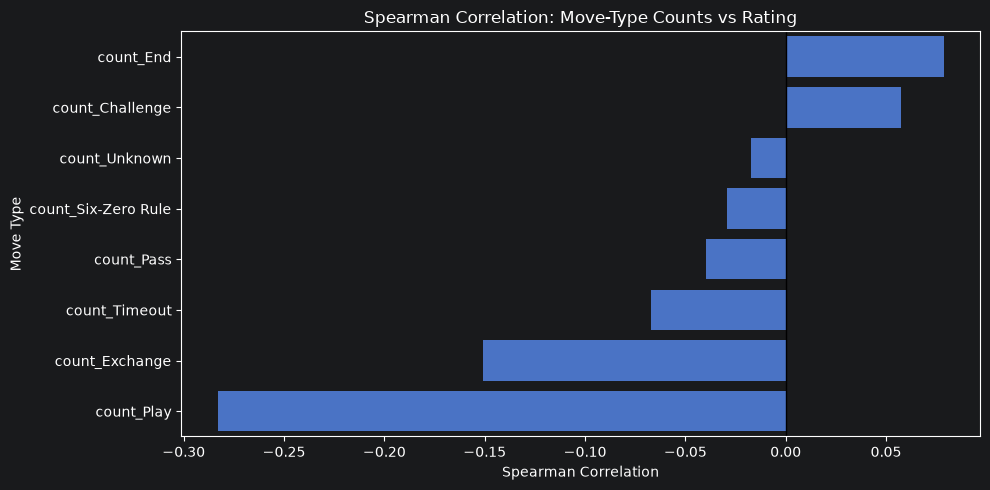

In [22]:

move_type_counts = pd.crosstab(
    index=[turns["game_id"], turns["nickname"]],
    columns=turns["turn_type"].fillna("Unknown")
).add_prefix("count_").reset_index()

moves_merged = score_pairs.merge(
    move_type_counts,
    on=["game_id", "nickname"],
    how="left",
    validate="one_to_one"
)

move_cols = [
    col for col in move_type_counts.columns
    if col.startswith("count_")
]

train_moves = moves_merged.loc[
    moves_merged["game_id"].isin(train_game_ids)
].copy()

correlations = (
    train_moves[move_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(correlations)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Spearman Correlation: Move-Type Counts vs Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Move Type")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


rate_End              0.150285
rate_Challenge        0.057472
rate_Play             0.003471
rate_Unknown         -0.017330
rate_Six-Zero Rule   -0.029307
rate_Pass            -0.039807
rate_Timeout         -0.066974
rate_Exchange        -0.142930
Name: rating, dtype: float64

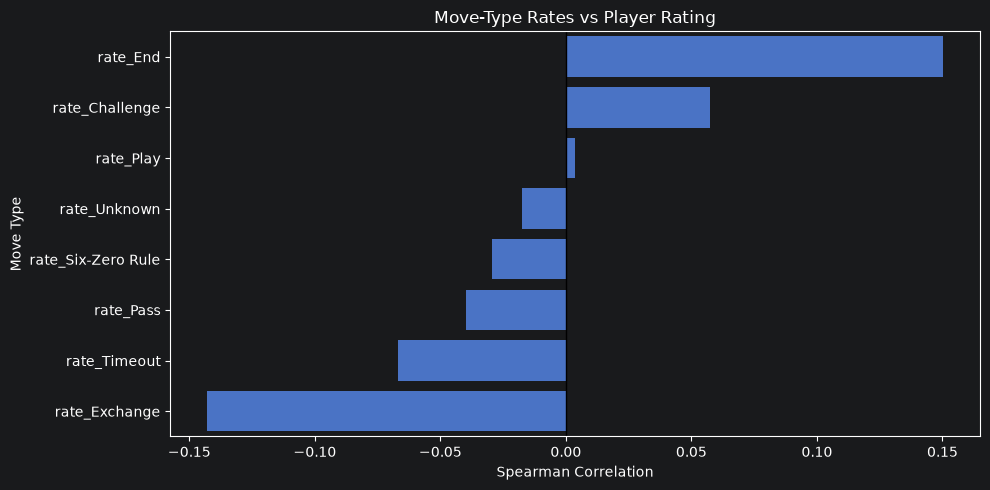

In [23]:

move_rate_cols = []


for col in move_cols:
    rate_col = col.replace("count_", "rate_")

    moves_merged[rate_col] = (
        moves_merged[col] /
        moves_merged["num_turns"].replace(0, np.nan)
    )

    move_rate_cols.append(rate_col)

train_moves = moves_merged.loc[
    moves_merged["game_id"].isin(train_game_ids)
].copy()

rate_correlations = (
    train_moves[move_rate_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(rate_correlations)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=rate_correlations.values,
    y=rate_correlations.index
)

plt.title("Move-Type Rates vs Player Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Move Type")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


In [24]:
display(
    moves_merged["count_End"]
    .value_counts()
    .sort_index()
)

display(
    moves_merged.groupby("count_End")["num_turns"]
    .agg(["count", "mean", "median"])
)
display(
    pd.crosstab(
        moves_merged["count_End"],
        moves_merged["player_won"],
        normalize="index"
    ).round(3)
)

count_End
0    53126
1    47694
Name: count, dtype: int64

,count,mean,median
count_End,,,
0,53126,13.106087,13.0
1,47694,14.572378,14.0


player_won,0,1
count_End,,
0,0.506,0.494
1,0.498,0.502


In [25]:


expanded_data = moves_merged.copy()

print("Expanded data initialized:", expanded_data.shape)

Expanded data initialized: (100820, 41)


Spearman correlations with rating — training only


move_length_mean         0.325876
move_length_max          0.262038
move_length_std          0.247165
rack_vowel_ratio_std     0.007470
rack_vowel_ratio_mean   -0.022334
Name: rating, dtype: float64


Missing values in human training data:


move_length_mean         0
move_length_std          0
move_length_max          0
rack_vowel_ratio_mean    0
rack_vowel_ratio_std     0
dtype: int64

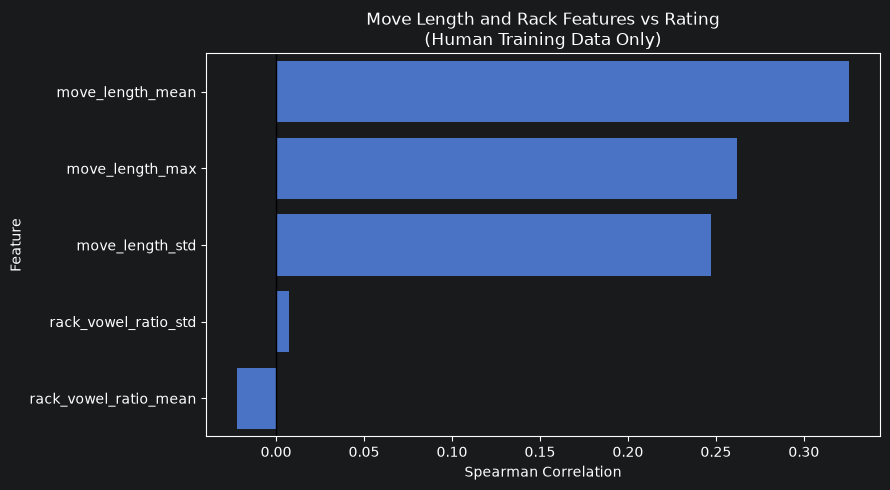

In [26]:
t = turns.copy()

t["move_letters"] = (
    t["move"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_length"] = (
    t["move_letters"]
    .str.len()
    .astype(float)
)

t.loc[t["move"].isna(), "move_length"] = np.nan

t["rack_letters"] = (
    t["rack"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["rack_length"] = (
    t["rack_letters"]
    .str.len()
    .astype(float)
)

t["rack_vowels"] = (
    t["rack_letters"]
    .str.count(r"[AEIOU]")
    .astype(float)
)

t["rack_vowel_ratio"] = (
    t["rack_vowels"] /
    t["rack_length"].replace(0, np.nan)
)


new_turn_features = (
    t.groupby(["game_id", "nickname"])
    .agg(
        move_length_mean=("move_length", "mean"),
        move_length_std=("move_length", "std"),
        move_length_max=("move_length", "max"),
        rack_vowel_ratio_mean=("rack_vowel_ratio", "mean"),
        rack_vowel_ratio_std=("rack_vowel_ratio", "std")
    )
    .reset_index()
)

feature_cols = [
    "move_length_mean",
    "move_length_std",
    "move_length_max",
    "rack_vowel_ratio_mean",
    "rack_vowel_ratio_std"
]

original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=feature_cols, errors="ignore")
    .merge(
        new_turn_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows

bots = ["BetterBot", "HastyBot", "STEEBot"]

eda_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()


assert set(eda_train["game_id"]).isdisjoint(val_game_ids)

correlations = (
    eda_train[feature_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("Spearman correlations with rating — training only")
display(correlations)

print("\nMissing values in human training data:")
display(
    eda_train[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)


plt.figure(figsize=(9, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title(
    "Move Length and Rack Features vs Rating\n"
    "(Human Training Data Only)"
)
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
selected_move_features = [
    "move_length_mean",
    "move_length_max",
    "move_length_std"
]

high_score_rate     0.374936
high_score_count    0.333216
Name: rating, dtype: float64

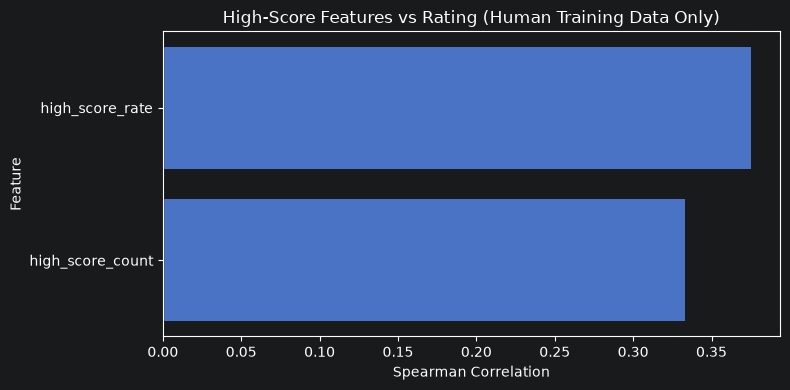

In [27]:

high_score_turns = turns.copy()

high_score_turns["is_high_score"] = (
    (high_score_turns["turn_type"] == "Play") &
    (high_score_turns["points"] >= 50)
).astype(int)

high_score_features = (
    high_score_turns.groupby(["game_id", "nickname"])
    .agg(
        high_score_count=("is_high_score", "sum"),
        high_score_rate=("is_high_score", "mean")
    )
    .reset_index()
)


high_score_cols = ["high_score_count", "high_score_rate"]

expanded_data = (
    expanded_data.drop(columns=high_score_cols, errors="ignore")
    .merge(
        high_score_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

bots = ["BetterBot", "HastyBot", "STEEBot"]

high_score_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()

assert set(high_score_train["game_id"]).isdisjoint(val_game_ids)

high_score_correlations = (
    high_score_train[high_score_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(high_score_correlations)

plt.figure(figsize=(8, 4))

sns.barplot(
    x=high_score_correlations.values,
    y=high_score_correlations.index
)

plt.title("High-Score Features vs Rating (Human Training Data Only)")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

Spearman correlation with rating
Human training data only


,Spearman
move_len_mean,0.331242
difficult_word_mean,0.314002
points_per_letter_mean,0.313735
difficult_word_sum,0.276668
move_len_max,0.263027
difficult_letters_mean,0.116908
difficult_letters_sum,0.025090
curr_board_pieces_used_mean,-0.244612



Missing values:


move_len_mean                  16
move_len_max                   16
difficult_word_mean            16
difficult_word_sum             16
difficult_letters_mean         16
difficult_letters_sum          16
points_per_letter_mean         16
curr_board_pieces_used_mean    16
dtype: int64

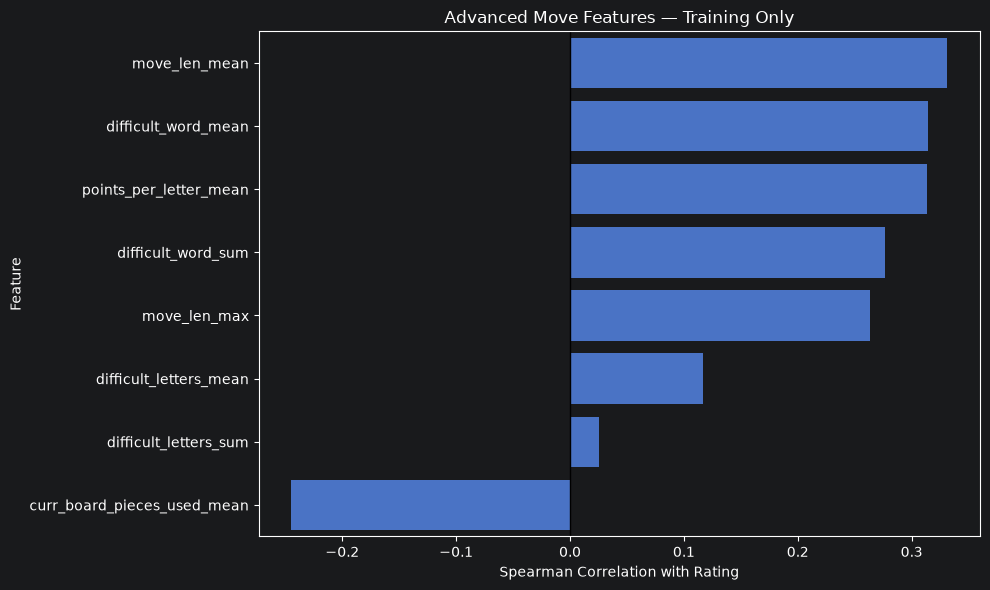


Example move notations:


,move_raw,move_letters,move_len,curr_board_pieces_used
0,DIG,DIG,3.0,0.0
1,HAP,HAP,3.0,0.0
2,LUTE,LUTE,4.0,0.0
3,UM,UM,2.0,0.0
4,..DICATE,DICATE,6.0,2.0
5,OXO,OXO,3.0,0.0
6,RAJAS,RAJAS,5.0,0.0
7,FAERIES,FAERIES,7.0,0.0
8,NEURON.L,NEURONL,7.0,1.0
9,HO,HO,2.0,0.0



Play moves containing '.': 918079


In [28]:

# prepare Play turns

t = turns.loc[
    turns["turn_type"] == "Play"
].copy()

t["move_raw"] = t["move"].astype("string")

t["move_letters"] = (
    t["move_raw"]
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_len"] = t["move_letters"].str.len().astype(float)

# unknown / empty moves should not become zero-length words
t.loc[t["move_len"] == 0, "move_len"] = np.nan



t["is_difficult_word"] = (
    t["move_len"] >= 7
).astype(float)

t.loc[
    t["move_len"].isna(), "is_difficult_word"
] = np.nan

#
# ifficult letters: J, Q, X, Z
#

t["difficult_letters"] = (
    t["move_letters"]
    .str.count(r"[JQXZ]")
    .astype(float)
)

t.loc[
    t["move_len"].isna(), "difficult_letters"
] = np.nan

# points per letter


t["points_per_letter"] = (
    pd.to_numeric(t["points"], errors="coerce")
    / t["move_len"]
)


# existing board tiles used (notation proxy)

t["curr_board_pieces_used"] = (
    t["move_raw"]
    .str.count(r"\.")
    .astype(float)
)

t.loc[
    t["move_raw"].isna(), "curr_board_pieces_used"
] = np.nan



advanced_move_features = (
    t.groupby(["game_id", "nickname"])
    .agg(
        move_len_mean=("move_len", "mean"),
        move_len_max=("move_len", "max"),

        difficult_word_mean=("is_difficult_word", "mean"),
        difficult_word_sum=("is_difficult_word", "sum"),

        difficult_letters_mean=("difficult_letters", "mean"),
        difficult_letters_sum=("difficult_letters", "sum"),

        points_per_letter_mean=("points_per_letter", "mean"),

        curr_board_pieces_used_mean=(
            "curr_board_pieces_used", "mean"
        )
    )
    .reset_index()
)

advanced_cols = [
    "move_len_mean",
    "move_len_max",
    "difficult_word_mean",
    "difficult_word_sum",
    "difficult_letters_mean",
    "difficult_letters_sum",
    "points_per_letter_mean",
    "curr_board_pieces_used_mean"
]



original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=advanced_cols, errors="ignore")
    .merge(
        advanced_move_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows


# human training observations only

bots = ["BetterBot", "HastyBot", "STEEBot"]

advanced_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()


assert set(advanced_train["game_id"]).isdisjoint(
    val_game_ids
)


correlations = (
    advanced_train[advanced_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("Spearman correlation with rating")
print("Human training data only")
print("=" * 55)

display(correlations.to_frame("Spearman"))



print("\nMissing values:")
display(
    advanced_train[advanced_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)


plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Spearman Correlation with Rating")
plt.ylabel("Feature")
plt.title("Advanced Move Features — Training Only")
plt.tight_layout()
plt.show()


print("\nExample move notations:")
display(
    t[
        ["move_raw", "move_letters", "move_len",
         "curr_board_pieces_used"]
    ].dropna().head(20)
)

print(
    "\nPlay moves containing '.':",
    int(t["move_raw"].str.contains(
        r"\.", regex=True, na=False
    ).sum())
)


In [29]:


# Bot Gameplay Features + Human Bot Differences
# No bot rating / No player history / No test data


import numpy as np
import pandas as pd

bots = ["BetterBot", "HastyBot", "STEEBot"]

bot_feature_cols = [
    "bot_score",
    "bot_name",
    "bot_points_mean",
    "bot_move_len_mean",
    "avg_points_diff",
    "avg_move_len_diff",
    "avg_points_per_letter_diff"
]

# turn level statistics


t = turns.copy()

t["points_numeric"] = pd.to_numeric(
    t["points"], errors="coerce"
)

t["move_letters"] = (
    t["move"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_length"] = (
    t["move_letters"].str.len().astype(float)
)

# move statistics only for actual Play turns
is_play = t["turn_type"].eq("Play")

t.loc[~is_play | (t["move_length"] == 0),
      "move_length"] = np.nan

t["points_per_letter"] = (
    t["points_numeric"] /
    t["move_length"]
)



turn_stats = (
    t.groupby(["game_id", "nickname"])
    .agg(
        points_mean=("points_numeric", "mean"),
        move_len_mean=("move_length", "mean"),
        points_per_letter_mean=(
            "points_per_letter", "mean"
        )
    )
    .reset_index()
)


bot_scores = train.loc[
    train["nickname"].isin(bots),
    ["game_id", "nickname", "score"]
].copy()

assert not bot_scores["game_id"].duplicated().any(), (
    "More than one bot per game detected"
)

bot_stats = bot_scores.merge(
    turn_stats,
    on=["game_id", "nickname"],
    how="left",
    validate="one_to_one"
)

bot_stats = bot_stats.rename(columns={
    "nickname": "bot_name",
    "score": "bot_score",
    "points_mean": "bot_points_mean",
    "move_len_mean": "bot_move_len_mean",
    "points_per_letter_mean": "bot_points_per_letter_mean"
})


human_stats = turn_stats.rename(columns={
    "points_mean": "human_points_mean",
    "move_len_mean": "human_move_len_mean",
    "points_per_letter_mean": "human_points_per_letter_mean"
})

human_rows = expanded_data.loc[
    ~expanded_data["nickname"].isin(bots),
    ["game_id", "nickname"]
].copy()

assert not human_rows.duplicated(
    ["game_id", "nickname"]
).any()

human_bot = (
    human_rows
    .merge(
        human_stats,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        bot_stats[
            [
                "game_id",
                "bot_name",
                "bot_score",
                "bot_points_mean",
                "bot_move_len_mean",
                "bot_points_per_letter_mean"
            ]
        ],
        on="game_id",
        how="left",
        validate="many_to_one"
    )
)


human_bot["avg_points_diff"] = (
    human_bot["human_points_mean"]
    - human_bot["bot_points_mean"]
)

human_bot["avg_move_len_diff"] = (
    human_bot["human_move_len_mean"]
    - human_bot["bot_move_len_mean"]
)

human_bot["avg_points_per_letter_diff"] = (
    human_bot["human_points_per_letter_mean"]
    - human_bot["bot_points_per_letter_mean"]
)


original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=bot_feature_cols, errors="ignore")
    .merge(
        human_bot[
            ["game_id", "nickname"] + bot_feature_cols
        ],
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows

# every human game should have a bot opponent
human_mask = ~expanded_data["nickname"].isin(bots)

assert expanded_data.loc[
    human_mask, "bot_name"
].notna().all(), "Some human games have no bot opponent"



bot_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & human_mask
].copy()

assert set(bot_train["game_id"]).isdisjoint(
    val_game_ids
)

numeric_bot_features = [
    col for col in bot_feature_cols
    if col != "bot_name"
]

correlations = (
    bot_train[numeric_bot_features + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("Bot feature correlations — HUMAN TRAINING ONLY")
print("=" * 55)

display(correlations.to_frame("Spearman"))

print("\nMissing values:")
display(
    bot_train[bot_feature_cols].isna().sum()
)

print("\nBot distribution in training:")
display(bot_train["bot_name"].value_counts())

print("\nExample:")
display(
    bot_train[
        ["nickname", "rating"] + bot_feature_cols
    ].head(10)
)


Bot feature correlations — HUMAN TRAINING ONLY


,Spearman
bot_points_mean,0.308033
bot_move_len_mean,0.261527
bot_score,0.151977
avg_points_diff,0.097228
avg_move_len_diff,0.075943
avg_points_per_letter_diff,0.069606



Missing values:


bot_score                      0
bot_name                       0
bot_points_mean                0
bot_move_len_mean              0
avg_points_diff                0
avg_move_len_diff             16
avg_points_per_letter_diff    16
dtype: int64


Bot distribution in training:


bot_name
STEEBot      12105
BetterBot    11693
HastyBot     11378
Name: count, dtype: int64


Example:


,nickname,rating,bot_score,bot_name,bot_points_mean,bot_move_len_mean,avg_points_diff,avg_move_len_diff,avg_points_per_letter_diff
1,stevy,1500,335.0,BetterBot,25.769231,4.000000,4.873626,-0.538462,3.067033
2,davidavid,1811,318.0,BetterBot,24.461538,3.750000,6.967033,-0.057692,2.141346
6,stevy,1500,427.0,STEEBot,28.466667,3.733333,-8.154167,-0.876190,1.434127
8,HivinD,2029,427.0,STEEBot,32.846154,4.181818,-1.346154,-0.098485,-0.899369
11,AliSalman1,2067,528.0,HastyBot,40.615385,4.636364,-2.979021,-0.545455,-1.288528
12,cccc,1641,464.0,BetterBot,33.142857,3.500000,-8.876190,0.038462,-1.443407
15,squashy,1838,415.0,BetterBot,27.666667,3.571429,-6.309524,0.095238,-1.361139
16,BB-8,1500,408.0,HastyBot,24.000000,3.400000,-0.600000,-0.114286,-1.330952
18,Trayz,2017,381.0,STEEBot,29.307692,4.416667,10.146853,-0.780303,4.317677
21,meetsumeet,1863,451.0,STEEBot,34.692308,4.083333,-1.108974,-0.500000,3.483135


## Historical Player Features — EDA Only

Historical player statistics are **EDA Only**. They are **off limits for model training and feature selection** in this notebook. The existing models exclude `historical_score_mean`, `historical_score_std`, `historical_games_count`, and columns starting with `historical_` (as well as `bot_rating` and `opponent_rating`).

No historical information is added to the training or Kaggle submission features by the following checks. All analyses below use **human TRAIN games only**; validation, holdout, and Kaggle test games are excluded.

## Correlations by Time Control and Bot

Check whether the top feature correlations with `rating` remain similar within each `time_control_name` and `bot_name`. A global correlation may hide different relationships across groups. Report each group's sample size and the largest changes from the global correlation.

C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


Top global Spearman correlations (human TRAIN games)


,Spearman
avg_points,0.485192
score,0.421085
total_points,0.421085
move_length_mean,0.403743
high_score_rate,0.403578
move_len_mean,0.398816
high_score_count,0.364742
difficult_word_mean,0.336789
move_len_max,0.318399
count_Play,-0.317701



Correlations within time_control_name


C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An in

Top correlations for each group:


... (7 outputs left out)

Top correlations for each group:


,group,rows,games,players,feature,group_spearman,global_spearman
0,BetterBot,11693,11693,391,score,0.330,0.421
1,BetterBot,11693,11693,391,total_points,0.330,0.421
2,BetterBot,11693,11693,391,avg_points,0.328,0.485
3,BetterBot,11693,11693,391,score_difference,0.276,0.227
4,BetterBot,11693,11693,391,move_length_mean,0.258,0.404
5,BetterBot,11693,11693,391,move_len_mean,0.256,0.399
6,BetterBot,11693,11693,391,high_score_rate,0.254,0.404
7,BetterBot,11693,11693,391,avg_points_diff,0.252,0.190
8,BetterBot,11693,11693,391,high_score_count,0.247,0.365
9,BetterBot,11693,11693,391,winner,0.232,0.183


Largest subgroup-vs-global correlation differences:


,group,rows,players,feature,group_spearman,global_spearman,difference,abs_difference
41,BetterBot,11693,391,bot_points_mean,0.015,0.270,-0.254,0.254
47,BetterBot,11693,391,bot_move_len_mean,0.007,0.225,-0.218,0.218
75,HastyBot,6776,254,bot_score,-0.119,0.075,-0.195,0.195
76,HastyBot,6776,254,opponent_score,-0.119,0.075,-0.195,0.195
26,BetterBot,11693,391,bot_score,-0.112,0.075,-0.187,0.187
25,BetterBot,11693,391,opponent_score,-0.112,0.075,-0.187,0.187
24,BetterBot,11693,391,num_turns,-0.119,-0.305,0.186,0.186
81,HastyBot,6776,254,bot_points_mean,0.086,0.270,-0.184,0.184
21,BetterBot,11693,391,count_Play,-0.147,-0.318,0.171,0.171
85,HastyBot,6776,254,bot_move_len_mean,0.061,0.225,-0.164,0.164


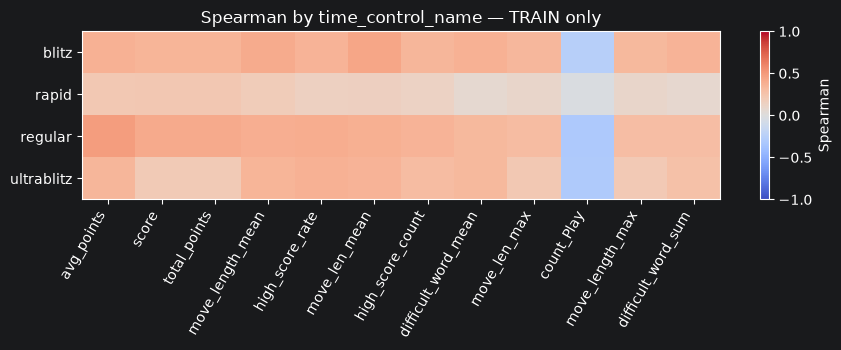

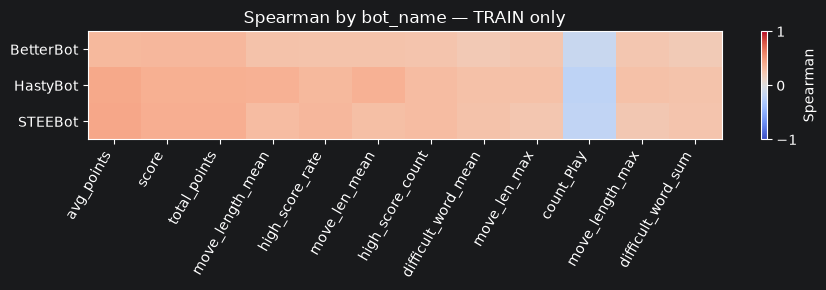

In [30]:
# Subgroup correlations — HUMAN TRAIN only
# All results are EDA; no model features are modified.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

eda_bots = {"BetterBot", "HastyBot", "STEEBot", "BB-8"}
eda_subgroups = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(eda_bots)
].copy()

assert not eda_subgroups.empty
assert eda_subgroups["rating"].notna().all()
assert set(eda_subgroups["game_id"]).isdisjoint(val_game_ids | holdout_game_ids)
assert not eda_subgroups.duplicated(["game_id", "nickname"]).any()

# No IDs, targets, historical fields, or rating-related shortcuts.
eda_excluded = {
    "rating", "game_id", "nickname", "opponent_nickname",
    "bot_rating", "opponent_rating", "historical_score_mean",
    "historical_score_std", "historical_games_count"
}
eda_candidate_cols = [
    c for c in eda_subgroups.select_dtypes(include="number").columns
    if c not in eda_excluded
    and not c.startswith("historical_")
    and not c.startswith("rating_")
]

# Correlations are computed on observations available within each group.
eda_target = pd.to_numeric(eda_subgroups["rating"], errors="coerce")
eda_global_corr = (
    eda_subgroups[eda_candidate_cols]
    .corrwith(eda_target, method="spearman")
    .dropna()
)
eda_global_top = eda_global_corr.reindex(
    eda_global_corr.abs().sort_values(ascending=False).index
)
print("Top global Spearman correlations (human TRAIN games)")
display(eda_global_top.head(15).to_frame("Spearman"))

eda_subgroup_tables = {}
eda_subgroup_changes = {}
MIN_GROUP_SIZE = 40

for group_col in ["time_control_name", "bot_name"]:
    print("\n" + "=" * 65)
    print("Correlations within", group_col)
    print("=" * 65)
    rows = []
    changes = []
    for group_name, group in eda_subgroups.groupby(group_col, dropna=False):
        n_games = group["game_id"].nunique()
        n_players = group["nickname"].nunique()
        if len(group) < MIN_GROUP_SIZE:
            print(f"Skipping {group_name}: {len(group)} rows (< {MIN_GROUP_SIZE})")
            continue
        corr = (
            group[eda_candidate_cols]
            .corrwith(pd.to_numeric(group["rating"], errors="coerce"), method="spearman")
            .dropna()
        )
        corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
        for feature, value in corr.head(10).items():
            rows.append({
                "group": group_name, "rows": len(group),
                "games": n_games, "players": n_players,
                "feature": feature, "group_spearman": value,
                "global_spearman": eda_global_corr.get(feature, np.nan)
            })
        for feature, value in corr.items():
            global_r = eda_global_corr.get(feature, np.nan)
            if np.isfinite(global_r):
                changes.append({
                    "group": group_name, "rows": len(group),
                    "players": n_players, "feature": feature,
                    "group_spearman": value, "global_spearman": global_r,
                    "difference": value - global_r,
                    "abs_difference": abs(value - global_r)
                })
    eda_subgroup_tables[group_col] = pd.DataFrame(rows)
    eda_subgroup_changes[group_col] = pd.DataFrame(changes)
    if not eda_subgroup_tables[group_col].empty:
        print("Top correlations for each group:")
        display(eda_subgroup_tables[group_col].round(3))
    if not eda_subgroup_changes[group_col].empty:
        print("Largest subgroup-vs-global correlation differences:")
        display(eda_subgroup_changes[group_col]
                .sort_values("abs_difference", ascending=False)
                .head(15).round(3))

# Restrict the heatmap to consistently relevant features rather than
# plotting hundreds of less meaningful columns.
eda_heatmap_features = list(eda_global_top.head(12).index)
for group_col in ["time_control_name", "bot_name"]:
    results = []
    for group_name, group in eda_subgroups.groupby(group_col, dropna=False):
        if len(group) < MIN_GROUP_SIZE:
            continue
        corrs = group[eda_heatmap_features].corrwith(
            group["rating"], method="spearman"
        )
        corrs.name = str(group_name)
        results.append(corrs)
    if results:
        heatmap = pd.DataFrame(results)
        fig, ax = plt.subplots(figsize=(max(9, len(eda_heatmap_features) * 0.75),
                                        max(3, len(results) * 0.65 + 1)))
        image = ax.imshow(heatmap.to_numpy(dtype=float), cmap="coolwarm",
                          vmin=-1, vmax=1, aspect="auto")
        ax.set_xticks(range(len(heatmap.columns)), heatmap.columns,
                      rotation=60, ha="right")
        ax.set_yticks(range(len(heatmap.index)), heatmap.index)
        ax.set_title(f"Spearman by {group_col} — TRAIN only")
        fig.colorbar(image, ax=ax, label="Spearman")
        plt.tight_layout()
        plt.show()

## Player-Level Independence Sanity Check

Some players appear in many games. Compare the usual row-level Spearman correlations with **one observation per human player** (player-level means). This checks whether the EDA rankings are driven disproportionately by frequent players. This check is separate from the existing player-disjoint train/validation/holdout split.

In [31]:
# Player-level sanity check — HUMAN TRAIN only
# One row per nickname; model and train/validation split remain unchanged.

eda_player_games = (
    eda_subgroups.groupby("nickname", observed=True)
    .agg(n_games=("game_id", "nunique"),
         mean_rating=("rating", "mean"))
)

# Use the same numerical candidates as the subgroup EDA.
eda_player_means = (
    eda_subgroups.groupby("nickname", observed=True)[eda_candidate_cols]
    .mean(numeric_only=True)
)
eda_player_means = eda_player_games.join(eda_player_means, how="inner")

row_r = (
    eda_subgroups[eda_candidate_cols]
    .corrwith(eda_subgroups["rating"], method="spearman")
)
player_r = (
    eda_player_means[eda_candidate_cols]
    .corrwith(eda_player_means["mean_rating"], method="spearman")
)

eda_player_corr_compare = pd.DataFrame({
    "row_spearman": row_r,
    "player_spearman": player_r,
}).dropna()
eda_player_corr_compare["difference"] = (
    eda_player_corr_compare["player_spearman"]
    - eda_player_corr_compare["row_spearman"]
)
eda_player_corr_compare["abs_difference"] = eda_player_corr_compare["difference"].abs()
eda_player_corr_compare["sign_changed"] = (
    np.sign(eda_player_corr_compare["row_spearman"])
    != np.sign(eda_player_corr_compare["player_spearman"])
)

print("Rows (games):", len(eda_subgroups))
print("Unique human players:", len(eda_player_means))
print("Games per human player:")
display(eda_player_means["n_games"].describe().round(2).to_frame("games"))

print("\nTop correlations measured at row level vs player level:")
eda_order = eda_player_corr_compare["row_spearman"].abs().sort_values(
    ascending=False
).index
display(eda_player_corr_compare.loc[eda_order].head(20).round(3))

print("\nLargest correlation changes when each player counts once:")
display(eda_player_corr_compare.sort_values(
    "abs_difference", ascending=False
).head(20).round(3))

# A second pass: players with >=2 games, to check stability.
if (eda_player_means["n_games"] >= 2).sum() >= 30:
    repeat_players = eda_player_means.loc[eda_player_means["n_games"] >= 2]
    repeat_r = repeat_players[eda_candidate_cols].corrwith(
        repeat_players["mean_rating"], method="spearman"
    )
    repeat_table = pd.DataFrame({
        "all_players": player_r,
        "players_2plus_games": repeat_r
    }).dropna()
    print("\nPlayer-level correlations: all players vs players with >=2 games:")
    display(repeat_table.reindex(eda_order).head(15).round(3))

# Correlation of feature rankings at row and player level (descriptive only).
if len(eda_player_corr_compare) >= 3:
    agreement = eda_player_corr_compare[["row_spearman", "player_spearman"]].corr(
        method="spearman"
    ).iloc[0, 1]
    print(f"\nFeature correlation-ranking agreement: {agreement:.3f}")

# Rating is a player attribute in this task, so repeated rows are not
# independent. Player-level averaging reduces frequency weighting, but
# cannot establish causal relationships or confidence intervals.

C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


Rows (games): 30574
Unique human players: 719
Games per human player:


C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,games
count,719.00
mean,42.52
std,107.83
min,1.00
25%,2.00
50%,8.00
75%,36.00
max,1759.00



Top correlations measured at row level vs player level:


,row_spearman,player_spearman,difference,abs_difference,sign_changed
avg_points,0.485,0.609,0.123,0.123,False
score,0.421,0.616,0.195,0.195,False
total_points,0.421,0.616,0.195,0.195,False
move_length_mean,0.404,0.548,0.144,0.144,False
high_score_rate,0.404,0.555,0.152,0.152,False
move_len_mean,0.399,0.527,0.128,0.128,False
high_score_count,0.365,0.534,0.169,0.169,False
difficult_word_mean,0.337,0.507,0.170,0.170,False
move_len_max,0.318,0.502,0.184,0.184,False
count_Play,-0.318,-0.341,-0.023,0.023,False


... (2 outputs left out)


Player-level correlations: all players vs players with >=2 games:


C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\barak\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,all_players,players_2plus_games
avg_points,0.609,0.621
score,0.616,0.643
total_points,0.616,0.643
move_length_mean,0.548,0.545
high_score_rate,0.555,0.571
move_len_mean,0.527,0.528
high_score_count,0.534,0.556
difficult_word_mean,0.507,0.539
move_len_max,0.502,0.548
count_Play,-0.341,-0.364



Feature correlation-ranking agreement: 0.900


## Play-Only Normalization and Game-Length Control

`high_score_rate` currently counts 50+ point plays divided by **all turns**. Here we calculate a separate `high_score_play_rate` using **Play turns only**, compare both versions, and check whether move-quality correlations survive after controlling for `num_turns` and `game_duration_seconds`.

This is **EDA Only**: the original `high_score_rate`, existing feature lists, model training and Kaggle submissions are not changed.

Play-turn denominators:


,num_turns,eda_play_turns,high_score_rate,high_score_play_rate
count,30574.000,30574.000,30574.000,30558.000
mean,13.695,12.742,0.144,0.155
std,2.084,1.720,0.101,0.109
min,10.000,0.000,0.000,0.000
25%,12.000,12.000,0.071,0.077
50%,13.000,13.000,0.143,0.154
75%,15.000,14.000,0.214,0.231
max,43.000,25.000,0.727,1.000



Move quality vs rating — before and after controlling for game length:


,spearman,partial_spearman,complete_rows,change_after_control
feature,,,,
avg_points,0.485,0.394,30574,-0.091
move_length_mean,0.404,0.283,30574,-0.121
high_score_rate,0.404,0.305,30574,-0.099
move_len_mean,0.399,0.286,30558,-0.112
high_score_play_rate,0.398,0.305,30558,-0.093
high_score_count,0.365,0.303,30574,-0.061
difficult_word_mean,0.337,0.244,30558,-0.092
points_per_letter_mean,0.310,0.243,30558,-0.067
curr_board_pieces_used_mean,-0.119,-0.093,30558,0.026


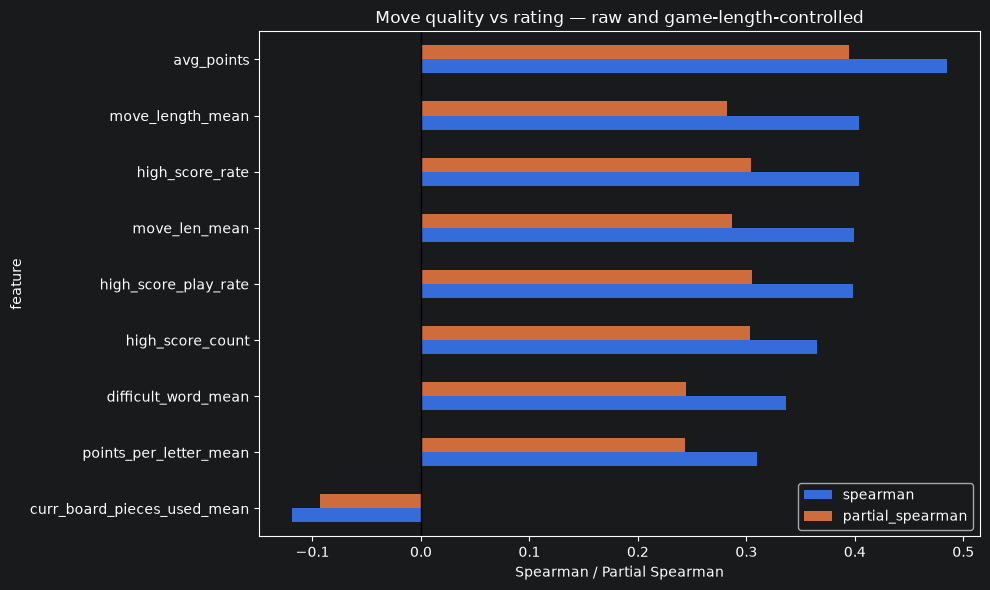


NOTE: This analysis does not change the trained model features.


In [32]:
# Play-only high-score rate and partial Spearman — HUMAN TRAIN only
# Creates a new EDA dataframe without modifying expanded_data.

eda_play_turns = turns.loc[
    turns["game_id"].isin(train_game_ids)
    & turns["turn_type"].eq("Play")
].copy()
eda_play_turns["eda_is_high_score"] = (
    pd.to_numeric(eda_play_turns["points"], errors="coerce") >= 50
).astype(float)
eda_play_stats = (
    eda_play_turns.groupby(["game_id", "nickname"])
    .agg(eda_play_turns=("eda_is_high_score", "size"),
         eda_high_score_play_count=("eda_is_high_score", "sum"))
    .reset_index()
)

eda_length_df = eda_subgroups.merge(
    eda_play_stats, on=["game_id", "nickname"],
    how="left", validate="one_to_one"
)
eda_length_df["eda_play_turns"] = eda_length_df["eda_play_turns"].fillna(0)
eda_length_df["eda_high_score_play_count"] = (
    eda_length_df["eda_high_score_play_count"].fillna(0)
)
eda_length_df["high_score_play_rate"] = (
    eda_length_df["eda_high_score_play_count"] /
    eda_length_df["eda_play_turns"].replace(0, np.nan)
)

# Sanity check: new Play-only numerator matches the old high-score count.
valid_count = eda_length_df["high_score_count"].notna()
assert np.allclose(
    eda_length_df.loc[valid_count, "high_score_count"],
    eda_length_df.loc[valid_count, "eda_high_score_play_count"]
), "High-score count mismatch: inspect turn filtering before interpreting correlations"

print("Play-turn denominators:")
display(eda_length_df[["num_turns", "eda_play_turns",
                       "high_score_rate", "high_score_play_rate"]]
        .describe().round(3))

eda_quality_cols = [
    c for c in [
        "high_score_rate", "high_score_play_rate",
        "high_score_count", "avg_points", "move_len_mean",
        "difficult_word_mean", "points_per_letter_mean",
        "curr_board_pieces_used_mean", "move_length_mean"
    ] if c in eda_length_df.columns
]

# Partial Spearman: rank each series, regress ranks on the controls,
# then correlate the residuals. Both number of turns and elapsed time
# are controlled; the resulting quantity is descriptive, not causal.
def eda_partial_spearman(frame, feature, target="rating",
                         controls=("num_turns", "game_duration_seconds")):
    cols = [feature, target] + list(controls)
    df = frame[cols].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    if len(df) < 30 or df[feature].nunique() < 2 or df[target].nunique() < 2:
        return np.nan, len(df)
    ranks = df.rank(method="average")
    covariates = ranks[list(controls)].to_numpy(dtype=float)
    covariates = np.column_stack([np.ones(len(ranks)), covariates])
    feature_rank = ranks[feature].to_numpy(dtype=float)
    rating_rank = ranks[target].to_numpy(dtype=float)
    f_residual = feature_rank - covariates @ np.linalg.lstsq(
        covariates, feature_rank, rcond=None
    )[0]
    y_residual = rating_rank - covariates @ np.linalg.lstsq(
        covariates, rating_rank, rcond=None
    )[0]
    if np.std(f_residual) == 0 or np.std(y_residual) == 0:
        return np.nan, len(df)
    return float(np.corrcoef(f_residual, y_residual)[0, 1]), len(df)

eda_length_results = []
for feature in eda_quality_cols:
    plain = eda_length_df[[feature, "rating"]].corr(method="spearman").iloc[0, 1]
    adjusted, n = eda_partial_spearman(eda_length_df, feature)
    eda_length_results.append({
        "feature": feature, "spearman": plain,
        "partial_spearman": adjusted, "complete_rows": n,
        "change_after_control": adjusted - plain
    })

eda_length_corr = pd.DataFrame(eda_length_results).set_index("feature")
print("\nMove quality vs rating — before and after controlling for game length:")
display(eda_length_corr.sort_values("spearman", key=lambda s: s.abs(),
                                    ascending=False).round(3))

if not eda_length_corr.empty:
    compare_plot = eda_length_corr[["spearman", "partial_spearman"]].sort_values(
        "spearman"
    )
    ax = compare_plot.plot(kind="barh", figsize=(10, 6))
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title("Move quality vs rating — raw and game-length-controlled")
    ax.set_xlabel("Spearman / Partial Spearman")
    plt.tight_layout()
    plt.show()

print("\nNOTE: This analysis does not change the trained model features.")

Total features: 65

Correlation analysis — HUMAN TRAIN ONLY
Features before one-hot encoding: 65
Features after encoding: 75
Features with |Spearman| >= 0.2: 29


,Spearman_with_rating
lexicon_CSW21,0.513046
lexicon_NWL20,-0.512164
avg_points,0.485192
score,0.421085
total_points,0.421085
move_length_mean,0.403743
high_score_rate,0.403578
move_len_mean,0.398816
high_score_count,0.364742
difficult_word_mean,0.336789


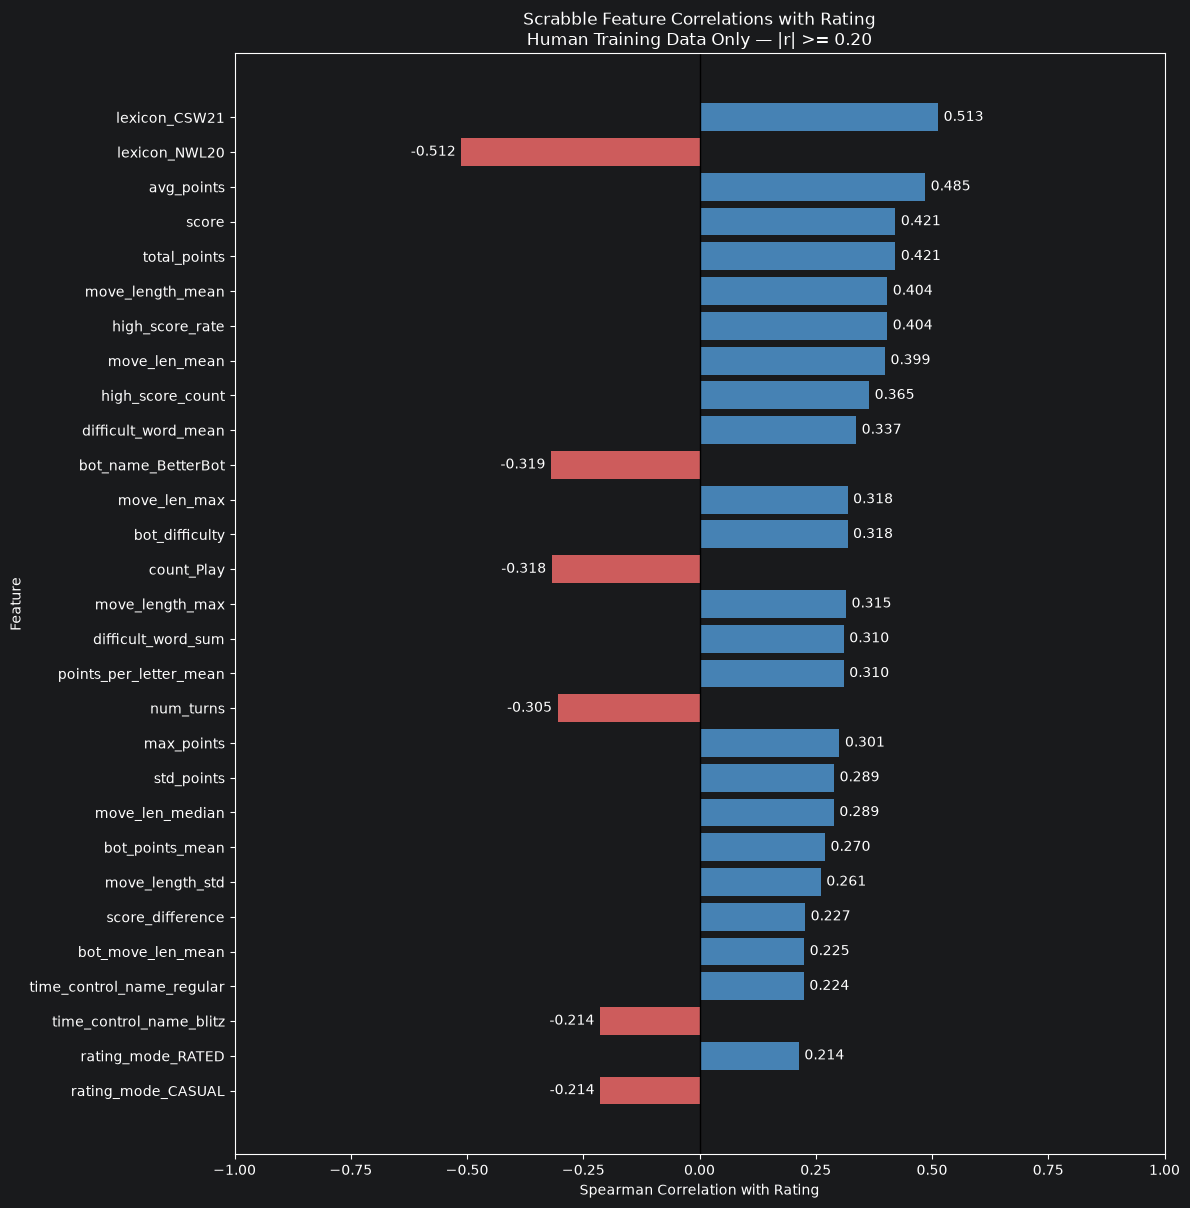

In [33]:


bots = {"BetterBot", "HastyBot", "STEEBot", "BB-8"}

df = expanded_data.copy()

# define original 56 features


original_features = [
    "score",
    "avg_points",
    "num_turns",
    "max_points",
    "std_points",
    "game_duration_seconds",
    "initial_time_seconds",
    "increment_seconds",
    "max_overtime_minutes",
    "score_difference",
    "rating_mode",
    "lexicon",
    "time_control_name",
    "game_end_reason",
    "played_first",
    "player_won",
    "count_Challenge",
    "count_End",
    "count_Exchange",
    "count_Pass",
    "count_Play",
    "count_Six-Zero Rule",
    "count_Timeout",
    "count_Unknown",
    "rate_Challenge",
    "rate_End",
    "rate_Exchange",
    "rate_Pass",
    "rate_Play",
    "rate_Six-Zero Rule",
    "rate_Timeout",
    "rate_Unknown",
    "high_score_count",
    "high_score_rate",
    "move_length_mean",
    "move_length_std",
    "move_length_max",
    "rack_vowel_ratio_mean",
    "rack_vowel_ratio_std",
    "move_len_mean",
    "move_len_max",
    "difficult_word_mean",
    "difficult_word_sum",
    "difficult_letters_mean",
    "difficult_letters_sum",
    "points_per_letter_mean",
    "curr_board_pieces_used_mean",
    "bot_score",
    "bot_name",
    "bot_points_mean",
    "bot_move_len_mean",
    "avg_points_diff",
    "avg_move_len_diff",
    "avg_points_per_letter_diff",
    "opponent_score",
    "total_points"
]

# Legacy alias used by the interaction and XGBoost cells.
all_gameplay_features = list(original_features)

#prepare original features


# total_points is identical to score in our dataset
if "total_points" not in df.columns:
    df["total_points"] = df["score"]

# opponent_score can be recovered from score difference
if "opponent_score" not in df.columns:
    df["opponent_score"] = (
        df["score"] - df["score_difference"]
    )

missing = [
    col for col in original_features
    if col not in df.columns
]

assert not missing, (
    f"Missing original features: {missing}"
)



t = turns.loc[
    turns["turn_type"] == "Play"
].copy()

t["move_letters"] = (
    t["move"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_len"] = (
    t["move_letters"].str.len().astype(float)
)

# missing or empty moves should not count as length 0
t.loc[t["move_len"] == 0, "move_len"] = np.nan

move_stats = (
    t.groupby(["game_id", "nickname"])
    .agg(
        move_len_mean=("move_len", "mean"),
        move_len_median=("move_len", "median")
    )
    .reset_index()
)

# replace existing mean with the consistent Play-only version
df = (
    df.drop(
        columns=["move_len_mean", "move_len_median"],
        errors="ignore"
    )
    .merge(
        move_stats,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)



human_mask = ~df["nickname"].isin(bots)

train_mask = (
    df["game_id"].isin(train_game_ids)
    & human_mask
)

val_mask = (
    df["game_id"].isin(val_game_ids)
    & human_mask
)

assert train_mask.sum() > 0
assert not (train_mask & val_mask).any()

train_games = set(df.loc[train_mask, "game_id"])
val_games = set(df.loc[val_mask, "game_id"])

train_players = set(df.loc[train_mask, "nickname"])
val_players = set(df.loc[val_mask, "nickname"])

assert train_games.isdisjoint(val_games)
assert train_players.isdisjoint(val_players)

# training only standardization helper


def train_zscore(values):
    values = pd.to_numeric(
        values, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    train_values = values.loc[train_mask]

    mean = train_values.mean()
    std = train_values.std(ddof=0)

    if not np.isfinite(std) or std == 0:
        raise ValueError(
            "Feature cannot be standardized: "
            "zero or invalid training standard deviation"
        )

    return (values - mean) / std


score = pd.to_numeric(
    df["score"], errors="coerce"
)

duration = pd.to_numeric(
    df["game_duration_seconds"], errors="coerce"
)

score_per_sec = (
    score / duration.where(duration > 0)
)

df["score_per_sec_scaled_sq"] = (
    train_zscore(score_per_sec) ** 2
)



df["opp_score_scaled"] = (
    train_zscore(df["opponent_score"])
)

df["opp_score_scaled_sq"] = (
    df["opp_score_scaled"] ** 2
)

increment = pd.to_numeric(
    df["increment_seconds"], errors="coerce"
)

df["increment_seconds_log"] = np.log1p(
    increment.where(increment >= 0)
)



df["Play_turn_count_scaled_sq"] = (
    train_zscore(df["count_Play"]) ** 2
)


difficulty_map = {
    "BetterBot": 0,
    "STEEBot": 1,
    "HastyBot": 2
}

if "bot_name" in df.columns:
    bot_names = df["bot_name"]
elif "opponent_nickname" in df.columns:
    bot_names = df["opponent_nickname"]
else:
    raise ValueError(
        "bot_name / opponent_nickname is missing"
    )

df["bot_difficulty"] = (
    bot_names.map(difficulty_map)
)

df["bot_difficulty_1"] = (
    (df["bot_difficulty"] == 1).astype(float)
)

df["win_x_bot2"] = (
    pd.to_numeric(
        df["player_won"], errors="coerce"
    )
    * (df["bot_difficulty"] == 2).astype(float)
)

# preserve missing bot identity
for col in ["bot_difficulty_1", "win_x_bot2"]:
    df.loc[
        df["bot_difficulty"].isna(), col
    ] = np.nan

# combine all features

new_engineered_features = [
    "move_len_median",
    "score_per_sec_scaled_sq",
    "opp_score_scaled",
    "opp_score_scaled_sq",
    "increment_seconds_log",
    "Play_turn_count_scaled_sq",
    "bot_difficulty",
    "bot_difficulty_1",
    "win_x_bot2"
]

all_features = list(dict.fromkeys(
    original_features + new_engineered_features
))

excluded_features = {
    "rating",
    "game_id",
    "nickname",
    "bot_rating",
    "opponent_rating",
    "historical_score_mean",
    "historical_score_std",
    "historical_games_count"
}

all_features = [
    col for col in all_features
    if col not in excluded_features
    and not col.startswith("historical_")
]

assert all(
    col in df.columns for col in all_features
)

# Persist the new features
expanded_data = df.copy()

print("Total features:", len(all_features))



correlation_data = expanded_data.loc[
    train_mask, all_features + ["rating"]
].copy()


categorical_cols = [
    "rating_mode",
    "lexicon",
    "time_control_name",
    "game_end_reason",
    "bot_name"
]

categorical_cols = [
    c for c in categorical_cols
    if c in correlation_data.columns
]

numeric_cols = [
    c for c in all_features
    if c not in categorical_cols
]

# Numeric features
numeric_data = correlation_data[
    numeric_cols
].apply(pd.to_numeric, errors="coerce")

numeric_data = numeric_data.replace(
    [np.inf, -np.inf], np.nan
)

# One hot encoding TRAIN ONLY
categorical_data = pd.get_dummies(
    correlation_data[categorical_cols],
    dummy_na=True,
    dtype=int
)

# combine for analysis
correlation_matrix_data = pd.concat(
    [
        numeric_data,
        categorical_data,
        correlation_data[["rating"]]
    ],
    axis=1
)



all_correlations = (
    correlation_matrix_data
    .corr(method="spearman")["rating"]
    .drop("rating")
    .dropna()
)

# only absolute correlations >= 0.20
threshold = 0.20

strong_correlations = (
    all_correlations[
        all_correlations.abs() >= threshold
    ]
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False
    )
)

print("\nCorrelation analysis — HUMAN TRAIN ONLY")
print("=" * 60)

print(f"Features before one-hot encoding: {len(all_features)}")
print(f"Features after encoding: "
      f"{len(all_correlations)}")
print(f"Features with |Spearman| >= {threshold}: "
      f"{len(strong_correlations)}")

display(
    strong_correlations.to_frame(
        name="Spearman_with_rating"
    )
)



if len(strong_correlations) > 0:

    plt.figure(
        figsize=(
            12,
            max(6, 0.42 * len(strong_correlations))
        )
    )

    colors = [
        "steelblue" if value >= 0 else "indianred"
        for value in strong_correlations.values
    ]

    bars = plt.barh(
        strong_correlations.index,
        strong_correlations.values,
        color=colors
    )

    plt.gca().invert_yaxis()
    plt.axvline(0, color="black", linewidth=1)

    plt.xlabel("Spearman Correlation with Rating")
    plt.ylabel("Feature")

    plt.title(
        "Scrabble Feature Correlations with Rating\n"
        "Human Training Data Only — |r| >= 0.20"
    )

    plt.xlim(-1, 1)

    plt.bar_label(
        bars,
        fmt="%.3f",
        padding=4
    )

    plt.tight_layout()
    plt.show()

else:
    print(
        "No features met the correlation threshold."
    )


In [34]:
print("test_raw" in globals())
print("test_features" in globals())
print("X_test" in globals())

False
False
False


In [35]:


BOARD_SIZE = 15
EMPTY = "·"

def reconstruct_final_board(game_turns):
    board = np.full(
        (BOARD_SIZE, BOARD_SIZE),
        EMPTY,
        dtype="<U1"
    )

    ordered = game_turns.sort_values(
        "turn_number", kind="stable"
    )

    previous_play = None
    errors = []
    challenges_undone = 0

    for row in ordered.itertuples(index=False):
        turn_type = row.turn_type
        location = row.location
        move = row.move

        if turn_type == "Play":

            if pd.isna(location) or pd.isna(move):
                errors.append(
                    f"Turn {row.turn_number}: missing move/location"
                )
                previous_play = None
                continue

            location = str(location).upper()
            move = str(move)

            # Letter-first = vertical; number-first = horizontal
            vertical_match = re.fullmatch(
                r"([A-O])(1[0-5]|[1-9])", location
            )
            horizontal_match = re.fullmatch(
                r"(1[0-5]|[1-9])([A-O])", location
            )

            if vertical_match:
                col = ord(vertical_match.group(1)) - ord("A")
                start_row = int(vertical_match.group(2)) - 1
                dr, dc = 1, 0

            elif horizontal_match:
                start_row = int(horizontal_match.group(1)) - 1
                col = ord(horizontal_match.group(2)) - ord("A")
                dr, dc = 0, 1

            else:
                errors.append(
                    f"Turn {row.turn_number}: invalid location {location}"
                )
                previous_play = None
                continue

            # Validate the whole move before changing the board
            placements = []
            valid = True

            for offset, letter in enumerate(move):
                r = start_row + dr * offset
                c = col + dc * offset

                if not (0 <= r < 15 and 0 <= c < 15):
                    errors.append(
                        f"Turn {row.turn_number}: move exceeds board"
                    )
                    valid = False
                    break

                existing = board[r, c]

                if letter == ".":
                    if existing == EMPTY:
                        errors.append(
                            f"Turn {row.turn_number}: "
                            f"overlap with empty square"
                        )
                        valid = False
                        break
                elif letter.isalpha():
                    if existing != EMPTY:
                        errors.append(
                            f"Turn {row.turn_number}: "
                            f"tile conflict at {r+1},{c+1}"
                        )
                        valid = False
                        break
                    placements.append((r, c, letter))
                else:
                    errors.append(
                        f"Turn {row.turn_number}: "
                        f"unexpected character {letter!r}"
                    )
                    valid = False
                    break

            if not valid:
                previous_play = None
                continue

            before_play = board.copy()

            for r, c, letter in placements:
                board[r, c] = letter

            previous_play = {
                "nickname": row.nickname,
                "points": row.points,
                "board_before": before_play
            }

        elif (
            turn_type == "Exchange"
            and previous_play is not None
            and row.nickname == previous_play["nickname"]
            and pd.to_numeric(row.points, errors="coerce") < 0
            and row.points == -previous_play["points"]
        ):
            # Successful challenge: remove the previous play
            board = previous_play["board_before"].copy()
            challenges_undone += 1
            previous_play = None

        else:
            # Pass, unsuccessful Challenge, End, Timeout, etc.
            previous_play = None

    return board, errors, challenges_undone

# ------------------------------------------------------------
# Select one game for inspection
# ------------------------------------------------------------

GAME_ID = int(turns["game_id"].iloc[0])

game_turns = turns.loc[
    turns["game_id"] == GAME_ID
]

final_board, board_errors, undone = (
    reconstruct_final_board(game_turns)
)

board_df = pd.DataFrame(
    final_board,
    index=range(1, 16),
    columns=list("ABCDEFGHIJKLMNO")
)

print(f"Game ID: {GAME_ID}")
print(f"Total turns: {len(game_turns)}")
print(f"Tiles on final board: {np.sum(final_board != EMPTY)}")
print(f"Successful challenges undone: {undone}")
print(f"Reconstruction issues: {len(board_errors)}")

display(board_df)

if board_errors:
    print("Issues:")
    for error in board_errors[:10]:
        print("-", error)

Game ID: 1
Total turns: 27
Tiles on final board: 99
Successful challenges undone: 0
Reconstruction issues: 0


,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O
1,·,·,·,·,·,·,F,A,I,N,·,·,·,·,N
2,·,Q,·,·,·,B,A,I,T,E,R,·,·,M,A
3,W,I,N,G,L,E,T,·,·,·,·,·,T,O,Y
4,·,·,E,·,·,·,·,·,·,·,·,·,I,S,·
5,·,·,U,·,R,A,J,A,S,·,U,M,P,S,·
6,·,·,R,·,·,H,O,·,L,U,T,E,·,Y,·
7,·,D,O,N,N,A,·,H,A,P,·,D,·,·,·
8,K,E,N,·,·,·,D,I,G,·,V,I,G,O,r
9,·,F,A,E,R,I,E,S,·,·,·,C,·,·,E
10,·,·,L,·,I,·,·,·,·,·,·,A,·,·,l


BOARD FEATURE CORRELATIONS — HUMAN TRAIN ONLY
Successfully reconstructed games: 35111
Failed games: 47
Human observations: 30511
Features analyzed: 24

All correlations:


,Spearman_with_rating
avg_tiles_per_play,0.402097
seven_tile_play_rate,0.387606
points_per_placed_tile,0.385639
seven_tile_play_count,0.360748
points_per_base_tile_value,0.360589
tile_placement_std,0.295463
median_tiles_per_play,0.289362
max_tiles_per_play,0.282446
player_final_tile_share,0.207513
player_tile_share,0.207513


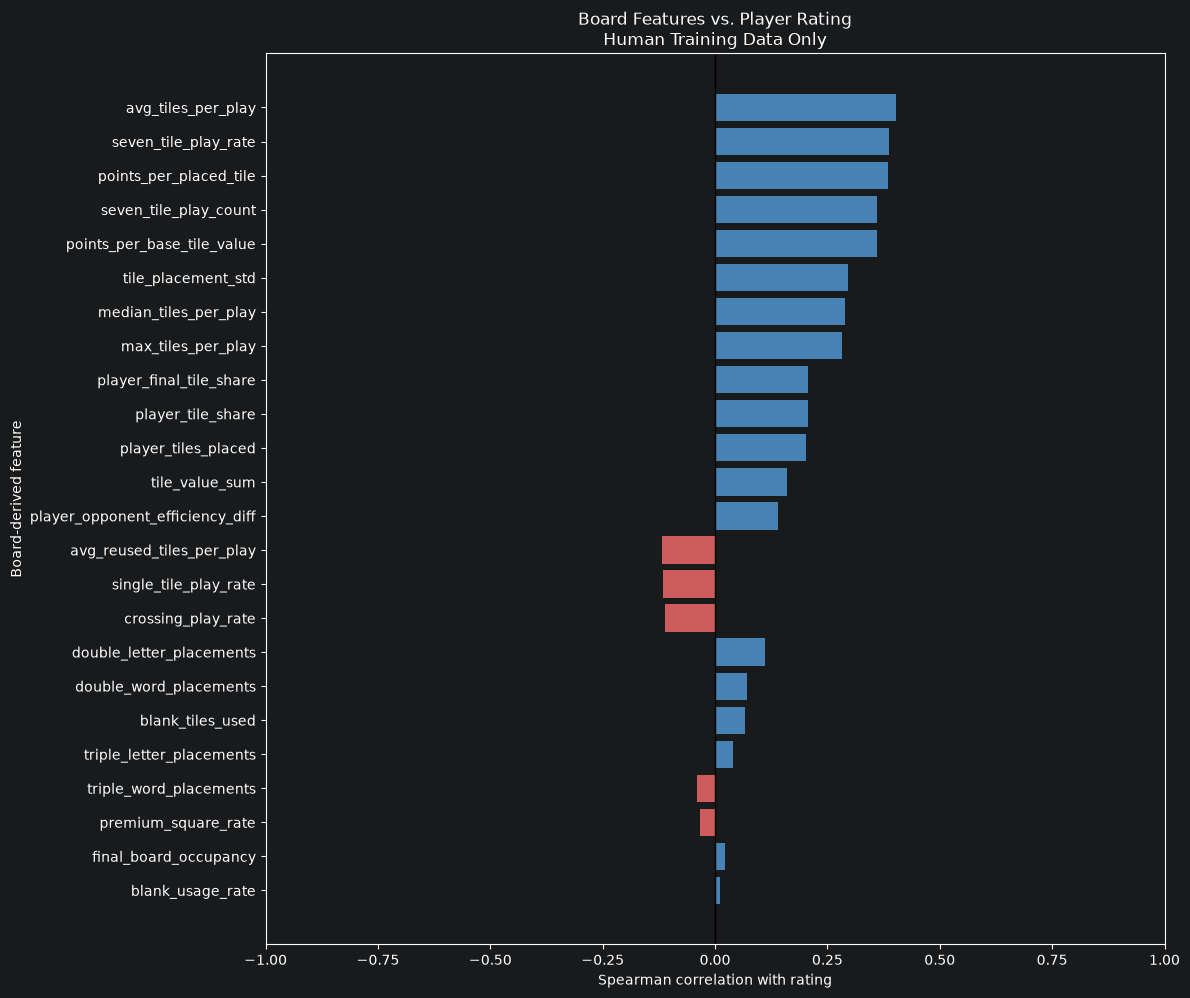


First reconstruction errors:


,game_id,error
0,1678,Reused empty square
1,1903,Reused empty square
2,3263,Missing location or move
3,3802,Missing location or move
4,3846,Missing location or move
5,5104,Reused empty square
6,5232,Missing location or move
7,5939,Reused empty square
8,8924,Missing location or move
9,11667,Missing location or move



Kaggle test set: NOT accessed.
Validation/holdout ratings: NOT accessed.


In [36]:

# ============================================================
# SCRABBLE BOARD FEATURES + RATING CORRELATIONS
#
# High-priority board and player features
# Human TRAINING games only
# No Kaggle test, validation, or holdout data
# ============================================================


BOTS = {"BetterBot", "HastyBot", "STEEBot", "BB-8"}
BOARD_SIZE = 15
EMPTY = ""

# ------------------------------------------------------------
# 1. Scrabble tile values and premium squares
# ------------------------------------------------------------

TILE_VALUES = {
    **dict.fromkeys("AEILNORSTU", 1),
    **dict.fromkeys("DG", 2),
    **dict.fromkeys("BCMP", 3),
    **dict.fromkeys("FHVWY", 4),
    "K": 5,
    **dict.fromkeys("JX", 8),
    **dict.fromkeys("QZ", 10)
}

TW = {
    (0, 0), (0, 7), (0, 14),
    (7, 0), (7, 14),
    (14, 0), (14, 7), (14, 14)
}

DW = {(7, 7)}

for i in [1, 2, 3, 4, 10, 11, 12, 13]:
    DW.add((i, i))
    DW.add((i, 14 - i))

TL = {
    (1, 5), (1, 9),
    (5, 1), (5, 5), (5, 9), (5, 13),
    (9, 1), (9, 5), (9, 9), (9, 13),
    (13, 5), (13, 9)
}

DL = {
    (0, 3), (0, 11),
    (2, 6), (2, 8),
    (3, 0), (3, 7), (3, 14),
    (6, 2), (6, 6), (6, 8), (6, 12),
    (7, 3), (7, 11),
    (8, 2), (8, 6), (8, 8), (8, 12),
    (11, 0), (11, 7), (11, 14),
    (12, 6), (12, 8),
    (14, 3), (14, 11)
}

# ------------------------------------------------------------
# 2. Parse Scrabble move coordinates
# ------------------------------------------------------------

def parse_location(location):
    location = str(location).strip().upper()

    # 8H: horizontal (row 8, column H)
    horizontal = re.fullmatch(
        r"(1[0-5]|[1-9])([A-O])", location
    )

    if horizontal:
        row = int(horizontal.group(1)) - 1
        col = ord(horizontal.group(2)) - ord("A")
        return row, col, 0, 1

    # H8: vertical (column H, row 8)
    vertical = re.fullmatch(
        r"([A-O])(1[0-5]|[1-9])", location
    )

    if vertical:
        col = ord(vertical.group(1)) - ord("A")
        row = int(vertical.group(2)) - 1
        return row, col, 1, 0

    raise ValueError(f"Invalid location: {location}")


# ------------------------------------------------------------
# 3. Reconstruct one game and track successful plays
# ------------------------------------------------------------

def reconstruct_player_board_features(game_turns):

    board = np.full(
        (BOARD_SIZE, BOARD_SIZE),
        EMPTY,
        dtype=object
    )

    owners = np.full(
        (BOARD_SIZE, BOARD_SIZE),
        EMPTY,
        dtype=object
    )

    records = []

    # Keep original ordering for equal turn numbers
    ordered = game_turns.sort_values(
        "turn_number", kind="stable"
    )

    previous_play = None

    for turn in ordered.itertuples(index=False):

        kind = turn.turn_type
        nickname = turn.nickname
        points = pd.to_numeric(turn.points, errors="coerce")

        if kind == "Play":

            if pd.isna(turn.location) or pd.isna(turn.move):
                raise ValueError("Missing location or move")

            row, col, dr, dc = parse_location(turn.location)
            move = str(turn.move)

            placements = []
            reused_tiles = 0

            # Validate before committing
            for offset, letter in enumerate(move):

                r = row + offset * dr
                c = col + offset * dc

                if not (0 <= r < 15 and 0 <= c < 15):
                    raise ValueError("Move outside board")

                existing = board[r, c]

                if letter == ".":
                    if existing == EMPTY:
                        raise ValueError(
                            "Reused empty square"
                        )
                    reused_tiles += 1

                elif letter.isalpha():

                    if existing != EMPTY:
                        raise ValueError(
                            "Conflicting tile placement"
                        )

                    placements.append((r, c, letter))

                else:
                    raise ValueError(
                        f"Unexpected move character: {letter}"
                    )

            if len(placements) == 0:
                raise ValueError("Play contains no new tiles")

            # Record the board before the play
            snapshot_board = board.copy()
            snapshot_owners = owners.copy()

            tile_value_sum = 0
            blank_count = 0
            tw_count = 0
            dw_count = 0
            tl_count = 0
            dl_count = 0

            for r, c, letter in placements:

                board[r, c] = letter
                owners[r, c] = nickname

                is_blank = letter.islower()

                if is_blank:
                    blank_count += 1
                    value = 0
                else:
                    value = TILE_VALUES.get(
                        letter.upper(), 0
                    )

                tile_value_sum += value

                if (r, c) in TW:
                    tw_count += 1
                if (r, c) in DW:
                    dw_count += 1
                if (r, c) in TL:
                    tl_count += 1
                if (r, c) in DL:
                    dl_count += 1

            record = {
                "nickname": nickname,
                "points": points,
                "tiles_placed": len(placements),
                "reused_tiles": reused_tiles,
                "seven_tile_play": int(
                    len(placements) == 7
                ),
                "single_tile_play": int(
                    len(placements) == 1
                ),
                "crossing_play": int(
                    reused_tiles > 0
                ),
                "triple_word_placements": tw_count,
                "double_word_placements": dw_count,
                "triple_letter_placements": tl_count,
                "double_letter_placements": dl_count,
                "blank_tiles_used": blank_count,
                "tile_value_sum": tile_value_sum
            }

            records.append(record)

            previous_play = {
                "nickname": nickname,
                "points": points,
                "board_before": snapshot_board,
                "owners_before": snapshot_owners,
                "record_index": len(records) - 1
            }

        # Challenge reversal represented as negative
        # Exchange points for the previous play's owner.
        elif (
            kind == "Exchange"
            and previous_play is not None
            and nickname == previous_play["nickname"]
            and pd.notna(points)
            and pd.notna(previous_play["points"])
            and points < 0
            and np.isclose(
                points, -previous_play["points"]
            )
        ):

            board = previous_play["board_before"]
            owners = previous_play["owners_before"]

            # Remove the unsuccessful play from records
            records.pop(previous_play["record_index"])

            previous_play = None

        else:
            # Pass, ordinary Exchange, Challenge, End, etc.
            previous_play = None

    return board, owners, records


# ------------------------------------------------------------
# 4. Aggregate features per player-game
# ------------------------------------------------------------

def calculate_board_features(game_id, game_turns):

    board, owners, records = (
        reconstruct_player_board_features(game_turns)
    )

    if not records:
        return []

    play_df = pd.DataFrame(records)

    final_tiles = int(np.sum(board != EMPTY))

    results = []

    for nickname, p in play_df.groupby("nickname"):

        total_tiles = p["tiles_placed"].sum()
        total_plays = len(p)

        total_points = p["points"].sum()
        tile_value_sum = p["tile_value_sum"].sum()

        premium_count = (
            p["triple_word_placements"].sum()
            + p["double_word_placements"].sum()
            + p["triple_letter_placements"].sum()
            + p["double_letter_placements"].sum()
        )

        player_final_tiles = int(
            np.sum(owners == nickname)
        )

        results.append({
            "game_id": game_id,
            "nickname": nickname,

            # Tile placement
            "player_tiles_placed": total_tiles,
            "player_tile_share": (
                player_final_tiles / final_tiles
                if final_tiles else np.nan
            ),
            "avg_tiles_per_play": (
                p["tiles_placed"].mean()
            ),
            "median_tiles_per_play": (
                p["tiles_placed"].median()
            ),
            "max_tiles_per_play": (
                p["tiles_placed"].max()
            ),
            "tile_placement_std": (
                p["tiles_placed"].std()
            ),
            "seven_tile_play_count": (
                p["seven_tile_play"].sum()
            ),
            "seven_tile_play_rate": (
                p["seven_tile_play"].mean()
            ),
            "single_tile_play_rate": (
                p["single_tile_play"].mean()
            ),

            # Scoring efficiency
            "points_per_placed_tile": (
                total_points / total_tiles
                if total_tiles else np.nan
            ),
            "tile_value_sum": tile_value_sum,
            "points_per_base_tile_value": (
                total_points / tile_value_sum
                if tile_value_sum else np.nan
            ),

            # Premium squares
            "triple_word_placements": (
                p["triple_word_placements"].sum()
            ),
            "double_word_placements": (
                p["double_word_placements"].sum()
            ),
            "triple_letter_placements": (
                p["triple_letter_placements"].sum()
            ),
            "double_letter_placements": (
                p["double_letter_placements"].sum()
            ),
            "premium_square_rate": (
                premium_count / total_tiles
                if total_tiles else np.nan
            ),

            # Reusing board tiles
            "crossing_play_rate": (
                p["crossing_play"].mean()
            ),
            "avg_reused_tiles_per_play": (
                p["reused_tiles"].mean()
            ),

            # Blank usage
            "blank_tiles_used": (
                p["blank_tiles_used"].sum()
            ),
            "blank_usage_rate": (
                p["blank_tiles_used"].sum()
                / total_tiles
                if total_tiles else np.nan
            ),

            # Final board
            "player_final_tile_share": (
                player_final_tiles / final_tiles
                if final_tiles else np.nan
            ),
            "final_board_occupancy": (
                final_tiles / 225
            )
        })

    return results


# ------------------------------------------------------------
# 5. Process TRAINING games only
# ------------------------------------------------------------

training_turns = turns.loc[
    turns["game_id"].isin(train_game_ids)
].copy()

board_feature_rows = []
failed_games = []

for game_id, game_turns in training_turns.groupby(
    "game_id", sort=False
):
    try:
        board_feature_rows.extend(
            calculate_board_features(
                game_id, game_turns
            )
        )
    except (ValueError, IndexError, TypeError) as e:
        failed_games.append({
            "game_id": game_id,
            "error": str(e)
        })

board_features = pd.DataFrame(board_feature_rows)

if board_features.empty:
    raise ValueError(
        "No boards reconstructed successfully. "
        "Check move notation and challenge handling."
    )

# ------------------------------------------------------------
# 6. Add player-vs-opponent efficiency difference
# ------------------------------------------------------------

opponent_efficiency = board_features[
    ["game_id", "nickname", "points_per_placed_tile"]
].rename(columns={
    "nickname": "opponent_nickname",
    "points_per_placed_tile": "opponent_efficiency"
})

board_features = board_features.merge(
    opponent_efficiency,
    on="game_id",
    how="left",
    suffixes=("", "_opp"),
)

board_features = board_features.loc[
    board_features["nickname"]
    != board_features["opponent_nickname"]
].copy()

board_features["player_opponent_efficiency_diff"] = (
    board_features["points_per_placed_tile"]
    - board_features["opponent_efficiency"]
)

board_features = board_features.drop(
    columns=["opponent_nickname", "opponent_efficiency"]
)

# ------------------------------------------------------------
# 7. Join with HUMAN TRAINING ratings
# ------------------------------------------------------------

human_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(BOTS),
    ["game_id", "nickname", "rating"]
].drop_duplicates(["game_id", "nickname"])

correlation_data = human_train.merge(
    board_features,
    on=["game_id", "nickname"],
    how="inner",
    validate="one_to_one"
)

feature_cols = [
    c for c in board_features.columns
    if c not in {"game_id", "nickname"}
]

# ------------------------------------------------------------
# 8. Spearman correlation with rating
# ------------------------------------------------------------

correlations = (
    correlation_data[
        feature_cols + ["rating"]
    ]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .dropna()
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

print("=" * 65)
print("BOARD FEATURE CORRELATIONS — HUMAN TRAIN ONLY")
print("=" * 65)

print("Successfully reconstructed games:",
      board_features["game_id"].nunique())

print("Failed games:", len(failed_games))
print("Human observations:", len(correlation_data))
print("Features analyzed:", len(correlations))

print("\nAll correlations:")
display(
    correlations.to_frame(
        "Spearman_with_rating"
    )
)

# ------------------------------------------------------------
# 9. Correlation chart
# ------------------------------------------------------------

plt.figure(
    figsize=(12, max(7, 0.42 * len(correlations)))
)

colors = [
    "steelblue" if r >= 0 else "indianred"
    for r in correlations
]

plt.barh(
    correlations.index,
    correlations.values,
    color=colors
)

plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Spearman correlation with rating")
plt.ylabel("Board-derived feature")
plt.title(
    "Board Features vs. Player Rating\n"
    "Human Training Data Only"
)

plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Reconstruction errors
# ------------------------------------------------------------

failed_boards_df = pd.DataFrame(failed_games)

if len(failed_boards_df):
    print("\nFirst reconstruction errors:")
    display(failed_boards_df.head(10))

print("\nKaggle test set: NOT accessed.")
print("Validation/holdout ratings: NOT accessed.")


Training rows: 30574
Validation rows: 4980
SUCCESS: Holdout is excluded.
Candidate features: 75
Training rows: 30574
Validation rows: 4980

Prepared 10 grouped CV folds.

GREEDY FORWARD SELECTION
Baseline (no features) CV RMSE: 213.9304
---------------------------------------------------------------------------
01. avg_points                                              RMSE=187.2208 Improvement=26.7097
02. lexicon                                                 RMSE=161.2791 Improvement=25.9417
03. move_len_mean                                           RMSE=158.6845 Improvement=2.5946
04. interaction__move_len_mean__x__avg_points               RMSE=156.4793 Improvement=2.2051
05. bot_difficulty                                          RMSE=154.4211 Improvement=2.0583
06. time_control_name                                       RMSE=151.7424 Improvement=2.6787
07. rating_mode                                             RMSE=147.8147 Improvement=3.9276
08. score                         

,Step,Feature,CV_RMSE,Improvement
0,1,avg_points,187.220785,26.709656
1,2,lexicon,161.279062,25.941723
2,3,move_len_mean,158.684470,2.594592
3,4,interaction__move_len_mean__x__avg_points,156.479333,2.205137
4,5,bot_difficulty,154.421066,2.058267
5,6,time_control_name,151.742358,2.678708
6,7,rating_mode,147.814709,3.927649
7,8,score,146.522443,1.292266
8,9,Play_turn_count_scaled_sq,146.220036,0.302407
9,10,interaction__high_score_rate__x__avg_points,145.970077,0.249958


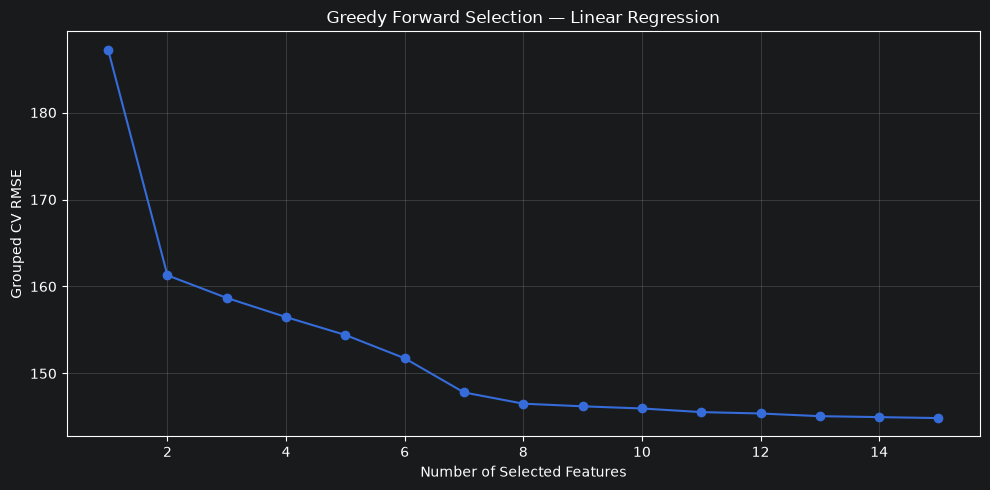

In [37]:

CV_FOLDS = 10
MAX_SELECTED_FEATURES = 50
MIN_CV_IMPROVEMENT = 0.1  # Minimum RMSE improvement to add a feature

bots = {
    "BetterBot",
    "HastyBot",
    "STEEBot",
    "BB-8"
}


development_game_ids = set(train_game_ids) | set(val_game_ids)

df = expanded_data.loc[
    ~expanded_data["nickname"].isin(bots)
    & expanded_data["game_id"].isin(development_game_ids)
].copy()

train_mask = df["game_id"].isin(train_game_ids)
val_mask = df["game_id"].isin(val_game_ids)

# Every row must belong to exactly one development split
assert (train_mask | val_mask).all()
assert not (train_mask & val_mask).any()

# Verify game separation
assert set(df.loc[train_mask, "game_id"]).isdisjoint(
    set(df.loc[val_mask, "game_id"])
)

# Verify human player separation
assert set(df.loc[train_mask, "nickname"]).isdisjoint(
    set(df.loc[val_mask, "nickname"])
)

# Verify holdout separation
holdout_ids = globals().get("holdout_game_ids")

if holdout_ids is not None:
    assert set(df["game_id"]).isdisjoint(set(holdout_ids))

print("Training rows:", train_mask.sum())
print("Validation rows:", val_mask.sum())
print("SUCCESS: Holdout is excluded.")

assert (train_mask | val_mask).all()
assert not (train_mask & val_mask).any()

train_df = df.loc[train_mask].copy()
val_df = df.loc[val_mask].copy()

assert set(train_df["nickname"]).isdisjoint(
    set(val_df["nickname"])
)
assert set(train_df["game_id"]).isdisjoint(
    set(val_df["game_id"])
)


if "move_len_median" not in df.columns:

    play_turns = turns.loc[
        turns["turn_type"] == "Play"
    ].copy()

    play_turns["move_len"] = (
        play_turns["move"]
        .astype("string")
        .str.replace(r"[^A-Z]", "", regex=True)
        .str.len()
        .astype(float)
    )

    play_turns.loc[
        play_turns["move_len"] == 0,
        "move_len"
    ] = np.nan

    median_moves = (
        play_turns.groupby(["game_id", "nickname"])
        ["move_len"]
        .median()
        .rename("move_len_median")
        .reset_index()
    )

    df = df.merge(
        median_moves,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )

train_mask = df["game_id"].isin(train_game_ids)
val_mask = df["game_id"].isin(val_game_ids)


# recreate nonlinear features using TRAIN statistics


def zscore_train(series):
    series = pd.to_numeric(
        series, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    mu = series.loc[train_mask].mean()
    std = series.loc[train_mask].std(ddof=0)

    if not np.isfinite(std) or std == 0:
        return pd.Series(np.nan, index=series.index)

    return (series - mu) / std


score = pd.to_numeric(df["score"], errors="coerce")
duration = pd.to_numeric(
    df["game_duration_seconds"], errors="coerce"
)

score_per_sec = score / duration.where(duration > 0)

df["score_per_sec_scaled_sq"] = (
    zscore_train(score_per_sec) ** 2
)

if "opponent_score" not in df.columns:
    df["opponent_score"] = (
        df["score"] - df["score_difference"]
    )

df["opp_score_scaled"] = zscore_train(
    df["opponent_score"]
)

df["opp_score_scaled_sq"] = (
    df["opp_score_scaled"] ** 2
)

increment = pd.to_numeric(
    df["increment_seconds"], errors="coerce"
)

df["increment_seconds_log"] = np.log1p(
    increment.where(increment >= 0)
)

df["Play_turn_count_scaled_sq"] = (
    zscore_train(df["count_Play"]) ** 2
)

difficulty_map = {
    "BetterBot": 0,
    "STEEBot": 1,
    "HastyBot": 2
}

bot_names = (
    df["bot_name"]
    if "bot_name" in df.columns
    else df["opponent_nickname"]
)

df["bot_difficulty"] = bot_names.map(difficulty_map)

df["bot_difficulty_1"] = (
    df["bot_difficulty"] == 1
).astype(float)

df["win_x_bot2"] = (
    pd.to_numeric(df["player_won"], errors="coerce")
    * (df["bot_difficulty"] == 2).astype(float)
)

for col in ["bot_difficulty_1", "win_x_bot2"]:
    df.loc[
        df["bot_difficulty"].isna(), col
    ] = np.nan

nonlinear_features = [
    "move_len_median",
    "score_per_sec_scaled_sq",
    "opp_score_scaled",
    "opp_score_scaled_sq",
    "increment_seconds_log",
    "Play_turn_count_scaled_sq",
    "bot_difficulty",
    "bot_difficulty_1",
    "win_x_bot2"
]


interaction_pairs = [
    ("score", "game_duration_seconds"),
    ("avg_points", "num_turns"),
    ("score_difference", "bot_points_mean"),
    ("avg_points", "bot_points_mean"),
    ("move_len_mean", "points_per_letter_mean"),
    ("move_len_mean", "avg_points"),
    ("difficult_word_mean", "points_per_letter_mean"),
    ("high_score_rate", "avg_points"),
    ("rate_Exchange", "avg_points"),
    ("curr_board_pieces_used_mean", "move_len_mean")
]

interaction_features = []

for a, b in interaction_pairs:

    if a not in df.columns or b not in df.columns:
        raise ValueError(f"Missing interaction inputs: {a}, {b}")

    name = f"interaction__{a}__x__{b}"

    df[name] = (
        pd.to_numeric(df[a], errors="coerce")
        * pd.to_numeric(df[b], errors="coerce")
    )

    interaction_features.append(name)

# build complete feature pool


# prefer the complete list from our recent feature cell.
# otherwise use the original notebook's feature list.

if "all_features" in globals():
    original_pool = list(all_features)

elif "all_gameplay_features" in globals():
    original_pool = list(all_gameplay_features)

else:
    raise ValueError(
        "Run the all-features engineering cell first."
    )

excluded_features = {
    "rating",
    "game_id",
    "nickname",
    "opponent_nickname",
    "first",
    "bot_rating",
    "opponent_rating",
    "historical_score_mean",
    "historical_score_std",
    "historical_games_count"
}

feature_pool = list(dict.fromkeys(
    original_pool
    + nonlinear_features
    + interaction_features
))

feature_pool = [
    col for col in feature_pool
    if col in df.columns
    and col not in excluded_features
    and not col.startswith("historical_")
]

categorical_cols = [
    c for c in [
        "rating_mode",
        "lexicon",
        "time_control_name",
        "game_end_reason",
        "bot_name"
    ]
    if c in feature_pool
]

numerical_cols = [
    c for c in feature_pool
    if c not in categorical_cols
]


train_df = df.loc[train_mask].copy()
val_df = df.loc[val_mask].copy()

X_train = train_df[feature_pool].copy()
X_val = val_df[feature_pool].copy()

y_train = train_df["rating"].to_numpy(dtype=float)
y_val = val_df["rating"].to_numpy(dtype=float)

for col in numerical_cols:

    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    )

    X_val[col] = pd.to_numeric(
        X_val[col], errors="coerce"
    )

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)

for col in categorical_cols:
    X_train[col] = (
        X_train[col].astype("string").fillna("Missing").astype(str)
    )
    X_val[col] = (
        X_val[col].astype("string").fillna("Missing").astype(str)
    )

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()

print("Candidate features:", len(feature_pool))
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))



parent = {
    game_id: game_id
    for game_id in train_df["game_id"].unique()
}

def find(game_id):
    while parent[game_id] != game_id:
        parent[game_id] = parent[parent[game_id]]
        game_id = parent[game_id]
    return game_id

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

first_game = {}

for game_id, nickname in train_df[
    ["game_id", "nickname"]
].itertuples(index=False, name=None):

    if nickname in first_game:
        union(game_id, first_game[nickname])
    else:
        first_game[nickname] = game_id

cv_groups = train_df["game_id"].map(find).to_numpy()

assert len(set(cv_groups)) >= CV_FOLDS

cv = GroupKFold(n_splits=CV_FOLDS)

fold_indices = list(
    cv.split(X_train, y_train, groups=cv_groups)
)


fold_cache = []

for fold_num, (idx_tr, idx_cv) in enumerate(
    fold_indices, start=1
):

    transformers = []

    if numerical_cols:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median",
                    keep_empty_features=True
                )),
                ("scaler", StandardScaler())
            ]),
            numerical_cols
        ))

    if categorical_cols:
        transformers.append((
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ))

    prep = ColumnTransformer(
        transformers,
        sparse_threshold=0
    )

    A = np.asarray(
        prep.fit_transform(X_train.iloc[idx_tr]),
        dtype=float
    )

    B = np.asarray(
        prep.transform(X_train.iloc[idx_cv]),
        dtype=float
    )

    # map each original feature to its encoded columns
    column_map = {}
    offset = 0

    for col in numerical_cols:
        column_map[col] = [offset]
        offset += 1

    if categorical_cols:

        encoder = prep.named_transformers_["cat"]

        for col, categories in zip(
            categorical_cols, encoder.categories_
        ):
            width = len(categories)
            column_map[col] = list(
                range(offset, offset + width)
            )
            offset += width

    assert offset == A.shape[1]

    fold_cache.append({
        "X_train": A,
        "X_cv": B,
        "y_train": y_train[idx_tr],
        "y_cv": y_train[idx_cv],
        "column_map": column_map
    })

print(f"\nPrepared {CV_FOLDS} grouped CV folds.")



def evaluate_subset(selected):

    squared_error_sum = 0.0
    total_rows = 0

    for fold in fold_cache:

        if not selected:
            # Intercept-only baseline
            predictions = np.full(
                len(fold["y_cv"]),
                fold["y_train"].mean()
            )

        else:
            indices = [
                idx
                for feature in selected
                for idx in fold["column_map"][feature]
            ]

            model = LinearRegression()

            model.fit(
                fold["X_train"][:, indices],
                fold["y_train"]
            )

            predictions = model.predict(
                fold["X_cv"][:, indices]
            )

        errors = fold["y_cv"] - predictions

        squared_error_sum += np.sum(errors ** 2)
        total_rows += len(errors)

    return np.sqrt(squared_error_sum / total_rows)


# GREEDY FORWARD SEARCH


selected_features_greedy = []
remaining_features = feature_pool.copy()

current_rmse = evaluate_subset([])

selection_history = []

print("\nGREEDY FORWARD SELECTION")
print("=" * 75)
print(f"Baseline (no features) CV RMSE: {current_rmse:.4f}")
print("-" * 75)

for step in range(
    min(MAX_SELECTED_FEATURES, len(feature_pool))
):

    best_feature = None
    best_rmse = float("inf")

    # Test adding each remaining feature
    for candidate in remaining_features:

        trial_features = (
            selected_features_greedy + [candidate]
        )

        trial_rmse = evaluate_subset(trial_features)

        if trial_rmse < best_rmse:
            best_rmse = trial_rmse
            best_feature = candidate

    improvement = current_rmse - best_rmse

    # Stop if no meaningful improvement
    if improvement <= MIN_CV_IMPROVEMENT:

        print(
            f"\nStopping: best remaining feature "
            f"improves CV RMSE by only {improvement:.4f}"
        )
        break

    # Add best feature
    selected_features_greedy.append(best_feature)
    remaining_features.remove(best_feature)

    current_rmse = best_rmse

    selection_history.append({
        "Step": step + 1,
        "Feature": best_feature,
        "CV_RMSE": current_rmse,
        "Improvement": improvement
    })

    print(
        f"{step + 1:02d}. {best_feature:<55} "
        f"RMSE={current_rmse:.4f} "
        f"Improvement={improvement:.4f}"
    )

if not selected_features_greedy:
    raise ValueError("Greedy search selected no features.")


# Final Linear Regression pipeline


selected_num = [
    c for c in selected_features_greedy
    if c in numerical_cols
]

selected_cat = [
    c for c in selected_features_greedy
    if c in categorical_cols
]

final_transformers = []

if selected_num:
    final_transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(
                strategy="median",
                keep_empty_features=True
            )),
            ("scaler", StandardScaler())
        ]),
        selected_num
    ))

if selected_cat:
    final_transformers.append((
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        selected_cat
    ))

greedy_lr_model = Pipeline([
    ("preprocessing", ColumnTransformer(
        final_transformers,
        sparse_threshold=0
    )),
    ("regression", LinearRegression())
])

# Fit on ALL original training observations
greedy_lr_model.fit(
    X_train[selected_features_greedy],
    y_train
)


# Final predictions


greedy_train_pred = greedy_lr_model.predict(
    X_train[selected_features_greedy]
)

greedy_val_pred = greedy_lr_model.predict(
    X_val[selected_features_greedy]
)

train_mse = mean_squared_error(
    y_train, greedy_train_pred
)

val_mse = mean_squared_error(
    y_val, greedy_val_pred
)

train_rmse = np.sqrt(train_mse)
val_rmse = np.sqrt(val_mse)



print("\n" + "=" * 75)
print("FINAL GREEDY LINEAR REGRESSION RESULTS")
print("=" * 75)

print(f"Candidate features:       {len(feature_pool)}")
print(f"Selected features:        {len(selected_features_greedy)}")
print(f"CV folds:                 {CV_FOLDS}")
print(f"Final CV RMSE:            {current_rmse:,.4f}")

print(f"\nTraining observations:    {len(y_train):,}")
print(f"Validation observations:  {len(y_val):,}")

print(f"\nTraining MSE:             {train_mse:,.2f}")
print(f"Training RMSE:            {train_rmse:,.2f}")
print(f"Validation MSE:           {val_mse:,.2f}")
print(f"Validation RMSE:          {val_rmse:,.2f}")
print(f"Validation R²:            {r2_score(y_val, greedy_val_pred):.4f}")

print("\nSelected features (in greedy selection order):")

for i, feature in enumerate(selected_features_greedy, 1):
    print(f"{i:02d}. {feature}")

selection_results = pd.DataFrame(selection_history)

display(selection_results)

# ------------------------------------------------------------
# 14. Plot greedy search progress
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    selection_results["Step"],
    selection_results["CV_RMSE"],
    marker="o"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Grouped CV RMSE")
plt.title("Greedy Forward Selection — Linear Regression")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Interactions to test: 10
Baseline CV RMSE: 151.5067


,Interaction,Baseline_RMSE,Interaction_RMSE,Improvement
0,high_score_rate × avg_points,151.5067,150.2132,1.2935
1,move_len_mean × points_per_letter_mean,151.5067,150.5881,0.9186
2,move_len_mean × avg_points,151.5067,150.6174,0.8893
3,difficult_word_mean × points_per_letter_mean,151.5067,151.1800,0.3267
4,curr_board_pieces_used_mean × move_len_mean,151.5067,151.4357,0.0710
5,avg_points × bot_points_mean,151.5067,151.4805,0.0262
6,rate_Exchange × avg_points,151.5067,151.4808,0.0259
7,avg_points × num_turns,151.5067,151.5067,-0.0000
8,score_difference × bot_points_mean,151.5067,151.5140,-0.0073
9,score × game_duration_seconds,151.5067,151.7027,-0.1960


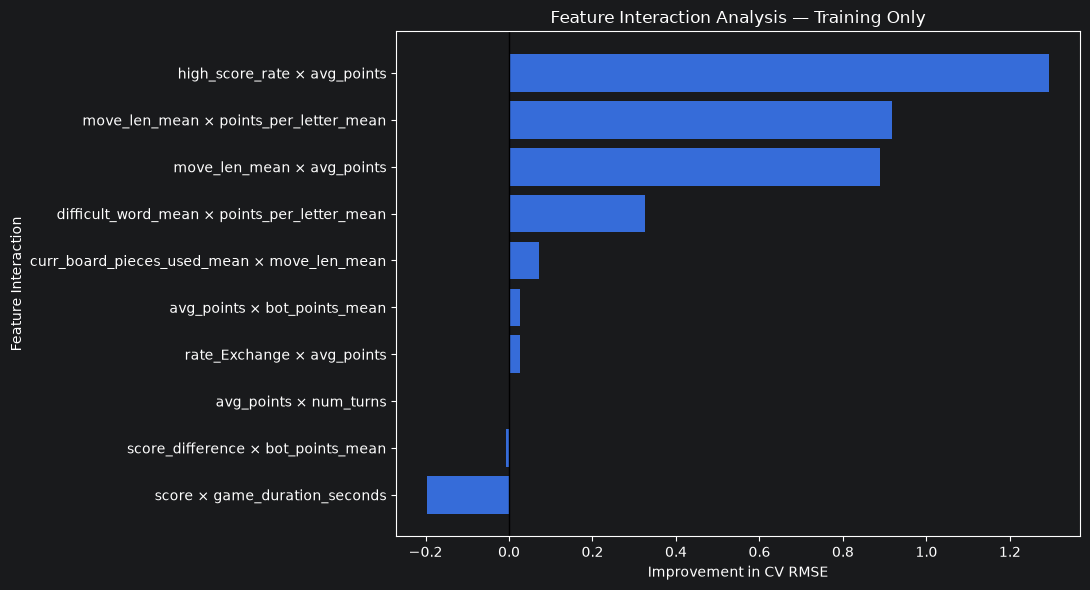

In [38]:


bots = ["BetterBot", "HastyBot", "STEEBot", "BB-8"]

data = expanded_data.loc[
    ~expanded_data["nickname"].isin(bots)
    & expanded_data["game_id"].isin(train_game_ids)
].copy()

assert set(data["game_id"]).isdisjoint(val_game_ids)

# Reuse all gameplay features, excluding player history
excluded = {
    "rating",
    "game_id",
    "nickname",
    "opponent_nickname",
    "first",
    "bot_rating",
    "opponent_rating"
}

feature_cols = [
    c for c in all_gameplay_features
    if c in data.columns
    and c not in excluded
    and not c.startswith("historical_")
]

feature_cols = list(dict.fromkeys(feature_cols))

categorical_cols = [
    c for c in [
        "rating_mode",
        "lexicon",
        "time_control_name",
        "game_end_reason",
        "bot_name"
    ]
    if c in feature_cols
]

numerical_cols = [
    c for c in feature_cols
    if c not in categorical_cols
]

X_base = data[feature_cols].copy()
X_base[numerical_cols] = (
    X_base[numerical_cols]
    .replace([np.inf, -np.inf], np.nan)
)

y = data["rating"]
groups = data["nickname"]


# define candidate interactions


candidate_pairs = [
    ("score", "game_duration_seconds"),
    ("avg_points", "num_turns"),
    ("score_difference", "bot_points_mean"),
    ("avg_points", "bot_points_mean"),
    ("move_len_mean", "points_per_letter_mean"),
    ("move_len_mean", "avg_points"),
    ("difficult_word_mean", "points_per_letter_mean"),
    ("high_score_rate", "avg_points"),
    ("rate_Exchange", "avg_points"),
    ("curr_board_pieces_used_mean", "move_len_mean")
]

candidate_pairs = [
    (a, b) for a, b in candidate_pairs
    if a in numerical_cols and b in numerical_cols
]

print("Interactions to test:", len(candidate_pairs))



def make_model(num_cols, cat_cols):

    preprocessor = ColumnTransformer([
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median",
                    keep_empty_features=True
                )),
                ("scaler", StandardScaler())
            ]),
            num_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="most_frequent"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            cat_cols
        )
    ])

    return Pipeline([
        ("preprocessing", preprocessor),
        ("regression", LinearRegression())
    ])

# Same folds for every interaction
cv = list(
    GroupKFold(n_splits=5).split(X_base, y, groups)
)

def evaluate(model, X):
    fold_mse = -cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )
    return np.sqrt(fold_mse.mean())



baseline_model = make_model(
    numerical_cols,
    categorical_cols
)

baseline_rmse = evaluate(baseline_model, X_base)

print(f"Baseline CV RMSE: {baseline_rmse:.4f}")



results = []

for a, b in candidate_pairs:

    interaction_name = f"{a}__X__{b}"

    X_interaction = X_base.copy()

    X_interaction[interaction_name] = (
        X_interaction[a] * X_interaction[b]
    )

    model = make_model(
        numerical_cols + [interaction_name],
        categorical_cols
    )

    interaction_rmse = evaluate(
        model, X_interaction
    )

    results.append({
        "Interaction": f"{a} × {b}",
        "Baseline_RMSE": baseline_rmse,
        "Interaction_RMSE": interaction_rmse,
        "Improvement": baseline_rmse - interaction_rmse
    })



interaction_results = (
    pd.DataFrame(results)
    .sort_values("Improvement", ascending=False)
    .reset_index(drop=True)
)

display(interaction_results.round(4))



plt.figure(figsize=(11, 6))

plt.barh(
    interaction_results["Interaction"],
    interaction_results["Improvement"]
)

plt.axvline(0, color="black", linewidth=1)
plt.gca().invert_yaxis()

plt.xlabel("Improvement in CV RMSE")
plt.ylabel("Feature Interaction")
plt.title("Feature Interaction Analysis — Training Only")

plt.tight_layout()
plt.show()


MEDIUM BOARD FEATURES — SPEARMAN CORRELATIONS
Training games: 35176
Successfully reconstructed: 35111
Failed reconstructions: 47
Human training observations: 30574
Observations with reconstructed features: 30511
Features analyzed: 22


,Spearman_with_rating
tile_placement_std,0.295463
max_tiles_per_play,0.282446
player_final_tile_share,0.207513
player_opponent_tile_difference,0.206911
board_expansion_rate,0.176063
tile_value_sum,0.160502
player_opponent_efficiency_diff,0.140820
double_letter_placements,0.111516
player_row_diversity,0.053001
player_center_placement_rate,-0.042983


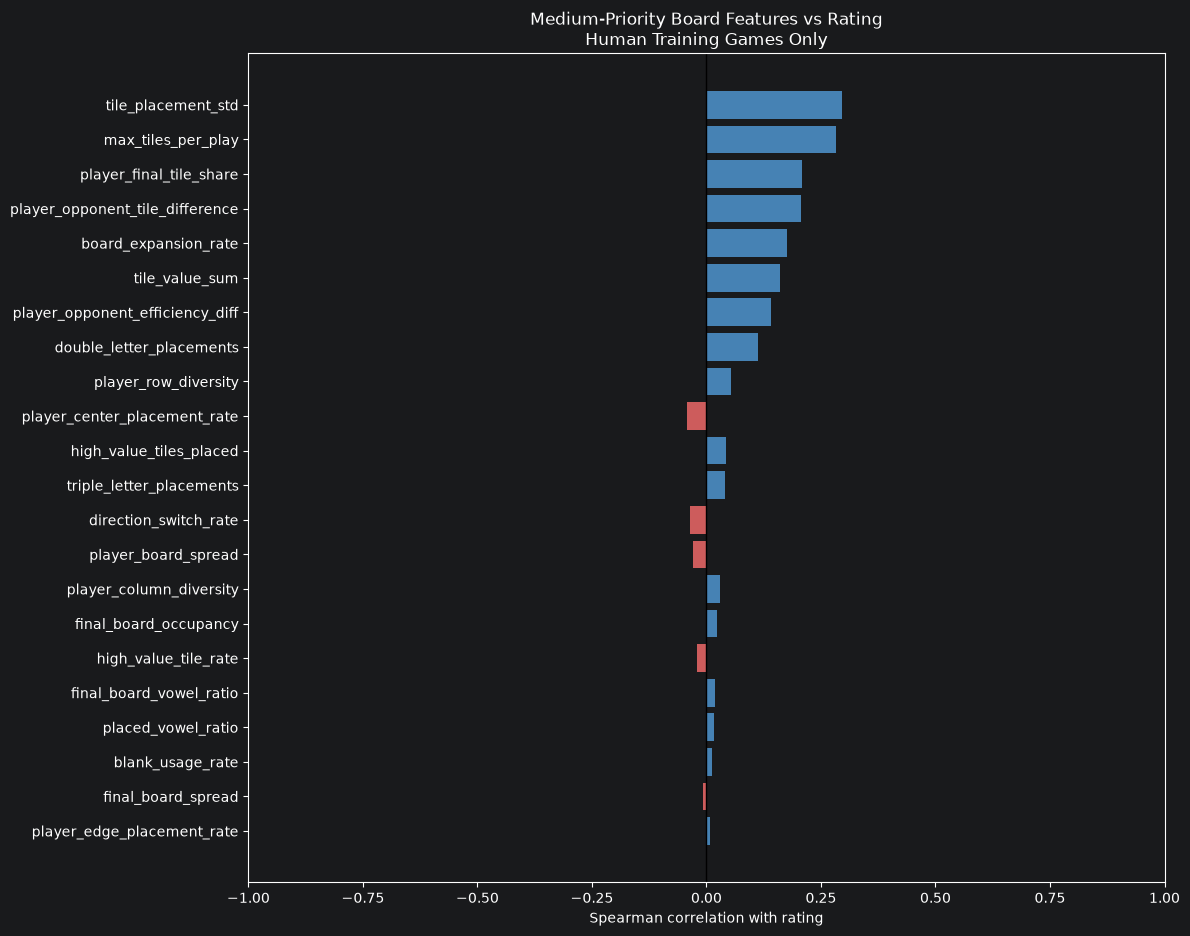


Features with |Spearman| > 0.15:


,Spearman_with_rating
tile_placement_std,0.295463
max_tiles_per_play,0.282446
player_final_tile_share,0.207513
player_opponent_tile_difference,0.206911
board_expansion_rate,0.176063
tile_value_sum,0.160502



First reconstruction failures:


,game_id,error
0,1678,Overlap on empty cell
1,1903,Overlap on empty cell
2,3263,Missing Play location/move
3,3802,Missing Play location/move
4,3846,Missing Play location/move
5,5104,Overlap on empty cell
6,5232,Missing Play location/move
7,5939,Overlap on empty cell
8,8924,Missing Play location/move
9,11667,Missing Play location/move



Kaggle test.csv: NOT accessed.
Validation/holdout ratings: NOT accessed.


In [39]:


BOTS = {"BetterBot", "HastyBot", "STEEBot", "BB-8"}
N = 15

TILE_VALUES = {
    **dict.fromkeys("AEILNORSTU", 1),
    **dict.fromkeys("DG", 2),
    **dict.fromkeys("BCMP", 3),
    **dict.fromkeys("FHVWY", 4),
    "K": 5,
    **dict.fromkeys("JX", 8),
    **dict.fromkeys("QZ", 10)
}

TL = {
    (1, 5), (1, 9),
    (5, 1), (5, 5), (5, 9), (5, 13),
    (9, 1), (9, 5), (9, 9), (9, 13),
    (13, 5), (13, 9)
}

DL = {
    (0, 3), (0, 11),
    (2, 6), (2, 8),
    (3, 0), (3, 7), (3, 14),
    (6, 2), (6, 6), (6, 8), (6, 12),
    (7, 3), (7, 11),
    (8, 2), (8, 6), (8, 8), (8, 12),
    (11, 0), (11, 7), (11, 14),
    (12, 6), (12, 8),
    (14, 3), (14, 11)
}


def medium_parse_location(location):
    s = str(location).strip().upper()

    horizontal = re.fullmatch(
        r"(1[0-5]|[1-9])([A-O])", s
    )
    vertical = re.fullmatch(
        r"([A-O])(1[0-5]|[1-9])", s
    )

    if horizontal:
        return (
            int(horizontal.group(1)) - 1,
            ord(horizontal.group(2)) - 65,
            0, 1, "H"
        )

    if vertical:
        return (
            int(vertical.group(2)) - 1,
            ord(vertical.group(1)) - 65,
            1, 0, "V"
        )

    raise ValueError(f"Invalid location: {location}")


def bounding_area(positions):
    if not positions:
        return 0

    rows = [r for r, c in positions]
    cols = [c for r, c in positions]

    return (
        (max(rows) - min(rows) + 1)
        * (max(cols) - min(cols) + 1)
    )


def safe_divide(a, b):
    return a / b if b else np.nan



def medium_reconstruct_game(game_turns):

    board = np.full((N, N), "", dtype=object)
    owners = np.full((N, N), "", dtype=object)

    successful_plays = []
    previous_play = None

    ordered = game_turns.sort_values(
        "turn_number", kind="stable"
    )

    for turn in ordered.itertuples(index=False):

        kind = turn.turn_type
        nickname = turn.nickname
        points = pd.to_numeric(
            turn.points, errors="coerce"
        )

        if kind == "Play":

            if pd.isna(turn.location) or pd.isna(turn.move):
                raise ValueError("Missing Play location/move")

            r0, c0, dr, dc, direction = (
                medium_parse_location(turn.location)
            )

            move = str(turn.move)
            placements = []

            for offset, char in enumerate(move):

                r = r0 + offset * dr
                c = c0 + offset * dc

                if not (0 <= r < N and 0 <= c < N):
                    raise ValueError("Move outside board")

                if char == ".":
                    if board[r, c] == "":
                        raise ValueError("Overlap on empty cell")

                elif char.isalpha():
                    if board[r, c] != "":
                        raise ValueError("Tile conflict")

                    placements.append((r, c, char))

                else:
                    raise ValueError(
                        f"Invalid move character: {char}"
                    )

            if not placements:
                raise ValueError("Play has no new tiles")

            previous_board = board.copy()
            previous_owners = owners.copy()

            old_positions = [
                (r, c)
                for r in range(N)
                for c in range(N)
                if board[r, c] != ""
            ]

            old_area = bounding_area(old_positions)

            for r, c, char in placements:
                board[r, c] = char
                owners[r, c] = nickname

            new_positions = old_positions + [
                (r, c) for r, c, _ in placements
            ]

            new_area = bounding_area(new_positions)

            successful_plays.append({
                "nickname": nickname,
                "points": points,
                "placements": placements,
                "direction": direction,
                "board_expansion": new_area - old_area
            })

            previous_play = {
                "nickname": nickname,
                "points": points,
                "board": previous_board,
                "owners": previous_owners
            }

        elif kind == "Challenge":
            # Preserve possible challenged Play while checking
            # for a following score-reversal event.
            continue

        elif (
            kind == "Exchange"
            and previous_play is not None
            and nickname == previous_play["nickname"]
            and pd.notna(points)
            and pd.notna(previous_play["points"])
            and points < 0
            and np.isclose(
                points, -previous_play["points"]
            )
        ):

            board = previous_play["board"].copy()
            owners = previous_play["owners"].copy()

            successful_plays.pop()
            previous_play = None

        else:
            previous_play = None

    return board, owners, successful_plays




def medium_features_for_game(game_id, game_turns):

    board, owners, plays = (
        medium_reconstruct_game(game_turns)
    )

    if not plays:
        return []

    all_tiles = [
        (r, c, board[r, c])
        for r in range(N)
        for c in range(N)
        if board[r, c] != ""
    ]

    final_occupancy = len(all_tiles)

    final_spread = (
        bounding_area([(r, c) for r, c, _ in all_tiles])
        / 225
    )

    final_vowel_ratio = safe_divide(
        sum(
            char.upper() in "AEIOU"
            for r, c, char in all_tiles
        ),
        final_occupancy
    )

    play_data = pd.DataFrame(plays)

    results = []

    for nickname, player_plays in play_data.groupby(
        "nickname"
    ):

        player_placements = [
            placement
            for play in player_plays["placements"]
            for placement in play
        ]

        positions = [
            (r, c)
            for r, c, char in player_placements
        ]

        letters = [
            char for r, c, char in player_placements
        ]

        total_tiles = len(player_placements)
        play_count = len(player_plays)

        tile_counts = player_plays[
            "placements"
        ].map(len)

        total_points = player_plays["points"].sum()

        tile_value_sum = sum(
            0 if char.islower()
            else TILE_VALUES.get(char.upper(), 0)
            for char in letters
        )

        # Edge = outermost 2 rows or columns
        edge_tiles = sum(
            r <= 1 or r >= 13 or c <= 1 or c >= 13
            for r, c in positions
        )

        # Center = middle 5x5 region
        center_tiles = sum(
            5 <= r <= 9 and 5 <= c <= 9
            for r, c in positions
        )

        high_value = [
            char for char in letters
            if char.upper() in "JQXZ"
            and not char.islower()
        ]

        triple_letter_count = sum(
            (r, c) in TL for r, c in positions
        )

        double_letter_count = sum(
            (r, c) in DL for r, c in positions
        )

        directions = player_plays[
            "direction"
        ].tolist()

        direction_switches = sum(
            directions[i] != directions[i - 1]
            for i in range(1, len(directions))
        )

        player_final_tiles = int(
            np.sum(owners == nickname)
        )

        results.append({
            "game_id": game_id,
            "nickname": nickname,

            # Spatial strategy
            "player_board_spread":
                bounding_area(positions) / 225,

            "player_edge_placement_rate":
                safe_divide(edge_tiles, total_tiles),

            "player_center_placement_rate":
                safe_divide(center_tiles, total_tiles),

            "player_row_diversity":
                len(set(r for r, c in positions)),

            "player_column_diversity":
                len(set(c for r, c in positions)),

            "direction_switch_rate":
                safe_divide(
                    direction_switches,
                    len(directions) - 1
                ),

            "board_expansion_rate":
                player_plays["board_expansion"].mean()
                / 225,

            # Letter quality
            "high_value_tiles_placed":
                len(high_value),

            "high_value_tile_rate":
                safe_divide(
                    len(high_value), total_tiles
                ),

            "placed_vowel_ratio":
                safe_divide(
                    sum(
                        char.upper() in "AEIOU"
                        for char in letters
                    ),
                    total_tiles
                ),

            "blank_usage_rate":
                safe_divide(
                    sum(char.islower() for char in letters),
                    total_tiles
                ),

            "tile_value_sum":
                tile_value_sum,

            # Premium squares
            "triple_letter_placements":
                triple_letter_count,

            "double_letter_placements":
                double_letter_count,

            # Tile placement consistency
            "max_tiles_per_play":
                tile_counts.max(),

            "tile_placement_std":
                tile_counts.std(),

            # Final board
            "player_final_tile_share":
                safe_divide(
                    player_final_tiles,
                    final_occupancy
                ),

            "final_board_occupancy":
                final_occupancy / 225,

            "final_board_spread":
                final_spread,

            "final_board_vowel_ratio":
                final_vowel_ratio,

            # Retain these for opponent comparisons
            "_player_tiles":
                total_tiles,

            "_player_efficiency":
                safe_divide(total_points, total_tiles)
        })

    return results




training_turns = turns.loc[
    turns["game_id"].isin(train_game_ids)
].copy()

medium_rows = []
medium_failed_games = []

for game_id, game_turns in training_turns.groupby(
    "game_id", sort=False
):

    try:
        medium_rows.extend(
            medium_features_for_game(
                game_id, game_turns
            )
        )
    except (ValueError, TypeError, IndexError) as error:
        medium_failed_games.append({
            "game_id": game_id,
            "error": str(error)
        })

medium_board_features = pd.DataFrame(medium_rows)

if medium_board_features.empty:
    raise ValueError(
        "No successfully reconstructed boards."
    )

assert not medium_board_features.duplicated(
    ["game_id", "nickname"]
).any()



opponents = medium_board_features[
    [
        "game_id",
        "nickname",
        "_player_tiles",
        "_player_efficiency"
    ]
].rename(columns={
    "nickname": "opponent_nickname",
    "_player_tiles": "_opponent_tiles",
    "_player_efficiency": "_opponent_efficiency"
})

paired = medium_board_features.merge(
    opponents,
    on="game_id",
    how="left"
)

paired = paired.loc[
    paired["nickname"] != paired["opponent_nickname"]
].copy()

medium_board_features = paired

medium_board_features[
    "player_opponent_tile_difference"
] = (
    medium_board_features["_player_tiles"]
    - medium_board_features["_opponent_tiles"]
)

medium_board_features[
    "player_opponent_efficiency_diff"
] = (
    medium_board_features["_player_efficiency"]
    - medium_board_features["_opponent_efficiency"]
)

medium_board_features = medium_board_features.drop(
    columns=[
        "opponent_nickname",
        "_player_tiles",
        "_opponent_tiles",
        "_player_efficiency",
        "_opponent_efficiency"
    ]
)

assert not medium_board_features.duplicated(
    ["game_id", "nickname"]
).any()


human_training = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(BOTS),
    ["game_id", "nickname", "rating"]
].drop_duplicates(["game_id", "nickname"])

medium_corr_data = human_training.merge(
    medium_board_features,
    on=["game_id", "nickname"],
    how="left",
    validate="one_to_one"
)

medium_feature_cols = [
    c for c in medium_board_features.columns
    if c not in {"game_id", "nickname"}
]

medium_correlations = (
    medium_corr_data[
        medium_feature_cols + ["rating"]
    ]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .dropna()
    .sort_values(
        key=lambda x: x.abs(),
        ascending=False
    )
)

print("=" * 65)
print("MEDIUM BOARD FEATURES — SPEARMAN CORRELATIONS")
print("=" * 65)

print(
    "Training games:",
    len(train_game_ids)
)

print(
    "Successfully reconstructed:",
    medium_board_features["game_id"].nunique()
)

print(
    "Failed reconstructions:",
    len(medium_failed_games)
)

print(
    "Human training observations:",
    len(human_training)
)

print(
    "Observations with reconstructed features:",
    medium_corr_data["player_board_spread"].notna().sum()
)

print(
    "Features analyzed:",
    len(medium_correlations)
)

display(
    medium_correlations.to_frame(
        "Spearman_with_rating"
    )
)


plt.figure(
    figsize=(12, max(7, 0.43 * len(medium_correlations)))
)

colors = [
    "steelblue" if r >= 0 else "indianred"
    for r in medium_correlations.values
]

plt.barh(
    medium_correlations.index,
    medium_correlations.values,
    color=colors
)

plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Medium-Priority Board Features vs Rating\n"
    "Human Training Games Only"
)

plt.xlabel("Spearman correlation with rating")
plt.xlim(-1, 1)

plt.tight_layout()
plt.show()



strong_medium_features = medium_correlations[
    medium_correlations.abs() > 0.15
]

print("\nFeatures with |Spearman| > 0.15:")
display(
    strong_medium_features.to_frame(
        "Spearman_with_rating"
    )
)

if medium_failed_games:
    print("\nFirst reconstruction failures:")
    display(
        pd.DataFrame(medium_failed_games).head(10)
    )

print("\nKaggle test.csv: NOT accessed.")
print("Validation/holdout ratings: NOT accessed.")


Board features: 36
High reconstruction failures: 75
Medium reconstruction failures: 75

Split verification passed.
Training observations: 30574
Validation observations: 4980
Holdout observations: 8280

Total feature groups: 110

Feature selection
All encoded features: 122
Correlation-selected: 45
Threshold: 0.2


,Spearman_with_rating
lexicon_CSW21,0.513046
lexicon_NWL20,-0.512164
avg_points,0.485192
interaction__avg_points__x__bot_points_mean,0.485085
interaction__move_len_mean__x__avg_points,0.482559
interaction__move_len_mean__x__points_per_letter_mean,0.455585
interaction__high_score_rate__x__avg_points,0.436207
score,0.421085
total_points,0.421085
interaction__avg_points__x__num_turns,0.421071



Training: All features

Training: Correlation >= 0.20

XGBOOST — ALL FEATURES VS CORRELATION SELECTED


,Model,Features,Train MSE,Train RMSE,Validation MSE,Validation RMSE,Validation R2,Holdout MSE,Holdout RMSE,Holdout R2,RMSE gap
0,All features,122,10902.2529,104.4139,21666.2461,147.1946,0.5380,22981.5430,151.5966,0.5321,42.7807
1,Correlation >= 0.20,45,13843.2949,117.6575,23315.3613,152.6937,0.5029,24214.8281,155.6111,0.5070,35.0362



Best model on validation: All features


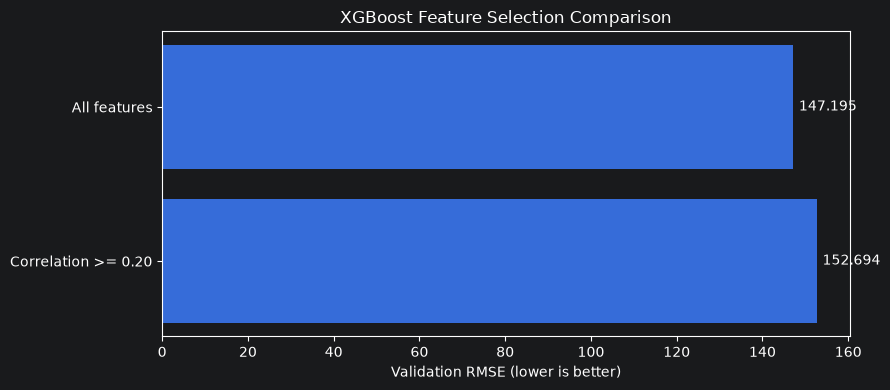


Board features selected at |Spearman| >= 0.20:
avg_tiles_per_play                            +0.4021
seven_tile_play_rate                          +0.3876
points_per_placed_tile                        +0.3856
seven_tile_play_count                         +0.3607
points_per_base_tile_value                    +0.3606
tile_placement_std                            +0.2955
median_tiles_per_play                         +0.2894
max_tiles_per_play                            +0.2824
player_final_tile_share                       +0.2075
player_tiles_placed                           +0.2019

Board reconstruction coverage:


,Split,Rows,Rows with board features,Coverage
0,Training,30574,30511,0.997939
1,Validation,4980,4971,0.998193
2,Holdout,8280,8260,0.997585



Holdout was evaluated without using its ratings for training or selection.
Kaggle test.csv: NOT accessed.


In [40]:

# ============================================================
# XGBOOST COMPARISON
# MODEL A: All gameplay + nonlinear + interaction + board features
# MODEL B: Only features with |Spearman correlation| >= 0.20
#
# Correlation selection: TRAIN ONLY
# Training: TRAIN ONLY
# Evaluation: VALIDATION AND HOLDOUT (one-time check)
# ============================================================
# ============================================================
# 1. CONFIGURATION
# ============================================================

CORRELATION_THRESHOLD = 0.20

BOTS = {
    "BetterBot",
    "HastyBot",
    "STEEBot",
    "BB-8"
}

XGB_PARAMS = {
    "objective": "reg:squarederror",
    "n_estimators": 300,
    "max_depth": 4,
    "learning_rate": 0.1,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 3.0,
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist"
}

assert callable(calculate_board_features)
assert callable(medium_features_for_game)

assert "train_game_ids" in globals()
assert "val_game_ids" in globals()
assert "holdout_game_ids" in globals(), "Run the three-way split cell first."

assert "expanded_data" in globals()
assert "turns" in globals()

holdout_ids = set(holdout_game_ids)
development_ids = set(train_game_ids) | set(val_game_ids)
all_eval_ids = development_ids | holdout_ids

assert set(train_game_ids).isdisjoint(val_game_ids)
assert development_ids.isdisjoint(holdout_ids)
assert all_eval_ids.issubset(set(train_merged["game_id"]))
assert holdout_ids, "The holdout split is empty."


development_turns = turns.loc[
    turns["game_id"].isin(all_eval_ids)
].copy()

high_rows = []
medium_rows = []

high_failed = []
medium_failed = []

for game_id, game_turns in development_turns.groupby(
    "game_id", sort=False
):

    try:
        high_rows.extend(
            calculate_board_features(game_id, game_turns)
        )
    except (ValueError, TypeError, IndexError) as error:
        high_failed.append((game_id, str(error)))

    try:
        medium_rows.extend(
            medium_features_for_game(game_id, game_turns)
        )
    except (ValueError, TypeError, IndexError) as error:
        medium_failed.append((game_id, str(error)))

high_df = pd.DataFrame(high_rows)
medium_df = pd.DataFrame(medium_rows)

if high_df.empty or medium_df.empty:
    raise ValueError(
        "Board reconstruction returned no features."
    )

keys = ["game_id", "nickname"]

assert not high_df.duplicated(keys).any()
assert not medium_df.duplicated(keys).any()


if "player_opponent_efficiency_diff" not in high_df.columns:

    opponent_eff = high_df[
        keys + ["points_per_placed_tile"]
    ].rename(columns={
        "nickname": "opponent_nickname",
        "points_per_placed_tile": "opponent_efficiency"
    })

    paired = high_df.merge(
        opponent_eff,
        on="game_id",
        how="left"
    )

    paired = paired.loc[
        paired["nickname"] != paired["opponent_nickname"]
    ].copy()

    paired["player_opponent_efficiency_diff"] = (
        paired["points_per_placed_tile"]
        - paired["opponent_efficiency"]
    )

    high_df = paired.drop(
        columns=["opponent_nickname", "opponent_efficiency"]
    )

    assert not high_df.duplicated(keys).any()


# Combine board feature tables
# Avoid duplicate feature columns


duplicate_medium_cols = [
    c for c in medium_df.columns
    if c in high_df.columns and c not in keys
]

medium_unique = medium_df.drop(
    columns=duplicate_medium_cols
)

board_all = high_df.merge(
    medium_unique,
    on=keys,
    how="outer",
    validate="one_to_one"
)

board_feature_cols = [
    c for c in board_all.columns
    if c not in keys
]


board_feature_cols = [
    c for c in board_feature_cols
    if not c.startswith("_")
]

board_all = board_all[
    keys + board_feature_cols
].copy()

print("Board features:", len(board_feature_cols))
print("High reconstruction failures:", len(high_failed))
print("Medium reconstruction failures:", len(medium_failed))

data = expanded_data.loc[
    expanded_data["game_id"].isin(all_eval_ids)
    & ~expanded_data["nickname"].isin(BOTS)
].copy()

assert not data.duplicated(keys).any()

original_rows = len(data)

# Remove previously merged board columns, if present
data = data.drop(
    columns=board_feature_cols,
    errors="ignore"
)

data = data.merge(
    board_all,
    on=keys,
    how="left",
    validate="one_to_one"
)

assert len(data) == original_rows

train_mask = data["game_id"].isin(train_game_ids)
val_mask = data["game_id"].isin(val_game_ids)
holdout_mask = data["game_id"].isin(holdout_ids)

assert (train_mask | val_mask | holdout_mask).all()
assert ((train_mask.astype(int) + val_mask.astype(int)
         + holdout_mask.astype(int)) == 1).all()

train_players = set(data.loc[train_mask, "nickname"])
val_players = set(data.loc[val_mask, "nickname"])
holdout_players = set(data.loc[holdout_mask, "nickname"])

assert train_players.isdisjoint(val_players), "TRAIN/VAL PLAYER LEAKAGE"
assert train_players.isdisjoint(holdout_players), "TRAIN/HOLDOUT PLAYER LEAKAGE"
assert val_players.isdisjoint(holdout_players), "VAL/HOLDOUT PLAYER LEAKAGE"

print("\nSplit verification passed.")
print("Training observations:", train_mask.sum())
print("Validation observations:", val_mask.sum())
print("Holdout observations:", holdout_mask.sum())


# RECREATE NONLINEAR FEATURES
# Scaling statistics use TRAIN ONLY


def xgb_train_zscore(series):

    series = pd.to_numeric(
        series, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

    reference = series.loc[train_mask]

    mu = reference.mean()
    sigma = reference.std(ddof=0)

    if not np.isfinite(sigma) or sigma == 0:
        return pd.Series(np.nan, index=series.index)

    return (series - mu) / sigma


score = pd.to_numeric(
    data["score"], errors="coerce"
)

duration = pd.to_numeric(
    data["game_duration_seconds"], errors="coerce"
)

score_per_sec = (
    score / duration.where(duration > 0)
)

data["score_per_sec_scaled_sq"] = (
    xgb_train_zscore(score_per_sec) ** 2
)

if "opponent_score" not in data.columns:
    data["opponent_score"] = (
        data["score"] - data["score_difference"]
    )

data["opp_score_scaled"] = (
    xgb_train_zscore(data["opponent_score"])
)

data["opp_score_scaled_sq"] = (
    data["opp_score_scaled"] ** 2
)

increment = pd.to_numeric(
    data["increment_seconds"], errors="coerce"
)

data["increment_seconds_log"] = np.log1p(
    increment.where(increment >= 0)
)

data["Play_turn_count_scaled_sq"] = (
    xgb_train_zscore(data["count_Play"]) ** 2
)

difficulty_map = {
    "BetterBot": 0,
    "STEEBot": 1,
    "HastyBot": 2
}

if "bot_name" in data.columns:
    bot_names = data["bot_name"]
elif "opponent_nickname" in data.columns:
    bot_names = data["opponent_nickname"]
else:
    raise ValueError("Missing bot identity column")

data["bot_difficulty"] = (
    bot_names.map(difficulty_map)
)

data["bot_difficulty_1"] = (
    data["bot_difficulty"] == 1
).astype(float)

data["win_x_bot2"] = (
    pd.to_numeric(
        data["player_won"], errors="coerce"
    )
    * (data["bot_difficulty"] == 2).astype(float)
)

data.loc[
    data["bot_difficulty"].isna(),
    ["bot_difficulty_1", "win_x_bot2"]
] = np.nan

nonlinear_features = [
    "score_per_sec_scaled_sq",
    "opp_score_scaled",
    "opp_score_scaled_sq",
    "increment_seconds_log",
    "Play_turn_count_scaled_sq",
    "bot_difficulty",
    "bot_difficulty_1",
    "win_x_bot2"
]



if "move_len_median" not in data.columns:

    play_turns = development_turns.loc[
        development_turns["turn_type"] == "Play"
    ].copy()

    move_letters = (
        play_turns["move"]
        .astype("string")
        .str.replace(r"[^A-Z]", "", regex=True)
    )

    play_turns["move_len_median_tmp"] = (
        move_letters.str.len().astype(float)
    )

    play_turns.loc[
        play_turns["move_len_median_tmp"] == 0,
        "move_len_median_tmp"
    ] = np.nan

    medians = (
        play_turns.groupby(keys)["move_len_median_tmp"]
        .median()
        .rename("move_len_median")
        .reset_index()
    )

    data = data.merge(
        medians,
        on=keys,
        how="left",
        validate="one_to_one"
    )

    train_mask = data["game_id"].isin(train_game_ids)
    val_mask = data["game_id"].isin(val_game_ids)
    holdout_mask = data["game_id"].isin(holdout_ids)



interaction_pairs = [
    ("score", "game_duration_seconds"),
    ("avg_points", "num_turns"),
    ("score_difference", "bot_points_mean"),
    ("avg_points", "bot_points_mean"),
    ("move_len_mean", "points_per_letter_mean"),
    ("move_len_mean", "avg_points"),
    ("difficult_word_mean", "points_per_letter_mean"),
    ("high_score_rate", "avg_points"),
    ("rate_Exchange", "avg_points"),
    ("curr_board_pieces_used_mean", "move_len_mean")
]

interaction_features = []

for a, b in interaction_pairs:

    assert a in data.columns, f"Missing interaction input: {a}"
    assert b in data.columns, f"Missing interaction input: {b}"

    name = f"interaction__{a}__x__{b}"

    data[name] = (
        pd.to_numeric(data[a], errors="coerce")
        * pd.to_numeric(data[b], errors="coerce")
    )

    interaction_features.append(name)


#COMPLETE FEATURE POOL


original_features = []

if "all_gameplay_features" in globals():
    original_features += list(all_gameplay_features)

if "all_features" in globals():
    original_features += list(all_features)

original_features = list(dict.fromkeys(original_features))

if not original_features:
    raise ValueError(
        "Run the existing gameplay feature-engineering cells first."
    )

extra_features = (
    nonlinear_features
    + ["move_len_median"]
    + interaction_features
    + board_feature_cols
)

excluded_features = {
    "rating",
    "game_id",
    "nickname",
    "opponent_nickname",
    "bot_rating",
    "opponent_rating",
    "historical_score_mean",
    "historical_score_std",
    "historical_games_count"
}

all_xgb_feature_groups = list(dict.fromkeys(
    original_features + extra_features
))

all_xgb_feature_groups = [
    f for f in all_xgb_feature_groups
    if f in data.columns
    and f not in excluded_features
    and not f.startswith("historical_")
]

# Remove a known duplicate feature
if (
    "player_tile_share" in all_xgb_feature_groups
    and "player_final_tile_share" in all_xgb_feature_groups
):
    all_xgb_feature_groups.remove("player_tile_share")

print("\nTotal feature groups:", len(all_xgb_feature_groups))


#PREPARE TRAIN, VALIDATION AND HOLDOUT


train_df = data.loc[train_mask].copy()
val_df = data.loc[val_mask].copy()
holdout_df = data.loc[holdout_mask].copy()

categorical_cols = [
    f for f in [
        "rating_mode",
        "lexicon",
        "time_control_name",
        "game_end_reason",
        "bot_name"
    ]
    if f in all_xgb_feature_groups
]

numeric_cols = [
    f for f in all_xgb_feature_groups
    if f not in categorical_cols
]

X_train_raw = train_df[all_xgb_feature_groups].copy()
X_val_raw = val_df[all_xgb_feature_groups].copy()
X_holdout_raw = holdout_df[all_xgb_feature_groups].copy()

y_train = pd.to_numeric(
    train_df["rating"], errors="coerce"
)

y_val = pd.to_numeric(
    val_df["rating"], errors="coerce"
)
y_holdout = pd.to_numeric(
    holdout_df["rating"], errors="coerce"
)

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()
assert np.isfinite(y_holdout).all()

for col in numeric_cols:
    X_train_raw[col] = pd.to_numeric(
        X_train_raw[col], errors="coerce"
    )
    X_val_raw[col] = pd.to_numeric(
        X_val_raw[col], errors="coerce"
    )
    X_holdout_raw[col] = pd.to_numeric(
        X_holdout_raw[col], errors="coerce"
    )

X_train_raw = X_train_raw.replace(
    [np.inf, -np.inf], np.nan
)

X_val_raw = X_val_raw.replace(
    [np.inf, -np.inf], np.nan
)
X_holdout_raw = X_holdout_raw.replace(
    [np.inf, -np.inf], np.nan
)

for col in categorical_cols:
    X_train_raw[col] = (
        X_train_raw[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

    X_val_raw[col] = (
        X_val_raw[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )
    X_holdout_raw[col] = (
        X_holdout_raw[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )


# ONE-HOT ENCODE USING TRAIN CATEGORIES ONLY


X_train_encoded = pd.get_dummies(
    X_train_raw,
    columns=categorical_cols,
    dtype=int
)

X_val_encoded = pd.get_dummies(
    X_val_raw,
    columns=categorical_cols,
    dtype=int
).reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

X_holdout_encoded = pd.get_dummies(
    X_holdout_raw,
    columns=categorical_cols,
    dtype=int
).reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

assert list(X_train_encoded.columns) == list(
    X_val_encoded.columns
)
assert list(X_train_encoded.columns) == list(
    X_holdout_encoded.columns
)



correlation_df = X_train_encoded.copy()
correlation_df["rating"] = y_train

all_correlations = (
    correlation_df
    .corr(method="spearman")["rating"]
    .drop("rating")
    .dropna()
)

selected_correlations = (
    all_correlations[
        all_correlations.abs() >= CORRELATION_THRESHOLD
    ]
    .sort_values(
        key=lambda s: s.abs(),
        ascending=False
    )
)

selected_xgb_features = selected_correlations.index.tolist()

if not selected_xgb_features:
    raise ValueError(
        "No features passed the correlation threshold."
    )

print("\nFeature selection")
print("=" * 60)
print("All encoded features:", X_train_encoded.shape[1])
print("Correlation-selected:", len(selected_xgb_features))
print("Threshold:", CORRELATION_THRESHOLD)

display(
    selected_correlations.to_frame(
        "Spearman_with_rating"
    )
)


# TRAIN TWO XGBOOST MODELS


models = {
    "All features": list(X_train_encoded.columns),
    "Correlation >= 0.20": selected_xgb_features
}

xgb_comparison_models = {}
xgb_comparison_results = []

for model_name, features in models.items():

    print(f"\nTraining: {model_name}", flush=True)

    X_tr = X_train_encoded[features]
    X_va = X_val_encoded[features]
    X_ho = X_holdout_encoded[features]

    model = XGBRegressor(**XGB_PARAMS)

    # XGBoost handles missing numerical values natively.
    model.fit(X_tr, y_train)

    train_pred = model.predict(X_tr)
    val_pred = model.predict(X_va)
    holdout_pred = model.predict(X_ho)

    train_mse = mean_squared_error(
        y_train, train_pred
    )

    val_mse = mean_squared_error(
        y_val, val_pred
    )

    train_rmse = np.sqrt(train_mse)
    val_rmse = np.sqrt(val_mse)
    holdout_mse = mean_squared_error(y_holdout, holdout_pred)
    holdout_rmse = np.sqrt(holdout_mse)

    xgb_comparison_models[model_name] = model

    xgb_comparison_results.append({
        "Model": model_name,
        "Features": len(features),
        "Train MSE": train_mse,
        "Train RMSE": train_rmse,
        "Validation MSE": val_mse,
        "Validation RMSE": val_rmse,
        "Validation R2": r2_score(
            y_val, val_pred
        ),
        "Holdout MSE": holdout_mse,
        "Holdout RMSE": holdout_rmse,
        "Holdout R2": r2_score(y_holdout, holdout_pred),
        "RMSE gap": val_rmse - train_rmse
    })

# ============================================================
# 15. COMPARE RESULTS
# ============================================================

xgb_results = pd.DataFrame(
    xgb_comparison_results
).sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("\n" + "=" * 75)
print("XGBOOST — ALL FEATURES VS CORRELATION SELECTED")
print("=" * 75)

display(xgb_results.round(4))

best_xgb_name = xgb_results.iloc[0]["Model"]

print("\nBest model on validation:", best_xgb_name)

# ============================================================
# 16. VISUALIZE VALIDATION RMSE
# ============================================================

plt.figure(figsize=(9, 4))

bars = plt.barh(
    xgb_results["Model"],
    xgb_results["Validation RMSE"]
)

plt.gca().invert_yaxis()

plt.xlabel("Validation RMSE (lower is better)")
plt.title("XGBoost Feature Selection Comparison")

plt.bar_label(bars, fmt="%.3f", padding=4)

plt.tight_layout()
plt.show()

# ============================================================
# 17. REPORT NEW BOARD FEATURES
# ============================================================

selected_board_features = [
    f for f in selected_xgb_features
    if f in board_feature_cols
]

print("\nBoard features selected at |Spearman| >= 0.20:")

for feature in selected_board_features:
    print(
        f"{feature:<45} "
        f"{all_correlations[feature]:+.4f}"
    )

print("\nBoard reconstruction coverage:")

coverage = pd.DataFrame([
    {
        "Split": "Training",
        "Rows": len(train_df),
        "Rows with board features":
            train_df["avg_tiles_per_play"].notna().sum()
    },
    {
        "Split": "Validation",
        "Rows": len(val_df),
        "Rows with board features":
            val_df["avg_tiles_per_play"].notna().sum()
    },
    {
        "Split": "Holdout",
        "Rows": len(holdout_df),
        "Rows with board features":
            holdout_df["avg_tiles_per_play"].notna().sum()
    }
])

coverage["Coverage"] = (
    coverage["Rows with board features"]
    / coverage["Rows"]
)

display(coverage)

print("\nHoldout was evaluated without using its ratings for training or selection.")
print("Kaggle test.csv: NOT accessed.")


Model: All features | Validation n=4,980
RMSE=147.195 | MAE=110.858 | bias=+13.246

FIVE WORST VALIDATION PREDICTIONS + FEATURE IMPACTS


,validation_row,game_id,actual,predicted,error,squared_error,largest_impact_feature,largest_impact_SHAP,largest_wrong_direction_feature,wrong_direction_SHAP,baseline_prediction
0,3101,45846,1473.0,2054.27,581.27,337870.29,interaction__move_len_mean__x__avg_points,66.81,interaction__move_len_mean__x__avg_points,66.81,1825.36
1,3116,46112,1288.0,1845.97,557.97,311333.62,lexicon_CSW21,61.12,lexicon_CSW21,61.12,1825.36
2,3317,49294,1446.0,2003.68,557.68,311008.13,lexicon_CSW21,51.96,lexicon_CSW21,51.96,1825.36
3,250,3505,1352.0,1899.17,547.17,299394.52,interaction__avg_points__x__bot_points_mean,-65.21,lexicon_CSW21,59.46,1825.36
4,2823,41869,1446.0,1990.47,544.47,296446.22,interaction__move_len_mean__x__avg_points,53.06,interaction__move_len_mean__x__avg_points,53.06,1825.36



Game 45846 | actual=1473.0, predicted=2054.3, error=+581.3


,feature_value,SHAP_rating_points
interaction__move_len_mean__x__avg_points,177.54,66.809998
lexicon_CSW21,1.00,63.790001
bot_difficulty,2.00,31.299999
rating_mode_CASUAL,0.00,15.980000
initial_time_seconds,1080.00,13.870000



Game 46112 | actual=1288.0, predicted=1846.0, error=+558.0


,feature_value,SHAP_rating_points
lexicon_CSW21,1.0,61.119999
interaction__move_len_mean__x__avg_points,63.4,-43.730000
bot_difficulty,0.0,-31.700001
initial_time_seconds,780.0,-30.590000
rating_mode_CASUAL,0.0,14.370000


... (10 outputs left out)


ERROR BY PLAYER SCORE QUINTILE


,n,bias,MAE,RMSE
score_bin,,,,
"(-0.001, 317.0]",999,8.80,126.77,163.33
"(434.0, 700.0]",991,19.63,109.40,147.98
"(395.0, 434.0]",994,20.94,108.76,146.80
"(361.0, 395.0]",984,13.70,106.14,139.86
"(317.0, 361.0]",1012,3.39,103.23,136.57



ERROR BY BOARD-FEATURE AVAILABILITY


,n,bias,MAE,RMSE
board_features_present,,,,
False,9,142.66,148.07,221.64
True,4971,13.01,110.79,147.03


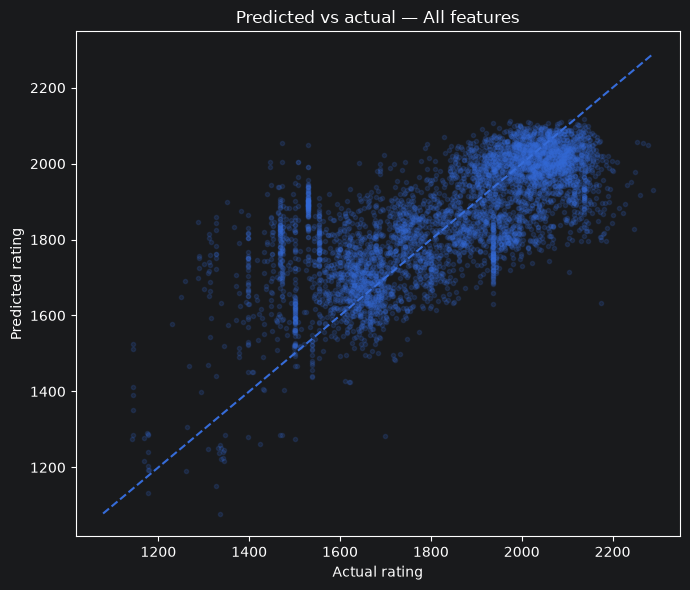

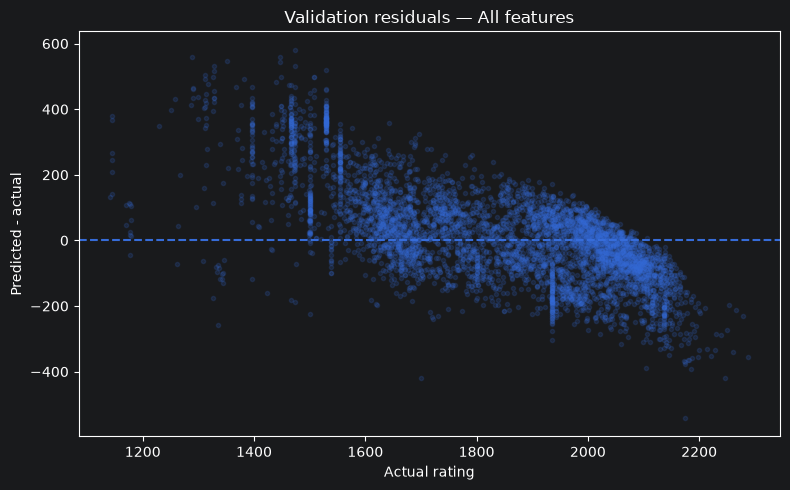

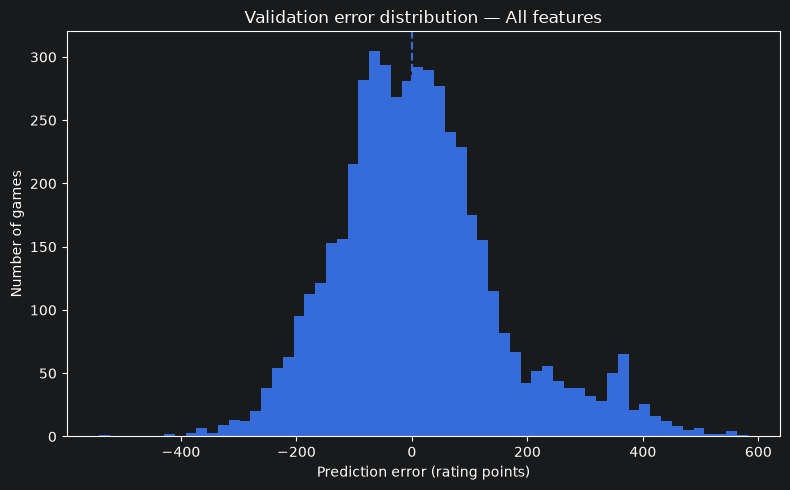


Only validation predictions analyzed. No retraining or Kaggle test labels.
SHAP shows impact on model output, not proof that a feature caused the mistake.


In [41]:
# VALIDATION ERROR ANALYSIS — run after XGBOOST COMPARISON
# Requires the trained models and validation features created above.
from xgboost import DMatrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


MODEL_NAME = "All features"  # or "Correlation >= 0.20"
TOP_N = 5

required = ["xgb_comparison_models", "models", "X_val_encoded", "val_df", "y_val"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Run the XGBoost comparison cell first. Missing: {missing}")
if MODEL_NAME not in xgb_comparison_models or MODEL_NAME not in models:
    raise ValueError(f"Unknown model: {MODEL_NAME}")

model = xgb_comparison_models[MODEL_NAME]
feature_names = list(models[MODEL_NAME])
X = X_val_encoded[feature_names].reset_index(drop=True).copy()
y = pd.to_numeric(pd.Series(np.asarray(y_val)), errors="coerce").reset_index(drop=True)
info = val_df.reset_index(drop=True)
assert len(X) == len(y) == len(info), "Validation rows are misaligned"
assert np.isfinite(y).all(), "Validation target contains missing values"

pred = model.predict(X)
errors = pd.DataFrame({
    "game_id": info["game_id"].to_numpy(),
    "nickname": info["nickname"].to_numpy(),
    "actual": y.to_numpy(),
    "predicted": pred,
})
errors["error"] = errors["predicted"] - errors["actual"]
errors["abs_error"] = errors["error"].abs()
errors["squared_error"] = errors["error"] ** 2

for name in ["score", "bot_name", "player_won", "num_turns",
             "avg_points", "game_duration_seconds", "avg_tiles_per_play",
             "seven_tile_play_rate", "points_per_placed_tile"]:
    if name in info.columns:
        errors[name] = info[name].to_numpy()

rmse = np.sqrt(errors["squared_error"].mean())
mae = errors["abs_error"].mean()
print(f"Model: {MODEL_NAME} | Validation n={len(errors):,}")
print(f"RMSE={rmse:.3f} | MAE={mae:.3f} | bias={errors['error'].mean():+.3f}")

# ------------------------------------------------------------
# Five biggest SQUARED errors = five biggest absolute errors.
# ------------------------------------------------------------
worst_positions = errors["squared_error"].nlargest(TOP_N).index.to_numpy()
worst = errors.loc[worst_positions].copy()
worst.insert(0, "validation_row", worst_positions)

# XGBoost TreeSHAP contributions: model prediction (in rating units)
# equals base_value + sum(feature_contributions).
# This explains model prediction, not a causal reason for error.
booster = model.get_booster()
X_worst = X.iloc[worst_positions]
contrib = booster.predict(DMatrix(X_worst), pred_contribs=True)
if contrib.shape != (len(worst), len(feature_names) + 1):
    raise RuntimeError("Unexpected XGBoost feature-contribution shape")
feature_contrib = contrib[:, :-1]
baselines = contrib[:, -1]

explain_rows = []
for j, pos in enumerate(worst_positions):
    signed_error = float(errors.loc[pos, "error"])
    row_shap = feature_contrib[j]

    # Largest overall effect on the predicted rating (absolute SHAP).
    max_idx = int(np.argmax(np.abs(row_shap)))

    # Largest feature contribution pushing prediction TOWARD the error:
    # positive SHAP for overprediction; negative for underprediction.
    same_direction = row_shap * np.sign(signed_error)
    wrong_idx = int(np.argmax(same_direction))
    if same_direction[wrong_idx] <= 0:
        wrong_feature, wrong_contribution = "(none)", 0.0
    else:
        wrong_feature = feature_names[wrong_idx]
        wrong_contribution = float(row_shap[wrong_idx])

    explain_rows.append({
        "validation_row": int(pos),
        "game_id": errors.loc[pos, "game_id"],
        "actual": float(errors.loc[pos, "actual"]),
        "predicted": float(errors.loc[pos, "predicted"]),
        "error": signed_error,
        "squared_error": float(errors.loc[pos, "squared_error"]),
        "largest_impact_feature": feature_names[max_idx],
        "largest_impact_SHAP": float(row_shap[max_idx]),
        "largest_wrong_direction_feature": wrong_feature,
        "wrong_direction_SHAP": wrong_contribution,
        "baseline_prediction": float(baselines[j]),
    })

explanations = pd.DataFrame(explain_rows)
print("\nFIVE WORST VALIDATION PREDICTIONS + FEATURE IMPACTS")
display(explanations.round(2))

# Top 5 contributions for EACH badly predicted case.
for j, pos in enumerate(worst_positions):
    shap_s = pd.Series(feature_contrib[j], index=feature_names)
    largest = shap_s.reindex(shap_s.abs().nlargest(5).index)
    print(f"\nGame {errors.loc[pos, 'game_id']} | "
          f"actual={errors.loc[pos, 'actual']:.1f}, "
          f"predicted={errors.loc[pos, 'predicted']:.1f}, "
          f"error={errors.loc[pos, 'error']:+.1f}")
    display(pd.DataFrame({
        "feature_value": [X.iloc[pos][name] for name in largest.index],
        "SHAP_rating_points": largest.to_numpy(),
    }, index=largest.index).round(2))

# ------------------------------------------------------------
# Error breakdowns (validation only).
# ------------------------------------------------------------
def grouped_errors(frame, column):
    g = frame.groupby(column, dropna=False, observed=True)
    out = g.agg(n=("error", "size"),
                bias=("error", "mean"),
                MAE=("abs_error", "mean"),
                MSE=("squared_error", "mean"))
    out["RMSE"] = np.sqrt(out.pop("MSE"))
    return out.sort_values("RMSE", ascending=False).round(2)

errors["rating_bin"] = pd.qcut(errors["actual"], 5, duplicates="drop")
print("\nERROR BY ACTUAL RATING QUINTILE")
display(grouped_errors(errors, "rating_bin"))

if "bot_name" in errors:
    print("\nERROR BY BOT")
    display(grouped_errors(errors, "bot_name"))

if "score" in errors:
    errors["score_bin"] = pd.qcut(errors["score"], 5, duplicates="drop")
    print("\nERROR BY PLAYER SCORE QUINTILE")
    display(grouped_errors(errors, "score_bin"))

if "avg_tiles_per_play" in errors:
    errors["board_features_present"] = errors["avg_tiles_per_play"].notna()
    print("\nERROR BY BOARD-FEATURE AVAILABILITY")
    display(grouped_errors(errors, "board_features_present"))

# ------------------------------------------------------------
# Diagnostic visualizations.
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(errors["actual"], errors["predicted"], alpha=0.17, s=9)
lo = min(errors["actual"].min(), errors["predicted"].min())
hi = max(errors["actual"].max(), errors["predicted"].max())
ax.plot([lo, hi], [lo, hi], "--")
ax.set(xlabel="Actual rating", ylabel="Predicted rating",
       title=f"Predicted vs actual — {MODEL_NAME}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(errors["actual"], errors["error"], alpha=0.17, s=9)
ax.axhline(0, linestyle="--")
ax.set(xlabel="Actual rating", ylabel="Predicted - actual",
       title=f"Validation residuals — {MODEL_NAME}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(errors["error"], bins=60)
ax.axvline(0, linestyle="--")
ax.set(xlabel="Prediction error (rating points)", ylabel="Number of games",
       title=f"Validation error distribution — {MODEL_NAME}")
plt.tight_layout()
plt.show()

print("\nOnly validation predictions analyzed. No retraining or Kaggle test labels.")
print("SHAP shows impact on model output, not proof that a feature caused the mistake.")


In [42]:
# ============================================================
# SHARED SUBMISSION FEATURE BUILDER — TEST GAMEPLAY ONLY
# Reconstructs the 56 base features + move_len_median for test.
# Never reads test.rating or uses it to fit a model.
# ============================================================

from pathlib import Path

SUBMISSION_BOTS = {"BetterBot", "HastyBot", "STEEBot", "BB-8"}
DATA_DIR = Path("scrabble-player-rating")


def make_submission_base(test_rows, games_df, turns_df):
    required = {"game_id", "nickname", "score"}
    if not required.issubset(test_rows.columns):
        raise ValueError(f"test.csv missing: {sorted(required - set(test_rows.columns))}")

    # Drop test ratings even if the file contains a rating column.
    participants = test_rows.drop(columns=["rating"], errors="ignore").copy()
    if participants.duplicated(["game_id", "nickname"]).any():
        raise ValueError("Duplicate test (game_id, nickname) rows")

    # The notebook's opponent and bot-score features require both participants.
    counts = participants.groupby("game_id")["nickname"].nunique()
    if not counts.eq(2).all():
        raise ValueError(
            "Expected both players in each test game, as in the training notebook. "
            "Cannot reconstruct opponent_score or bot_score otherwise."
        )

    participants["score"] = pd.to_numeric(participants["score"], errors="coerce")
    assert participants["score"].notna().all()

    # Same per-turn aggregation as the original feature-engineering cells.
    turns_subset = turns_df.loc[
        turns_df["game_id"].isin(participants["game_id"])
    ].copy()
    turn_features = (
        turns_subset.groupby(["game_id", "nickname"])
        .agg(num_turns=("points", "count"), avg_points=("points", "mean"),
             max_points=("points", "max"), total_points=("points", "sum"),
             std_points=("points", "std"))
        .reset_index()
    )

    out = (participants
        .merge(games_df, on="game_id", how="left", validate="many_to_one")
        .merge(turn_features, on=["game_id", "nickname"], how="left", validate="one_to_one"))

    out["played_first"] = out["nickname"].eq(out["first"]).astype(int)
    out["player_won"] = (
        ((out["played_first"] == 1) & (out["winner"] == 0)) |
        ((out["played_first"] == 0) & (out["winner"] == 1))
    ).astype(int)

    # All opponent information comes from the TWO TEST PLAYER ROWS,
    # never from labeled training data or ratings.
    opponents = participants[["game_id", "nickname", "score"]].rename(
        columns={"nickname": "opponent_nickname", "score": "opponent_score"})
    out = out.merge(opponents, on="game_id", how="left", validate="many_to_many")
    out = out.loc[out["nickname"] != out["opponent_nickname"]].copy()
    out["score_difference"] = out["score"] - out["opponent_score"]

    move_types = ["Challenge", "End", "Exchange", "Pass", "Play",
                  "Six-Zero Rule", "Timeout", "Unknown"]
    count_cols = [f"count_{name}" for name in move_types]
    counts = pd.crosstab(
        index=[turns_subset["game_id"], turns_subset["nickname"]],
        columns=turns_subset["turn_type"].fillna("Unknown")
    ).add_prefix("count_").reset_index()
    for col in count_cols:
        if col not in counts.columns:
            counts[col] = 0
    out = out.merge(counts[["game_id", "nickname"] + count_cols],
                    on=["game_id", "nickname"], how="left", validate="one_to_one")
    for col in count_cols:
        out[col] = out[col].fillna(0)
        out[col.replace("count_", "rate_", 1)] = (
            out[col] / out["num_turns"].replace(0, np.nan))

    high = turns_subset[["game_id", "nickname", "turn_type", "points"]].copy()
    high["is_high_score"] = (
        high["turn_type"].eq("Play") &
        pd.to_numeric(high["points"], errors="coerce").ge(50)
    ).astype(int)
    high = high.groupby(["game_id", "nickname"]).agg(
        high_score_count=("is_high_score", "sum"),
        high_score_rate=("is_high_score", "mean")
    ).reset_index()
    out = out.merge(high, on=["game_id", "nickname"], how="left", validate="one_to_one")

    # Same move, rack and advanced Play features as the LightGBM notebook.
    t = turns_subset.copy()
    t["points_numeric"] = pd.to_numeric(t["points"], errors="coerce")
    t["move_raw"] = t["move"].astype("string")
    t["move_letters"] = t["move_raw"].str.replace(r"[^A-Z]", "", regex=True)
    t["move_length_all"] = t["move_letters"].str.len().astype(float)
    t.loc[t["move"].isna(), "move_length_all"] = np.nan
    t["rack_letters"] = t["rack"].astype("string").str.replace(r"[^A-Z]", "", regex=True)
    t["rack_length"] = t["rack_letters"].str.len().astype(float)
    t["rack_vowels"] = t["rack_letters"].str.count(r"[AEIOU]").astype(float)
    t["rack_vowel_ratio"] = t["rack_vowels"] / t["rack_length"].replace(0, np.nan)

    words = t.groupby(["game_id", "nickname"]).agg(
        move_length_mean=("move_length_all", "mean"),
        move_length_std=("move_length_all", "std"),
        move_length_max=("move_length_all", "max"),
        rack_vowel_ratio_mean=("rack_vowel_ratio", "mean"),
        rack_vowel_ratio_std=("rack_vowel_ratio", "std")
    ).reset_index()
    out = out.merge(words, on=["game_id", "nickname"], how="left", validate="one_to_one")

    t["move_len"] = t["move_letters"].str.len().astype(float)
    t.loc[(t["turn_type"] != "Play") | (t["move_len"] == 0), "move_len"] = np.nan
    t["is_difficult_word"] = (t["move_len"] >= 7).astype(float)
    t.loc[t["move_len"].isna(), "is_difficult_word"] = np.nan
    t["difficult_letters"] = t["move_letters"].str.count(r"[JQXZ]").astype(float)
    t.loc[t["move_len"].isna(), "difficult_letters"] = np.nan
    t["points_per_letter"] = t["points_numeric"] / t["move_len"]
    t["curr_board_pieces_used"] = t["move_raw"].str.count(r"\.").astype(float)
    t.loc[t["move_raw"].isna(), "curr_board_pieces_used"] = np.nan

    play = t.loc[t["turn_type"] == "Play"]
    advanced = play.groupby(["game_id", "nickname"]).agg(
        move_len_mean=("move_len", "mean"),
        move_len_median=("move_len", "median"),
        move_len_max=("move_len", "max"),
        difficult_word_mean=("is_difficult_word", "mean"),
        difficult_word_sum=("is_difficult_word", "sum"),
        difficult_letters_mean=("difficult_letters", "mean"),
        difficult_letters_sum=("difficult_letters", "sum"),
        points_per_letter_mean=("points_per_letter", "mean"),
        curr_board_pieces_used_mean=("curr_board_pieces_used", "mean")
    ).reset_index()
    out = out.merge(advanced, on=["game_id", "nickname"],
                    how="left", validate="one_to_one")

    # Bot statistics are calculated from test-game scores and turns.
    stats = t.groupby(["game_id", "nickname"]).agg(
        points_mean=("points_numeric", "mean"),
        move_len_mean=("move_len", "mean"),
        points_per_letter_mean=("points_per_letter", "mean")
    ).reset_index()
    bot_rows = participants.loc[
        participants["nickname"].isin(SUBMISSION_BOTS),
        ["game_id", "nickname", "score"]
    ].copy()
    if bot_rows.duplicated("game_id").any():
        raise ValueError("Multiple bot rows in a test game")
    bot_stats = bot_rows.merge(stats, on=["game_id", "nickname"], how="left",
                               validate="one_to_one").rename(columns={
        "nickname": "bot_name", "score": "bot_score",
        "points_mean": "bot_points_mean",
        "move_len_mean": "bot_move_len_mean",
        "points_per_letter_mean": "bot_points_per_letter_mean"
    })
    human_stats = stats.rename(columns={
        "points_mean": "human_points_mean",
        "move_len_mean": "human_move_len_mean",
        "points_per_letter_mean": "human_points_per_letter_mean"
    })
    human = out.loc[~out["nickname"].isin(SUBMISSION_BOTS)].copy()
    human = human.merge(
        human_stats[["game_id", "nickname", "human_points_mean",
                     "human_move_len_mean", "human_points_per_letter_mean"]],
        on=["game_id", "nickname"], how="left", validate="one_to_one")
    human = human.merge(bot_stats, on="game_id", how="left", validate="many_to_one")
    human["avg_points_diff"] = human["human_points_mean"] - human["bot_points_mean"]
    human["avg_move_len_diff"] = human["human_move_len_mean"] - human["bot_move_len_mean"]
    human["avg_points_per_letter_diff"] = (
        human["human_points_per_letter_mean"] - human["bot_points_per_letter_mean"])

    if human["bot_name"].isna().any():
        raise ValueError("Missing test-game bot opponent; cannot construct bot context")
    if human["game_id"].duplicated().any():
        raise ValueError("Expected exactly one human target per test game")
    return human


def save_scrabble_submission(test_features, predictions, output_filename):
    from pathlib import Path
    import numpy as np
    import pandas as pd

    # One prediction per test game
    submission = pd.DataFrame({
        "game_id": test_features["game_id"].to_numpy(),
        "rating": np.asarray(predictions, dtype=float)
    })

    # Validate submission
    if submission["game_id"].duplicated().any():
        raise ValueError("Duplicate game_id values in submission")

    if not np.isfinite(submission["rating"]).all():
        raise ValueError("Invalid prediction values (NaN or infinity)")

    # Save beside the notebook's current working directory
    output_path = Path.cwd() / output_filename
    submission.to_csv(output_path, index=False)

    print(f"Saved: {output_path.resolve()}")
    print(f"Rows: {len(submission):,}")
    print(submission.head())

    return submission



## Feedback experiment — Holdout comparison and one independent Kaggle submission

Run the existing XGBoost comparison and submission helper cells first. The original two-model Kaggle submission cell has been removed.


In [43]:
# ============================================================
# FEEDBACK EXPERIMENT — TRAIN / HOLDOUT (VALIDATION FALLBACK)
# Compare original |Spearman| >= 0.20 XGBoost with:
#   * High-score rate normalized by Play turns only
#   * Move-quality interactions with bot and time control
# No player history, evaluation-set feature selection or Kaggle labels.
# ============================================================
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

required = [
    'train_df', 'X_train_encoded', 'y_train',
    'selected_xgb_features', 'XGB_PARAMS',
    'xgb_comparison_models', 'train_game_ids', 'val_game_ids'
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f'Run the earlier XGBoost comparison cell first: {missing}')

# Evaluate on the untouched HOLDOUT when available; otherwise VALIDATION.
# The model and feature selection remain fitted on TRAIN only.
has_holdout = (
    all(name in globals() for name in
        ['holdout_df', 'X_holdout_encoded', 'y_holdout', 'holdout_game_ids'])
    and len(holdout_df) > 0 and len(y_holdout) > 0
)
if has_holdout:
    eval_name = 'Holdout'
    eval_df = holdout_df
    X_eval_encoded = X_holdout_encoded
    y_eval = y_holdout
    eval_game_ids = holdout_game_ids
else:
    needed_val = ['val_df', 'X_val_encoded', 'y_val']
    missing_val = [name for name in needed_val if name not in globals()]
    if missing_val:
        raise RuntimeError(f'Neither holdout nor validation is ready: {missing_val}')
    eval_name = 'Validation'
    eval_df = val_df
    X_eval_encoded = X_val_encoded
    y_eval = y_val
    eval_game_ids = val_game_ids

assert set(train_game_ids).isdisjoint(set(eval_game_ids))
assert set(train_df['game_id']).isdisjoint(set(eval_df['game_id']))
assert set(train_df['nickname']).isdisjoint(set(eval_df['nickname']))
assert len(eval_df) == len(X_eval_encoded) == len(y_eval)
print('Evaluation split:', eval_name, '| rows:', len(eval_df))

# The category names are taken exclusively from the original TRAIN encoding.
feedback_context_dummies = [
    col for col in X_train_encoded.columns
    if col.startswith('bot_name_') or col.startswith('time_control_name_')
]
if not feedback_context_dummies:
    raise ValueError('No bot/time-control dummy columns in training features')

# Use one identical feature engineering function for TRAIN, VALIDATION,
# all labeled data, and Kaggle TEST in the next cell.
def make_feedback_features(raw_frame, encoded_frame):
    if len(raw_frame) != len(encoded_frame) or not raw_frame.index.equals(encoded_frame.index):
        raise ValueError('Raw and encoded rows are not aligned')

    count_play = pd.to_numeric(raw_frame['count_Play'], errors='coerce')
    high_count = pd.to_numeric(raw_frame['high_score_count'], errors='coerce')
    avg_points = pd.to_numeric(raw_frame['avg_points'], errors='coerce')
    move_length = pd.to_numeric(raw_frame['move_len_mean'], errors='coerce')

    result = pd.DataFrame(index=encoded_frame.index)
    result['feedback__high_score_play_rate'] = (
        high_count.to_numpy() / count_play.replace(0, np.nan).to_numpy()
    )

    # These interactions let the model learn different associations within
    # bot and time-control groups, as suggested by subgroup correlations.
    for dummy in feedback_context_dummies:
        group_flag = pd.to_numeric(
            encoded_frame[dummy], errors='coerce'
        ).fillna(0).to_numpy()
        result[f'feedback__avg_points_x_{dummy}'] = (
            avg_points.to_numpy() * group_flag
        )
        result[f'feedback__move_len_x_{dummy}'] = (
            move_length.to_numpy() * group_flag
        )
        # An inactive category contributes 0 even if the source rate is NaN.
        result[f'feedback__high_score_play_rate_x_{dummy}'] = np.where(
            group_flag == 0, 0.0,
            result['feedback__high_score_play_rate'].to_numpy() * group_flag
        )

    return result.replace([np.inf, -np.inf], np.nan)

baseline_features = list(selected_xgb_features)
assert all(col in X_train_encoded for col in baseline_features)

feedback_train = make_feedback_features(train_df, X_train_encoded)
feedback_eval = make_feedback_features(eval_df, X_eval_encoded)
feedback_new_columns = list(feedback_train.columns)

X_feedback_train = pd.concat([X_train_encoded[baseline_features], feedback_train], axis=1)
X_feedback_eval = pd.concat([X_eval_encoded[baseline_features], feedback_eval], axis=1)
assert list(X_feedback_train.columns) == list(X_feedback_eval.columns)
assert X_feedback_train.columns.is_unique

feedback_model = XGBRegressor(**XGB_PARAMS)
feedback_model.fit(X_feedback_train, y_train)

baseline_model = xgb_comparison_models['Correlation >= 0.20']
baseline_eval_pred = baseline_model.predict(X_eval_encoded[baseline_features])
feedback_eval_pred = feedback_model.predict(X_feedback_eval)

def feedback_metrics(name, predictions):
    return {
        'Model': name,
        'Features': len(baseline_features) if name == 'Correlation >= 0.20' else X_feedback_eval.shape[1],
        'RMSE': np.sqrt(mean_squared_error(y_eval, predictions)),
        'MAE': mean_absolute_error(y_eval, predictions),
        'R2': r2_score(y_eval, predictions),
        'Bias (pred - actual)': float(np.mean(np.asarray(predictions) - np.asarray(y_eval)))
    }

feedback_comparison = pd.DataFrame([
    feedback_metrics('Correlation >= 0.20', baseline_eval_pred),
    feedback_metrics('Correlation + new EDA features', feedback_eval_pred)
])
feedback_delta = (feedback_comparison.iloc[1]['RMSE']
                  - feedback_comparison.iloc[0]['RMSE'])

print('Both models trained on TRAIN only; correlation selection used TRAIN only.')
print('Additional feedback columns:', len(feedback_new_columns))
print(f'{eval_name} RMSE difference (enhanced - baseline):', round(feedback_delta, 4))
print('Negative difference means the enhanced model is better.')
display(feedback_comparison.round(4))

# Inspect whether the change helps within each bot and time-control group.
feedback_errors = eval_df[['game_id', 'nickname', 'bot_name', 'time_control_name']].copy()
feedback_errors['actual'] = np.asarray(y_eval)
feedback_errors['baseline_sq_error'] = (baseline_eval_pred - feedback_errors['actual'].to_numpy()) ** 2
feedback_errors['enhanced_sq_error'] = (feedback_eval_pred - feedback_errors['actual'].to_numpy()) ** 2
for group_col in ['bot_name', 'time_control_name']:
    by_group = feedback_errors.groupby(group_col, dropna=False).agg(
        n=('actual', 'size'),
        baseline_mse=('baseline_sq_error', 'mean'),
        enhanced_mse=('enhanced_sq_error', 'mean')
    )
    by_group['baseline_RMSE'] = np.sqrt(by_group.pop('baseline_mse'))
    by_group['enhanced_RMSE'] = np.sqrt(by_group.pop('enhanced_mse'))
    by_group['delta_RMSE'] = by_group['enhanced_RMSE'] - by_group['baseline_RMSE']
    print(f'\n{eval_name} error by {group_col}:')
    display(by_group.round(3))


Evaluation split: Holdout | rows: 8280
Both models trained on TRAIN only; correlation selection used TRAIN only.
Additional feedback columns: 22
Holdout RMSE difference (enhanced - baseline): 0.5074
Negative difference means the enhanced model is better.


,Model,Features,RMSE,MAE,R2,Bias (pred - actual)
0,Correlation >= 0.20,45,155.6111,120.2828,0.5070,-10.2031
1,Correlation + new EDA features,67,156.1185,120.9808,0.5038,-10.1154



Holdout error by bot_name:


,n,baseline_RMSE,enhanced_RMSE,delta_RMSE
bot_name,,,,
BetterBot,3644,185.394,185.361,-0.033
HastyBot,1844,143.926,145.752,1.825
STEEBot,2792,115.201,115.788,0.587



Holdout error by time_control_name:


,n,baseline_RMSE,enhanced_RMSE,delta_RMSE
time_control_name,,,,
blitz,328,154.050,154.304,0.254
rapid,776,191.196,185.745,-5.452
regular,7176,151.335,152.655,1.320


In [44]:
required_names = [
    'make_submission_base', 'save_scrabble_submission',
    'calculate_board_features', 'medium_features_for_game',
    'all_xgb_feature_groups', 'XGB_PARAMS', 'data', 'train_game_ids',
    'selected_xgb_features', 'turns', 'test', 'games'
]
missing_names = [n for n in required_names if n not in globals()]
if missing_names:
    raise RuntimeError(f'Run feature-building / XGBoost cells first: {missing_names}')

import numpy as np
import pandas as pd
from xgboost import XGBRegressor

board_test_base = make_submission_base(test, games, turns)
test_ids = set(board_test_base['game_id'])
test_turns = turns.loc[turns['game_id'].isin(test_ids)].copy()

high_rows_test, medium_rows_test = [], []
failed_high_test, failed_medium_test = [], []
for game_id, one_game in test_turns.groupby('game_id', sort=False):
    try:
        high_rows_test.extend(calculate_board_features(game_id, one_game))
    except (ValueError, TypeError, IndexError) as error:
        failed_high_test.append((game_id, str(error)))
    try:
        medium_rows_test.extend(medium_features_for_game(game_id, one_game))
    except (ValueError, TypeError, IndexError) as error:
        failed_medium_test.append((game_id, str(error)))

k = ['game_id', 'nickname']
high_test = pd.DataFrame(high_rows_test)
medium_test = pd.DataFrame(medium_rows_test)
if high_test.empty or medium_test.empty:
    raise ValueError('Board reconstruction failed for all Kaggle test games')
assert not high_test.duplicated(k).any()
assert not medium_test.duplicated(k).any()

# Same opponent efficiency construction as Cell 38.
if 'player_opponent_efficiency_diff' not in high_test.columns:
    opponent_eff = high_test[k + ['points_per_placed_tile']].rename(columns={
        'nickname': 'opponent_nickname',
        'points_per_placed_tile': 'opponent_efficiency'
    })
    tmp = high_test.merge(opponent_eff, on='game_id', how='left')
    tmp = tmp.loc[tmp['nickname'] != tmp['opponent_nickname']].copy()
    tmp['player_opponent_efficiency_diff'] = (
        tmp['points_per_placed_tile'] - tmp['opponent_efficiency'])
    high_test = tmp.drop(columns=['opponent_nickname', 'opponent_efficiency'])

medium_test = medium_test.drop(columns=[
    c for c in medium_test.columns if c in high_test.columns and c not in k
])
board_test_features = high_test.merge(medium_test, on=k, how='outer',
                                      validate='one_to_one')
board_test_features = board_test_features.drop(
    columns=[c for c in board_test_features.columns if c.startswith('_')]
)
board_test_base = board_test_base.merge(board_test_features, on=k, how='left',
                                        validate='one_to_one')

# Reconstruct the exact nonlinear and interaction features of Cell 38.
# Refer to the original training subset for normalization statistics.
labeled_all = data.loc[~data['nickname'].isin(SUBMISSION_BOTS)].copy()
labeled_reference = labeled_all.loc[
    labeled_all['game_id'].isin(train_game_ids)
].copy()
assert len(labeled_reference) > 0

numeric = lambda col: pd.to_numeric(col, errors='coerce')

def zscore_against_train(test_values, train_values):
    train_values = numeric(train_values).replace([np.inf, -np.inf], np.nan)
    test_values = numeric(test_values).replace([np.inf, -np.inf], np.nan)
    sd = train_values.std(ddof=0)
    if not np.isfinite(sd) or sd == 0:
        return pd.Series(np.nan, index=test_values.index)
    return (test_values - train_values.mean()) / sd

ref_speed = (
    numeric(labeled_reference['score']) /
    numeric(labeled_reference['game_duration_seconds']).where(
        numeric(labeled_reference['game_duration_seconds']) > 0)
)
test_speed = (
    numeric(board_test_base['score']) /
    numeric(board_test_base['game_duration_seconds']).where(
        numeric(board_test_base['game_duration_seconds']) > 0)
)
board_test_base['score_per_sec_scaled_sq'] = zscore_against_train(
    test_speed, ref_speed) ** 2
board_test_base['opp_score_scaled'] = zscore_against_train(
    board_test_base['opponent_score'], labeled_reference['opponent_score'])
board_test_base['opp_score_scaled_sq'] = board_test_base['opp_score_scaled'] ** 2
increment = numeric(board_test_base['increment_seconds'])
board_test_base['increment_seconds_log'] = np.log1p(increment.where(increment >= 0))
board_test_base['Play_turn_count_scaled_sq'] = zscore_against_train(
    board_test_base['count_Play'], labeled_reference['count_Play']) ** 2
order = {'BetterBot': 0, 'STEEBot': 1, 'HastyBot': 2}
board_test_base['bot_difficulty'] = board_test_base['bot_name'].map(order)
board_test_base['bot_difficulty_1'] = board_test_base['bot_difficulty'].eq(1).astype(float)
board_test_base['win_x_bot2'] = (
    numeric(board_test_base['player_won']) *
    board_test_base['bot_difficulty'].eq(2).astype(float))
board_test_base.loc[board_test_base['bot_difficulty'].isna(),
                    ['bot_difficulty_1', 'win_x_bot2']] = np.nan

for a, b in interaction_pairs:
    board_test_base[f'interaction__{a}__x__{b}'] = (
        numeric(board_test_base[a]) * numeric(board_test_base[b]))

missing_labeled = sorted(set(all_xgb_feature_groups) - set(labeled_all.columns))
missing_test = sorted(set(all_xgb_feature_groups) - set(board_test_base.columns))
if missing_labeled or missing_test:
    raise ValueError(f'Missing labeled features: {missing_labeled}; test: {missing_test}')

cat_cols = [c for c in ['rating_mode', 'lexicon', 'time_control_name',
                        'game_end_reason', 'bot_name'] if c in all_xgb_feature_groups]
num_cols = [c for c in all_xgb_feature_groups if c not in cat_cols]
X_all_raw = labeled_all[all_xgb_feature_groups].copy()
X_kaggle_raw = board_test_base[all_xgb_feature_groups].copy()
for col in num_cols:
    X_all_raw[col] = numeric(X_all_raw[col])
    X_kaggle_raw[col] = numeric(X_kaggle_raw[col])
X_all_raw.replace([np.inf, -np.inf], np.nan, inplace=True)
X_kaggle_raw.replace([np.inf, -np.inf], np.nan, inplace=True)
for col in cat_cols:
    X_all_raw[col] = X_all_raw[col].astype('string').fillna('Missing').astype(str)
    X_kaggle_raw[col] = X_kaggle_raw[col].astype('string').fillna('Missing').astype(str)
X_all_encoded = pd.get_dummies(X_all_raw, columns=cat_cols, dtype=int)
X_kaggle_encoded = pd.get_dummies(X_kaggle_raw, columns=cat_cols, dtype=int).reindex(
    columns=X_all_encoded.columns, fill_value=0)
y_all = numeric(labeled_all['rating'])
assert np.isfinite(y_all).all()

# Train both models on all labeled human games; model selection was done
# on VALIDATION earlier, not on Kaggle hidden targets.
board_submission_results = {}
for model_name, feature_names, filename in [
    ('All features', list(X_all_encoded.columns), 'submission_manyfeat_board_all.csv'),
    ('Correlation >= 0.20', selected_xgb_features, 'submission_manyfeat_board_corr20.csv')
]:
    # Some dummy columns from the old TRAIN may not exist in all labeled
    # rows only if the upstream split/model was changed since Cell 38.
    assert set(feature_names).issubset(X_all_encoded.columns), (
        f'Feature mismatch for {model_name}; rerun Cell 38 with current splits')
    board_model = XGBRegressor(**XGB_PARAMS)
    board_model.fit(X_all_encoded[feature_names], y_all)
    preds = board_model.predict(X_kaggle_encoded[feature_names])
    board_submission_results[model_name] = save_scrabble_submission(
        board_test_base, preds, filename)
    print(f'{model_name}: {len(feature_names)} encoded features')

print('Kaggle test board reconstruction failures:',
      len(failed_high_test), 'high;', len(failed_medium_test), 'medium')
print('Test rows with board feature:',
      board_test_base['avg_tiles_per_play'].notna().sum(), '/', len(board_test_base))
print('No Kaggle test rating labels accessed.')


Saved: C:\Users\barak\PycharmProjects\WelcomeScreen\submission_manyfeat_board_all.csv
Rows: 22,363
   game_id       rating
0        2  1988.031006
1        7  1964.756104
2       11  1623.586060
3       14  1992.348633
4       27  2059.583984
All features: 122 encoded features
Saved: C:\Users\barak\PycharmProjects\WelcomeScreen\submission_manyfeat_board_corr20.csv
Rows: 22,363
   game_id       rating
0        2  2033.485474
1        7  1956.938599
2       11  1675.837646
3       14  1928.875488
4       27  2050.052979
Correlation >= 0.20: 45 encoded features
Kaggle test board reconstruction failures: 27 high; 27 medium
Test rows with board feature: 22310 / 22363
No Kaggle test rating labels accessed.
